# Signatures of Gaussian processes on a mesh: numerical companion

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FlorianHuber-Math/expected-signature-minimax/blob/main/expected_signature_numerics.ipynb)

This notebook accompanies the paper *Weak and strong discretization errors for signatures of Gaussian
processes* (F. Huber). It has two purposes.

1. **Part 0** is a short introduction to signatures: what they are, how to compute them for
   piecewise-linear paths, and what is lost when a continuous path is replaced by its interpolant on a
   mesh.
2. **Parts A–C** reproduce every numerical value quoted in the paper:
   * Part A covers Section 5, the Young range $H\in(\tfrac12,1)$ and the level structure.
   * Part B covers Section 6, the rough range $H\in(\tfrac14,\tfrac12)$.
   * Part C covers Sections 7–8, the strong error and the pairs of laws with the same mesh data.

   No proof in the paper uses a numerical value as an input. The computations are checks and
   illustrations.

**How to run.** Run the cells from top to bottom ("Runtime → Run all" on Colab). Only `numpy`, `scipy`,
`matplotlib` and `mpmath` are used, all preinstalled on Colab.

**Runtime modes.**
* `QUICK = True` (the default, set in the next cell) runs everything in a few minutes, on smaller meshes
  where needed. Each check prints the value quoted in the paper next to the computed one, and `OK` or
  `MISMATCH`.
* `QUICK = False` uses the exact parameters of the paper. It takes about six minutes on a laptop.

**Conventions.** These follow the paper.
* The mesh is $t_a=a\delta$, $\delta=1/n$, with cells $I_a=[t_a,t_{a+1})$.
* The weak error is $\mathcal W=\mathbb E\,\mathrm{Sig}(X^n)-\mathbb E\,\mathrm{Sig}(X)$.
* The fBm components are independent, with $\mathrm{Var}(B_1)=1$.
* The three level-4 words are $1122$ (adjacent), $1212$ (alternating) and $1221$ (nested).

Except for the cells explicitly labelled *Monte Carlo*, all values are exact finite sums or closed
forms, evaluated in floating point or with `mpmath`.

In [1]:
QUICK = True        # set to False for the exact parameters of the paper (about six minutes)

## Core library

The functions below are used throughout the notebook. They need only `numpy`, `scipy` and
`matplotlib`, which are preinstalled on Colab.

* `fgn_autocov(k, H)`: autocovariance $r(k)=\tfrac12(|k+1|^{2H}-2|k|^{2H}+|k-1|^{2H})$ of fractional
  Gaussian noise with unit-variance increments.
* `fbm_increments(H, n, N, d, rng)`: exact samples of the $n$ cell increments of a $d$-dimensional fBm
  with independent components on $[0,1]$ (mesh $\delta=1/n$), by circulant embedding (Davies–Harte).
* `sig_pl(increments, M)`: the truncated signature of piecewise-linear paths, computed exactly with
  Chen's identity. Level $m$ is an array of shape `(N, d, ..., d)` with $m$ trailing axes.
* `coord(levels, word)`: the coordinate $\langle w,\mathrm{Sig}\rangle$ for a word written as a string of
  letters `'1'`, `'2'`, ... (letters start at 1, as in the paper).
* `expected_sig_bm(d, M)`: the exact expected signature $\exp(\tfrac12\sum_i e_i\otimes e_i)$ of Brownian motion.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from math import factorial
import itertools, time

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def fgn_autocov(k, H):
    """Autocovariance r(k) of fractional Gaussian noise (unit-variance increments)."""
    k = np.abs(np.asarray(k, dtype=float))
    return 0.5 * (np.abs(k + 1) ** (2 * H) - 2 * k ** (2 * H) + np.abs(k - 1) ** (2 * H))


def fbm_increments(H, n, N, d=2, rng=None):
    """Exact samples of fBm increments over the n cells of [0,1].

    Returns an array of shape (N, n, d). Each component is an independent fBm(H) with
    Var(B_1) = 1. Uses circulant embedding (Davies-Harte), which is exact for fGn.
    """
    rng = np.random.default_rng() if rng is None else rng
    delta = 1.0 / n
    r = fgn_autocov(np.arange(n), H) * delta ** (2 * H)
    c = np.concatenate([r, [0.0], r[:0:-1]])           # first row of the circulant, length 2n
    lam = np.fft.fft(c).real
    if lam.min() < -1e-12 * lam.max():
        raise ValueError("circulant embedding not nonnegative")
    lam = np.clip(lam, 0, None)
    m = len(c)
    Z = rng.standard_normal((N, d, m)) + 1j * rng.standard_normal((N, d, m))
    W = np.fft.fft(np.sqrt(lam / m) * Z, axis=-1)[..., :n].real
    return np.transpose(W, (0, 2, 1))                    # (N, n, d)


def sig_pl(increments, M):
    """Truncated signature (levels 1..M) of piecewise-linear paths.

    increments: array (N, n, d) of segment increments. Returns a list [S1, ..., SM],
    S_m of shape (N, d, ..., d). Uses Chen's identity: the signature of a segment with
    increment x is the tensor exponential exp(x), and signatures multiply along the path.
    """
    inc = np.asarray(increments, dtype=float)
    if inc.ndim == 2:
        inc = inc[None]
    N, n, d = inc.shape
    S = [np.zeros((N,) + (d,) * m) for m in range(1, M + 1)]
    for a in range(n):
        x = inc[:, a, :]
        # E[k] = x^{⊗k} / k!  (k = 1..M)
        E = [None] * (M + 1)
        E[1] = x
        for k in range(2, M + 1):
            E[k] = np.einsum("n...,nj->n...j", E[k - 1], x) / k
        newS = []
        for m in range(1, M + 1):
            acc = S[m - 1] + E[m]
            for k in range(1, m):                         # S_k ⊗ E_{m-k}
                A = S[k - 1].reshape(N, -1)
                B = E[m - k].reshape(N, -1)
                acc = acc + np.einsum("na,nb->nab", A, B).reshape(acc.shape)
            newS.append(acc)
        S = newS
    return S


def coord(levels, word):
    """<word, Sig> for a word given as a string like '1212' (letters start at 1)."""
    idx = tuple(int(c) - 1 for c in word)
    S = levels[len(idx) - 1]
    return S[(slice(None),) + idx]


def expected_sig_bm(d, M):
    """Exact expected signature of d-dim Brownian motion on [0,1]: exp(1/2 sum_i e_i ⊗ e_i)."""
    Q = np.zeros((d, d))
    np.fill_diagonal(Q, 0.5)
    levels = [np.zeros((d,) * m) for m in range(1, M + 1)]
    term = None
    for k in range(1, M // 2 + 1):                       # (Q)^{⊗k} / k! sits at level 2k
        term = Q if k == 1 else np.multiply.outer(term, Q)
        levels[2 * k - 1] += term / factorial(k)
    return levels


def shuffle(u, v):
    """All shuffles of the words u and v (strings), with multiplicity."""
    if not u:
        return [v]
    if not v:
        return [u]
    return [u[0] + w for w in shuffle(u[1:], v)] + [v[0] + w for w in shuffle(u, v[1:])]


print("core library loaded")

core library loaded


# Part 0. A short introduction to signatures, their computation and their discretization

This part needs no knowledge of the papers. It explains what a signature is, how to compute it for a
piecewise-linear path, and what is lost when a continuous path is replaced by its piecewise-linear
interpolant on a mesh. The later parts reproduce the numerical values quoted in the paper.

## 0.1 Iterated integrals

Let $x:[0,1]\to\mathbb R^d$ be a path of bounded variation. Its **signature** is the collection of all
iterated integrals
$$
\langle w,\mathrm{Sig}(x)\rangle=\int_{0<t_1<\dots<t_m<1}\mathrm dx^{w_1}_{t_1}\cdots \mathrm dx^{w_m}_{t_m},
$$
one for each **word** $w=w_1\cdots w_m$ over the alphabet $\{1,\dots,d\}$. The number $m$ is the **level**
of the word. Keeping the levels $m\le M$ gives the **truncated signature** $\mathrm{Sig}^{\le M}(x)$.

* Level 1 is the increment: $\langle i,\mathrm{Sig}(x)\rangle=x^i_1-x^i_0$.
* Level 2 contains $\langle ii,\mathrm{Sig}\rangle=\tfrac12(x^i_1-x^i_0)^2$, and for $i\ne j$ the
  **Lévy area** $A^{ij}=\tfrac12\bigl(\langle ij,\mathrm{Sig}\rangle-\langle ji,\mathrm{Sig}\rangle\bigr)$,
  the signed area between the path and its chord.

The first example is a loop: it starts and ends at the same point, so its level-1 part is zero, but its
Lévy area is the area it encloses.

increment (level 1): [ 0. -0.]
Lévy area: 3.141587   (area of the unit disc: pi = 3.141593)


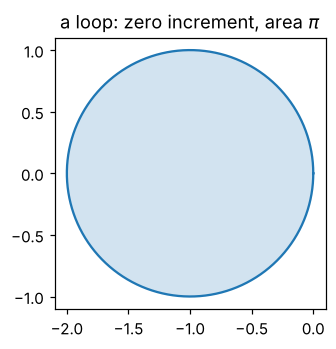

In [3]:
theta = np.linspace(0, 2 * np.pi, 2001)
circle = np.stack([np.cos(theta) - 1, np.sin(theta)], axis=1)        # unit circle through the origin
S = sig_pl(np.diff(circle, axis=0)[None], 3)
area = 0.5 * (coord(S, '12') - coord(S, '21'))[0]
print("increment (level 1):", np.round(S[0][0], 12))
print(f"Lévy area: {area:.6f}   (area of the unit disc: pi = {np.pi:.6f})")

fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.fill(circle[:, 0], circle[:, 1], alpha=0.2)
ax.plot(circle[:, 0], circle[:, 1])
ax.set_aspect("equal"); ax.set_title("a loop: zero increment, area $\\pi$")
plt.show()

## 0.2 Computing the signature of a piecewise-linear path

Two facts make the computation exact and fast.

1. **A straight segment** with increment $v$ has the signature
   $\exp(v)=1+v+\frac{v^{\otimes2}}{2!}+\frac{v^{\otimes3}}{3!}+\cdots$ (the tensor exponential), because
   the iterated integral of a constant velocity over the simplex $\{t_1<\dots<t_m\}$ is $v^{\otimes m}/m!$.
2. **Chen's identity.** The signature of a concatenation is the tensor product of the signatures:
   $\mathrm{Sig}(x*y)=\mathrm{Sig}(x)\otimes\mathrm{Sig}(y)$.

So the signature of a piecewise-linear path with increments $v_1,\dots,v_n$ is
$\exp(v_1)\otimes\cdots\otimes\exp(v_n)$. The function `sig_pl` of the core library multiplies these
factors level by level. We test it on three facts that hold for every path.

* **The L-shaped path** "$e_1$, then $e_2$" has $\langle12,\mathrm{Sig}\rangle=1$ and
  $\langle21,\mathrm{Sig}\rangle=0$, so its Lévy area is $\tfrac12$, not $1$.
* **The shuffle identity**: products of coordinates are linear combinations of coordinates,
  $\langle u,\mathrm{Sig}\rangle\langle v,\mathrm{Sig}\rangle=\langle u\shuffle v,\mathrm{Sig}\rangle$. For
  example $\langle12\rangle\langle12\rangle=2\langle1212\rangle+4\langle1122\rangle$.
* **Refining a segment changes nothing**: cutting a straight segment into pieces gives the same signature.

In [4]:
L_path = np.array([[[1.0, 0.0], [0.0, 1.0]]])
S = sig_pl(L_path, 2)
print("L-shaped path: <12> =", coord(S, '12')[0], " <21> =", coord(S, '21')[0],
      " Lévy area =", 0.5 * (coord(S, '12') - coord(S, '21'))[0])

rng = np.random.default_rng(1)
inc = 0.4 * rng.standard_normal((3, 6, 2))
S = sig_pl(inc, 4)
lhs = coord(S, '12') * coord(S, '12')
rhs = sum(coord(S, w) for w in shuffle('12', '12'))
print("shuffle  <12><12> = <12 sh 12>:", np.allclose(lhs, rhs),
      "  (12 sh 12 =", "+".join(sorted(shuffle('12', '12'))), ")")

v = np.array([[[0.3, -0.5]]])
pieces = np.repeat(v / 5, 5, axis=1)
print("one segment vs the same segment in 5 pieces:",
      all(np.allclose(a, b) for a, b in zip(sig_pl(v, 4), sig_pl(pieces, 4))))

L-shaped path: <12> = 1.0  <21> = 0.0  Lévy area = 0.5
shuffle  <12><12> = <12 sh 12>: True   (12 sh 12 = 1122+1122+1122+1122+1212+1212 )
one segment vs the same segment in 5 pieces: True


For a smooth path the signature of the piecewise-linear interpolant converges to the signature of the
path as the mesh is refined. For the circle of Section 0.1, the error of the Lévy area is of order $\delta^2$:

In [5]:
for n in [8, 16, 32, 64, 128]:
    th = np.linspace(0, 2 * np.pi, n + 1)
    c = np.stack([np.cos(th) - 1, np.sin(th)], axis=1)
    S = sig_pl(np.diff(c, axis=0)[None], 2)
    a = 0.5 * (coord(S, '12') - coord(S, '21'))[0]
    print(f"n = {n:4d}   area = {a:.8f}   error = {np.pi - a:.2e}   error * n^2 = {(np.pi - a) * n**2:.3f}")

n =    8   area = 2.82842712   error = 3.13e-01   error * n^2 = 20.043
n =   16   area = 3.06146746   error = 8.01e-02   error * n^2 = 20.512
n =   32   area = 3.12144515   error = 2.01e-02   error * n^2 = 20.631
n =   64   area = 3.13654849   error = 5.04e-03   error * n^2 = 20.661
n =  128   area = 3.14033116   error = 1.26e-03   error * n^2 = 20.668


## 0.3 Expected signatures

For a random path $X$ the **expected signature** $\mathbb E[\mathrm{Sig}(X)]$ collects the expectations of
all iterated integrals. Under a growth condition it determines the law of the signature, which is why
it is used as a feature of time series. For $d$-dimensional Brownian motion on $[0,1]$
(Stratonovich integrals) it is known exactly:
$$
\mathbb E[\mathrm{Sig}(B)]=\exp\Bigl(\tfrac12\sum_{i=1}^d e_i\otimes e_i\Bigr),
$$
so for example $\mathbb E\langle11\rangle=\tfrac12$, $\mathbb E\langle1122\rangle=\tfrac18$, and every word
with a letter of odd multiplicity has expectation $0$. A Monte Carlo check with fine piecewise-linear
paths:

In [6]:
rng = np.random.default_rng(2)
N, n = 20000, 200
inc = fbm_increments(0.5, n, N, d=2, rng=rng)        # H = 1/2: Brownian increments
S = sig_pl(inc, 4)
E = expected_sig_bm(2, 4)
for w in ['11', '12', '1122', '1212', '1221', '1111']:
    mc = coord(S, w)
    exact = E[len(w) - 1][tuple(int(c) - 1 for c in w)]
    print(f"<{w}>:  Monte Carlo {mc.mean():+.4f} ± {2 * mc.std() / np.sqrt(N):.4f}    exact {exact:+.4f}")

<11>:  Monte Carlo +0.4990 ± 0.0098    exact +0.5000
<12>:  Monte Carlo -0.0037 ± 0.0100    exact +0.0000
<1122>:  Monte Carlo +0.1233 ± 0.0040    exact +0.1250
<1212>:  Monte Carlo +0.0013 ± 0.0028    exact +0.0000
<1221>:  Monte Carlo +0.0008 ± 0.0036    exact +0.0000
<1111>:  Monte Carlo +0.1209 ± 0.0051    exact +0.1250


## 0.4 Discretization: the weak and the strong error

In practice a path is observed only at the mesh points $t_a=a\delta$, $\delta=1/n$, and one computes the
signature of the piecewise-linear interpolant $X^n$. The papers study two measures of the loss:

* the **weak error** $\mathcal W=\mathbb E[\mathrm{Sig}^{\le M}(X^n)]-\mathbb E[\mathrm{Sig}^{\le M}(X)]$, the
  difference of the expected signatures;
* the **strong error** $\eta_\delta=\bigl(\mathbb E\lVert\mathrm{Sig}^{\le M}(X^n)-\mathrm{Sig}^{\le M}(X)\rVert^2\bigr)^{1/2}$.

The drivers are fractional Brownian motions (fBm) with Hurst index $H$: rougher than Brownian motion for
$H<\tfrac12$, smoother for $H>\tfrac12$.

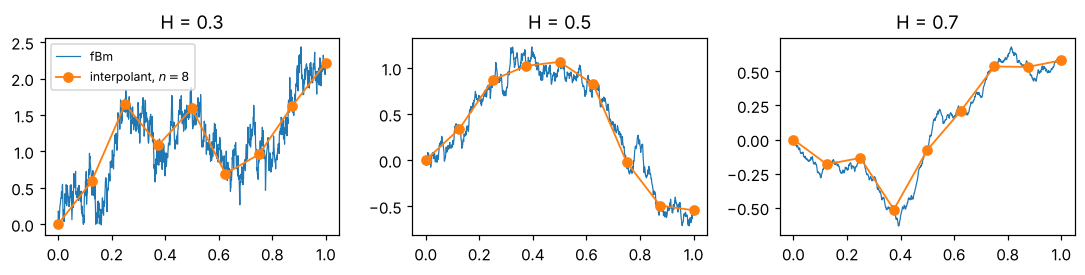

In [7]:
rng = np.random.default_rng(3)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=False)
for ax, H in zip(axes, [0.3, 0.5, 0.7]):
    fine = fbm_increments(H, 1024, 1, d=1, rng=rng)[0, :, 0]
    path = np.concatenate([[0], np.cumsum(fine)])
    coarse = path[::128]
    ax.plot(np.linspace(0, 1, 1025), path, lw=0.8, label="fBm")
    ax.plot(np.linspace(0, 1, 9), coarse, "o-", lw=1.2, label="interpolant, $n=8$")
    ax.set_title(f"H = {H}")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Where the error sits at level 2.** On each cell the interpolant is a straight line, so its Lévy area
over the cell is zero, while the path has a cell area $A_a$. Chen's identity shows that the level-2
coordinate $\langle12\rangle$ of the interpolant differs from that of the path by exactly the sum of the
cell areas: $\langle12,\mathrm{Sig}(X)-\mathrm{Sig}(X^n)\rangle=\sum_aA_a$. We check this identity on one
sampled path (with a fine piecewise-linear path in place of $X$):

In [8]:
rng = np.random.default_rng(4)
n_fine, n = 1024, 16
k = n_fine // n
inc_fine = fbm_increments(0.3, n_fine, 1, d=2, rng=rng)
inc_coarse = inc_fine.reshape(1, n, k, 2).sum(axis=2)
S_fine, S_coarse = sig_pl(inc_fine, 2), sig_pl(inc_coarse, 2)
cell_areas = []
for a in range(n):
    Sa = sig_pl(inc_fine[:, a * k:(a + 1) * k], 2)
    cell_areas.append(0.5 * (coord(Sa, '12') - coord(Sa, '21'))[0])
print("<12, Sig(X) - Sig(X^n)> =", (coord(S_fine, '12') - coord(S_coarse, '12'))[0])
print("sum of the cell areas    =", np.sum(cell_areas))

<12, Sig(X) - Sig(X^n)> = -0.05934503906862523
sum of the cell areas    = -0.059345039068624206


**The strong error.** The cell areas have mean zero and are of size $\delta^{2H}$, and there are $n$ of
them. For $H\in(\tfrac12,1)$ their covariances decay fast enough for the sum to behave like a sum of
independent terms, so the mean-square strong error is of order $n\delta^{4H}=\delta^{4H-1}$. A Monte
Carlo estimate against a fine reference (an illustration, with sampling error):

H = 0.7: fitted mean-square slope 1.83   (theory: 4H - 1 = 1.80)


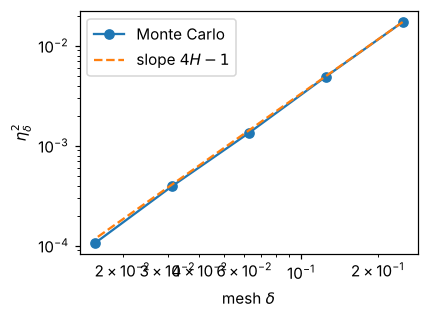

In [9]:
rng = np.random.default_rng(5)
H, n_fine, N = 0.7, 512, 3000
ns = [4, 8, 16, 32, 64]
inc_fine = fbm_increments(H, n_fine, N, d=2, rng=rng)
S_ref = sig_pl(inc_fine, 2)
mse = []
for n in ns:
    inc_c = inc_fine.reshape(N, n, n_fine // n, 2).sum(axis=2)
    S_c = sig_pl(inc_c, 2)
    err = sum(((a - b) ** 2).reshape(N, -1).sum(1) for a, b in zip(S_ref, S_c))
    mse.append(err.mean())
slope = np.polyfit(np.log(1 / np.array(ns)), np.log(mse), 1)[0]
print(f"H = {H}: fitted mean-square slope {slope:.2f}   (theory: 4H - 1 = {4 * H - 1:.2f})")
plt.figure(figsize=(4, 3))
plt.loglog(1 / np.array(ns), mse, "o-", label="Monte Carlo")
plt.loglog(1 / np.array(ns), mse[0] * (np.array(ns[0]) / np.array(ns)) ** (4 * H - 1), "--",
           label="slope $4H-1$")
plt.xlabel("mesh $\\delta$"); plt.ylabel("$\\eta_\\delta^2$"); plt.legend(); plt.tight_layout(); plt.show()

**The weak error is much smaller.** The areas have mean zero, so they do not shift the expected
signature at level 2; the weak error first appears at level 4. For Brownian motion it can be computed
exactly. The increments over the cells are independent Gaussian vectors, so by Chen's identity
$\mathbb E[\mathrm{Sig}(X^n)]=\bigl(\mathbb E\exp(\Delta)\bigr)^{\otimes n}$, with $\Delta\sim N(0,\delta I_d)$.
Comparing with $\exp(\tfrac12\sum_ie_i\otimes e_i)$ gives, for the three level-4 words with two letters
$1$ and two letters $2$,
$$
\Delta E_{\rm adj},\ \Delta E_{\rm alt},\ \Delta E_{\rm nest}\;=\;\Bigl(-\frac{\delta}{12},\ \frac{\delta}{24},\ \frac{\delta}{24}\Bigr)
\quad\text{for the words }1122,\ 1212,\ 1221,
$$
exactly on every mesh. In mean square the weak error is $\delta^2$, against $\delta$ for the strong
error: a full power of $\delta$ smaller. The next cell computes this in a few lines.

In [10]:
def gauss_exp_moments(delta, d, M):
    """E[exp(Delta)] truncated at level M, Delta ~ N(0, delta I_d): only even levels survive."""
    levels = [np.zeros((d,) * m) for m in range(1, M + 1)]
    # E[Delta^{⊗m}] / m!, with the Gaussian moments computed by Isserlis' theorem.
    for m in range(2, M + 1, 2):
        T = np.zeros((d,) * m)
        for idx in itertools.product(range(d), repeat=m):
            # Isserlis: sum over pairings of the product of delta * 1{i_p = i_q}
            def pairings(lst):
                if not lst:
                    yield 1.0
                    return
                a = lst[0]
                for i in range(1, len(lst)):
                    if idx[a] == idx[lst[i]]:
                        for rest in pairings(lst[1:i] + lst[i + 1:]):
                            yield delta * rest
            T[idx] = sum(pairings(list(range(m))))
        levels[m - 1] = T / factorial(m)
    return levels


def tensor_mult(X, Y, M):
    """Product of two truncated tensor series given as lists of levels 1..M (level 0 equal to 1)."""
    out = []
    for m in range(1, M + 1):
        acc = X[m - 1] + Y[m - 1]
        for k in range(1, m):
            acc = acc + np.multiply.outer(X[k - 1], Y[m - k - 1])
        out.append(acc)
    return out


d, M = 2, 4
E_B = expected_sig_bm(d, M)
for n in [1, 2, 5, 10, 50]:
    delta = 1.0 / n
    one = gauss_exp_moments(delta, d, M)
    E_n = one
    for _ in range(n - 1):
        E_n = tensor_mult(E_n, one, M)
    dE = [(E_n[3] - E_B[3])[tuple(int(c) - 1 for c in w)] for w in ['1122', '1212', '1221']]
    print(f"n = {n:3d}:  dE / delta = {np.round(np.array(dE) / delta, 12)}"
          f"   (exact: -1/12 = {-1/12:.6f}, 1/24 = {1/24:.6f})")

n =   1:  dE / delta = [-0.08333333  0.04166667  0.04166667]   (exact: -1/12 = -0.083333, 1/24 = 0.041667)
n =   2:  dE / delta = [-0.08333333  0.04166667  0.04166667]   (exact: -1/12 = -0.083333, 1/24 = 0.041667)
n =   5:  dE / delta = [-0.08333333  0.04166667  0.04166667]   (exact: -1/12 = -0.083333, 1/24 = 0.041667)
n =  10:  dE / delta = [-0.08333333  0.04166667  0.04166667]   (exact: -1/12 = -0.083333, 1/24 = 0.041667)
n =  50:  dE / delta = [-0.08333333  0.04166667  0.04166667]   (exact: -1/12 = -0.083333, 1/24 = 0.041667)


For fractional Brownian motion the increments are correlated, and the expected signature of the
interpolant is a sum over Wick pairings of products of increment covariances. The papers show that
the weak error is of order $\delta^{\min(2H,\,4H-1)}$ and compute its leading constants. Parts A–C
reproduce the numerical values quoted in Paper I.

# Part A. The weak error on the Young range and the level structure (Section 5)

This part reproduces the numerical statements of Section 5 of the paper (label Section 5):

* **A1** Theorem 5.3(i): the Brownian level-4 weak error, exact on every mesh.
* **A2** Proposition 5.14 and Remark 5.13(i): the leading constants
  $(-\tfrac1{12},\tfrac16,-\tfrac1{12})$ and $\mathcal B=1/(2\sqrt3)$ for $H\in(\tfrac12,1)$.
* **A3** Remark 5.6: the double-error terms $T_3^\bullet$ and their exact order $\delta^{4H-1}$.
* **A4** Remark 5.13: which words carry the relative error $\delta^{2H-1}$ and which only
  $\delta^{2-2H}$.
* **A5** Proposition 5.18 and the paragraph "A numerical check" after its proof: the level-3
  drift bias for fBm and for sums of independent fBms.

Nothing in this part is Monte Carlo except one clearly labelled sanity check in A5. All other values are
exact finite sums (Chen's identity for piecewise-linear paths, Wick/Isserlis pairings, closed-form cell
integrals), evaluated in floating point. Throughout, $d=2$, $\delta=1/n$, cells $I_a=[t_a,t_{a+1})$,
components with $\mathrm{Var}(X^i_1)=1$, and $\Delta E_\bullet=E^n_\bullet-E_\bullet$ for the words
$1122$ (adj), $1212$ (alt), $1221$ (nest).

**Modes.** `QUICK = True` uses meshes up to $n=2048$ and runs in well under a minute. `QUICK = False`
uses meshes up to $n=16384$ and takes about two minutes. Both modes recompute everything; nothing is
precomputed.

In [11]:
QUICK = globals().get("QUICK", True)
import mpmath as mp
from fractions import Fraction

A_T0 = time.time()
A_LD = np.longdouble                      # 80-bit extended precision on x86-64 (Colab); see the note below
A_NS = [2 ** k for k in range(3, 12 if QUICK else 15)]   # meshes n = 8, ..., 2048 (QUICK) or 16384 (FULL)
A_HS = (0.6, 0.7, 0.8)
mp.mp.dps = 30
print("Part A mode:", "QUICK" if QUICK else "FULL", "| meshes n =", A_NS[0], "...", A_NS[-1])
if np.finfo(A_LD).eps >= np.finfo(float).eps:
    print("note: numpy longdouble has only double precision on this machine; the double-error terms of A3"
          " lose a few digits on the finest meshes (the leading digits printed below are unaffected).")


def a_status(ok):
    return "OK" if ok else "MISMATCH"

Part A mode: QUICK | meshes n = 8 ... 2048


## A.0 The exact evaluators

**Level-4 coordinates of the interpolant.** For the piecewise-linear interpolant $X^n$, Chen's identity
gives $\langle w,\mathrm{Sig}(X^n)\rangle=\sum_{a_1\le\dots\le a_4}c_{\mathbf a}\prod_l\Delta^{w_l}_{a_l}$
(equation eq. (8)), with $c_{\mathbf a}=\prod_b 1/k_b(\mathbf a)!$. For a $(2,2)$-word, independence
and Wick's theorem leave one pairing, so
$E^n_\bullet=\delta^{4H}\sum_{a_1\le a_2\le a_3\le a_4}c_{\mathbf a}\,r(|a_i-a_j|)\,r(|a_k-a_l|)$, where
$\{i,j\},\{k,l\}$ are the Wick pairs and $r$ is the fGn autocovariance. The function `a_En` evaluates this
sum exactly in $O(n^2)$ operations: it loops over the two middle cells $a_2\le a_3$ and sums over $a_1$
and $a_4$ with cumulative sums. It is checked against the literal $O(n^4)$ sum (`a_En_brute`) on tiny
meshes.

**Continuum values.** For $H\in(\tfrac12,1)$, with $p=2H$ and $c_H=H(2H-1)$, integrating the kernel
$\varrho(s,t)=c_H|t-s|^{2H-2}$ against the weights of Lemma 5.10 gives
$E_{\rm adj}=\tfrac{H}{2}B(p,p+1)$, $E_{\rm nest}=c_H/(4p(2p-1))$ and
$E_{\rm alt}=\tfrac{c_H}2\bigl[\tfrac1{2p(p-1)}-\tfrac{B(p,p+1)}{p-1}-\tfrac1{2p(2p-1)}\bigr]$.
Their sum must be $\tfrac18$ (Lemma 5.16), which the code checks.

**Mixed terms, for the double error.** Writing $\varrho^n=\varrho+e$ splits
$\Delta E_\bullet=T_P+T_{P'}+T_3^\bullet$ (equation eq. (13)), where $P,P'$ are the two Wick pairs,
$T_P=\int_{s<t}e\,w_P$ is a single-error term with the weight $w_P$ of Lemma 5.10, and
$T_3^\bullet$ is the double-error term of Corollary 5.5. Since $\int_{s<t}\varrho\,w_P=E_\bullet$,
one has $T_P=M_P-E_\bullet$ with the mixed term $M_P=\int_{s<t}\varrho^n w_P$, and hence
$T_3^\bullet=E^n_\bullet+E_\bullet-M_P-M_{P'}$. Each weight is a combination of $1$, $s^p$, $t^p$, $(1-s)^p$,
$(1-t)^p$, $(t-s)^p$, and $\varrho^n=\delta^{2H-2}r(m)$ on the cells of lag $m$, so $M_P$ is an exact
$O(n)$ sum of closed-form cell integrals (`a_M`). These are checked against two-dimensional quadrature on
a tiny mesh.

**Floating point.** $T_3^\bullet$ is of order $\delta^{4H-1}$ but is a difference of numbers of order one,
and the second differences $(m+1)^q-2m^q+(m-1)^q$ cancel badly for large $m$. The code therefore evaluates
such differences by their binomial series for $m\ge8$ and runs all sums in `numpy.longdouble`. The check
below compares double and extended precision.

In [12]:
def a_binom_coeffs(q, K):
    """Generalized binomial coefficients C(q, j), j = 0..K, in 40-digit arithmetic."""
    with mp.workdps(40):
        c = [mp.mpf(1)]
        for j in range(1, K + 1):
            c.append(c[-1] * (mp.mpf(q) - j + 1) / j)
    return c


def a_d2(q, m, dtype=float):
    """(m+1)^q - 2 m^q + |m-1|^q for integers m >= 0; binomial series for m >= 8 (no cancellation)."""
    m = np.asarray(m)
    out = np.empty(m.shape, dtype=dtype)
    q_ = dtype(q)
    small = m < 8
    ms = m[small].astype(dtype)
    out[small] = (ms + 1) ** q_ - 2 * ms ** q_ + np.abs(ms - 1) ** q_
    mb = m[~small].astype(dtype)
    if mb.size:
        c = a_binom_coeffs(q, 40)
        x2 = (1 / mb) ** 2
        s = np.zeros_like(mb)
        for k in range(18, 0, -1):                     # 2 m^q sum_k C(q,2k) m^{-2k}, Horner in m^{-2}
            s = (s + dtype(str(c[2 * k]))) * x2
        out[~small] = 2 * mb ** q_ * s
    return out


def a_d1(q, m, dtype=float):
    """(m+1)^q - (m-1)^q for integers m >= 1; binomial series for m >= 8."""
    m = np.asarray(m)
    out = np.empty(m.shape, dtype=dtype)
    q_ = dtype(q)
    small = m < 8
    ms = m[small].astype(dtype)
    out[small] = (ms + 1) ** q_ - np.abs(ms - 1) ** q_
    mb = m[~small].astype(dtype)
    if mb.size:
        c = a_binom_coeffs(q, 41)
        x = 1 / mb
        s = np.zeros_like(mb)
        for k in range(18, -1, -1):
            s = s * x * x + dtype(str(c[2 * k + 1]))
        out[~small] = 2 * mb ** q_ * s * x
    return out


def a_r(H, kmax, dtype=float):
    """fGn autocovariance r(k) = (|k+1|^{2H} - 2|k|^{2H} + |k-1|^{2H})/2, k = 0..kmax (stable)."""
    return a_d2(2 * H, np.arange(kmax + 1), dtype) / 2


def a_En(word, H, n, dtype=A_LD):
    """E_word(X^n), word in {'adj','alt','nest'}, independent fBm(H), Var(X_1) = 1, mesh 1/n.
    Exact Chen-Wick sum over a1<=a2<=a3<=a4, with the sums over a1 and a4 done by cumulative sums."""
    r = a_r(H, n + 1, dtype)
    r0 = r[0]
    Cs = np.concatenate([np.zeros(1, dtype=dtype), np.cumsum(r)])      # Cs[k] = sum_{i<k} r(i)
    CC = np.concatenate([np.zeros(1, dtype=dtype), np.cumsum(Cs)])     # CC[k] = sum_{i<k} Cs[i]
    tot = dtype(0)
    for m in range(n):                                                  # m = a3 - a2
        a2 = np.arange(n - m)
        a3 = a2 + m
        if word == "adj":                                               # pairs {1,2},{3,4}
            S1 = Cs[a2 + 1] - r0                                        # sum_{a1<a2} r(a2-a1)
            T = Cs[n - a3] - r0                                         # sum_{a4>a3} r(a4-a3)
            v = (S1 + r0 / 2) * (T + r0 / 2) if m else S1 / 2 * (T + r0 / 3) + r0 / 6 * (T + r0 / 4)
        elif word == "alt":                                             # pairs {1,3},{2,4}
            S1 = Cs[a3 + 1] - Cs[m + 1]                                 # sum_{a1<a2} r(a3-a1)
            T = Cs[n - a2] - Cs[m + 1]                                  # sum_{a4>a3} r(a4-a2)
            v = (S1 + r[m] / 2) * (T + r[m] / 2) if m else S1 / 2 * (T + r0 / 3) + r0 / 6 * (T + r0 / 4)
        else:                                                           # nest: pairs {1,4},{2,3}
            sumTail = (CC[n + 1] - CC[n - a2 + 1]) - (CC[a3 + 2] - CC[m + 2])   # sum_{a1<a2, a4>a3} r(a4-a1)
            sumR = Cs[a3 + 1] - Cs[m + 1]                                        # sum_{a1<a2} r(a3-a1)
            T = Cs[n - a2] - Cs[m + 1]                                           # sum_{a4>a3} r(a4-a2)
            if m:
                v = r[m] * (sumTail + sumR / 2) + r[m] / 2 * (T + r[m] / 2)
            else:
                v = r0 * ((sumTail + sumR / 3) / 2 + (T + r0 / 4) / 6)
        tot += np.sum(v)
    return tot * (1 / dtype(n)) ** (4 * dtype(H))


def a_En_brute(word, H, n):
    """Reference: the literal O(n^4) Chen-Wick sum of eq. (8), c_a = prod_b 1/k_b(a)!."""
    pairs = {"adj": ((0, 1), (2, 3)), "alt": ((0, 2), (1, 3)), "nest": ((0, 3), (1, 2))}[word]
    r = fgn_autocov(np.arange(n + 1), H) * (1.0 / n) ** (2 * H)
    tot = 0.0
    for a in itertools.combinations_with_replacement(range(n), 4):
        c = 1.0
        for b in set(a):
            c /= factorial(a.count(b))
        (i, j), (k, l) = pairs
        tot += c * r[abs(a[j] - a[i])] * r[abs(a[l] - a[k])]
    return tot


def a_Econt(H):
    """(E_adj, E_alt, E_nest) of independent fBm(H), H in (1/2,1), closed form in mpmath."""
    H = mp.mpf(H)
    p, cH = 2 * H, H * (2 * H - 1)
    Eadj = H / 2 * mp.beta(p, p + 1)
    Enest = cH / (4 * p * (2 * p - 1))
    Ealt = cH / 2 * (1 / (2 * p * (p - 1)) - mp.beta(p, p + 1) / (p - 1) - 1 / (2 * p * (2 * p - 1)))
    return Eadj, Ealt, Enest


def a_J(p, a, kind, dtype=A_LD):
    """int_0^1 (a+u)^p (1-u) du (kind 1) or int_0^1 (a+u)^p u du (kind 2), integers a >= 0; series for a >= 8."""
    a = np.asarray(a)
    out = np.empty(a.shape, dtype=dtype)
    p_ = dtype(p)
    small = a < 8
    x = a[small].astype(dtype)
    A_ = lambda y: y ** (p_ + 1) / (p_ + 1)
    B_ = lambda y: y ** (p_ + 2) / ((p_ + 1) * (p_ + 2))
    out[small] = B_(x + 1) - B_(x) - A_(x) if kind == 1 else A_(x + 1) - (B_(x + 1) - B_(x))
    xb = a[~small].astype(dtype)
    if xb.size:
        c = a_binom_coeffs(p, 30)
        s = np.zeros_like(xb)
        for j in range(28, -1, -1):
            cj = c[j] / ((j + 1) * (j + 2)) if kind == 1 else c[j] / (j + 2)
            s = s / xb + dtype(str(cj))
        out[~small] = xb ** p_ * s
    return out


# the six weights of Lemma 5.10, as coefficients of [1, s^p, t^p, (1-s)^p, (1-t)^p, (t-s)^p]
A_WEIGHTS = {
    ("adj", "12"): (0, 0, 0, 0, .5, 0), ("adj", "34"): (0, .5, 0, 0, 0, 0),
    ("alt", "13"): (0, 0, 0, .5, -.5, -.5), ("alt", "24"): (0, -.5, .5, 0, 0, -.5),
    ("nest", "14"): (0, 0, 0, 0, 0, .5), ("nest", "23"): (.5, 0, -.5, -.5, 0, .5),
}
A_PAIRS = {"adj": ("12", "34"), "alt": ("13", "24"), "nest": ("14", "23")}
A_WORDS = ("adj", "alt", "nest")


def a_Selem(H, n, dtype=A_LD):
    """S[j, m] = sum over the pieces Q_{a,a+m} = (I_a x I_{a+m}) cap {s<t} of int g_j, for m = 0..n-1."""
    p, nn = dtype(2 * H), dtype(n)
    d = 1 / nn
    m = np.arange(n)
    mf = m.astype(dtype)
    S = np.zeros((6, n), dtype=dtype)
    S[0, 1:] = (nn - mf[1:]) * d * d
    S[1, 1:] = d ** (p + 2) * (nn - mf[1:]) ** (p + 1) / (p + 1)
    S[2, 1:] = d ** (p + 2) * (nn ** (p + 1) - mf[1:] ** (p + 1)) / (p + 1)
    S[5, 1:] = (nn - mf[1:]) * d ** (p + 2) * a_d2(2 * H + 2, m[1:], dtype) / ((p + 1) * (p + 2))
    S[0, 0] = nn * d * d / 2                                           # lag 0: upper halves of diagonal cells
    S[1, 0] = d ** (p + 2) * np.sum(a_J(2 * H, m, 1, dtype))
    S[2, 0] = d ** (p + 2) * np.sum(a_J(2 * H, m, 2, dtype))
    S[5, 0] = nn * d ** (p + 2) / ((p + 1) * (p + 2))
    S[3], S[4] = S[2], S[1]                       # reflection (s,t) -> (1-t,1-s) of the uniform mesh
    return S


def a_M(H, n, dtype=A_LD):
    """Mixed terms M_P = int_{s<t} rho^n(s,t) w_P(s,t) ds dt for the six weights."""
    r = a_r(H, n, dtype)[:n]
    S = a_Selem(H, n, dtype)
    pre = (1 / dtype(n)) ** (dtype(2 * H) - 2)
    return {key: pre * np.sum(r * sum(dtype(c) * S[j] for j, c in enumerate(coef)))
            for key, coef in A_WEIGHTS.items()}


def a_level4(H, n, dtype=A_LD):
    """For each word: (Delta E, T_P, T_P', T_3) on the mesh 1/n (exact up to rounding)."""
    E = a_Econt(H)
    M = a_M(H, n, dtype)
    out = {}
    for w, Ew in zip(A_WORDS, E):
        Ew = dtype(mp.nstr(Ew, 25))
        En = a_En(w, H, n, dtype)
        P, Q = A_PAIRS[w]
        out[w] = (En - Ew, M[(w, P)] - Ew, M[(w, Q)] - Ew, En + Ew - M[(w, P)] - M[(w, Q)])
    return out

**Validation of the evaluators.** (i) `a_En` against the literal $O(n^4)$ Chen–Wick sum for
$n\le7$, at $H=0.5,0.6,0.8$. (ii) The closed-form weights of Lemma 5.10 against direct
integration of $\varrho$ over the two free times at random points (inner integral of the power in closed
form, outer integral by adaptive quadrature). (iii) The cell sums $S$ behind `a_M`
against two-dimensional quadrature on the mesh $n=3$. (iv) The continuum values sum to $\tfrac18$.
(v) Double against extended precision for $T_3^\bullet$ at $n=256$.

In [13]:
from scipy.integrate import dblquad

a_ok = True
for H in (0.5, 0.6, 0.8):
    for n in (1, 2, 3, 5, 7):
        for w in A_WORDS:
            a_ok &= abs(float(a_En(w, H, n)) - a_En_brute(w, H, n)) < 1e-14
print("(i)   O(n^2) evaluator = O(n^4) Chen-Wick sum for n <= 7:", a_status(a_ok))

from scipy.integrate import quad

rng_ = np.random.default_rng(0)
a_ok = True
for H in (0.6, 0.8):
    p = 2 * H
    # int_a^b rho(x, y) dy for x <= a < b, with rho(x, y) = c_H (y-x)^{2H-2} and c_H/(2H-1) = H
    inner = lambda x, a, b: H * ((b - x) ** (p - 1) - (a - x) ** (p - 1))
    oq = lambda f, lo, hi: quad(f, lo, hi, epsabs=1e-14, epsrel=1e-13, limit=200)[0]
    for _ in range(3):
        s, t = np.sort(rng_.uniform(0.05, 0.95, 2))
        # the exact factor sits on the other pair; integrate it over the two times allowed by the ordering
        ref = {("adj", "12"): oq(lambda x: inner(x, x, 1), t, 1),        # t < t3 < t4 < 1
               ("adj", "34"): oq(lambda x: inner(x, x, s), 0, s),        # 0 < t1 < t2 < s
               ("alt", "13"): oq(lambda x: inner(x, t, 1), s, t),        # t2 in (s,t), t4 in (t,1)
               ("alt", "24"): oq(lambda x: inner(x, s, t), 0, s),        # t1 in (0,s), t3 in (s,t)
               ("nest", "14"): oq(lambda x: inner(x, x, t), s, t),       # s < t2 < t3 < t
               ("nest", "23"): oq(lambda x: inner(x, t, 1), 0, s)}       # t1 in (0,s), t4 in (t,1)
        g = [1, s ** p, t ** p, (1 - s) ** p, (1 - t) ** p, (t - s) ** p]
        for key, coef in A_WEIGHTS.items():
            a_ok &= abs(sum(c * gj for c, gj in zip(coef, g)) - ref[key]) < 1e-11
print("(ii)  closed-form weights of Lemma 5.10 = direct integration:", a_status(a_ok))

a_ok = True
for H in (0.6, 0.8):
    n, p = 3, 2 * H
    S = a_Selem(H, n)
    gs = [lambda s, t: 1.0, lambda s, t: s ** p, lambda s, t: t ** p, lambda s, t: (1 - s) ** p,
          lambda s, t: (1 - t) ** p, lambda s, t: (t - s) ** p]
    for j, g in enumerate(gs):
        for m in range(n):
            tot = 0.0
            for a in range(n - m):
                lo = (lambda s: s) if m == 0 else (a + m) / n
                tot += dblquad(lambda t, s: g(s, t), a / n, (a + 1) / n, lo, (a + m + 1) / n,
                               epsabs=1e-14, epsrel=1e-13)[0]
            a_ok &= abs(tot - float(S[j, m])) < 1e-12
print("(iii) cell sums of the mixed terms = 2-d quadrature (n = 3):", a_status(a_ok))

a_ok = all(abs(sum(a_Econt(H)) - mp.mpf(1) / 8) < 1e-25 for H in A_HS)
print("(iv)  E_adj + E_alt + E_nest = 1/8 (Lemma 5.16) at H = 0.6, 0.7, 0.8:", a_status(a_ok))

a_ok = True
for H in (0.6, 0.8):
    x, y = a_level4(H, 256, float), a_level4(H, 256, A_LD)
    rel = max(abs(float((x[w][3] - y[w][3]) / y[w][3])) for w in ("alt", "nest"))
    a_ok &= rel < 1e-6
    print(f"(v)   H={H}, n=256: relative difference of T_3 in double vs extended precision = {rel:.1e}")
print("(v)   double and extended precision agree:", a_status(a_ok))

(i)   O(n^2) evaluator = O(n^4) Chen-Wick sum for n <= 7: OK
(ii)  closed-form weights of Lemma 5.10 = direct integration: OK
(iii) cell sums of the mixed terms = 2-d quadrature (n = 3): OK
(iv)  E_adj + E_alt + E_nest = 1/8 (Lemma 5.16) at H = 0.6, 0.7, 0.8: OK
(v)   H=0.6, n=256: relative difference of T_3 in double vs extended precision = 1.0e-11


(v)   H=0.8, n=256: relative difference of T_3 in double vs extended precision = 2.4e-09
(v)   double and extended precision agree: OK


## A1. Theorem 5.3(i): the Brownian case, exact on every mesh

**Claim** (Theorem 5.3(i)). At $H=\tfrac12$,
$\Delta E_{\rm adj}=-\delta/12$ and $\Delta E_{\rm alt}=\Delta E_{\rm nest}=+\delta/24$, so
$\|\mathcal W_4\|=\delta/(4\sqrt3)$ exactly at $d=2$.

**Method.** For Brownian motion the cell increments $\Delta_0,\dots,\Delta_{n-1}$ are independent, so
by Chen's identity $\mathbb E\,\mathrm{Sig}(X^n)=\mathbb E e^{\Delta_0}\otimes\dots\otimes\mathbb E e^{\Delta_{n-1}}
=(\mathbb E e^{\Delta})^{\otimes n}$. Up to level 4,
$\mathbb E e^{\Delta}=1+\tfrac12\mathbb E[\Delta^{\otimes2}]+\tfrac1{24}\mathbb E[\Delta^{\otimes4}]$ with
$\mathbb E[\Delta^i\Delta^j]=\delta\,1_{i=j}$ and the three Wick pairings at level 4. The code forms the
$n$-fold truncated tensor power in exact rational arithmetic (Python `Fraction`, by repeated squaring) and
subtracts $\mathbb E\,\mathrm{Sig}(B)=\exp(\tfrac12\sum_ie_i\otimes e_i)$. The result is exact, with no
rounding at all. It gives all $2+4+8+16$ coordinates of levels 1 to 4. So the code also checks that
levels 1 to 3 have no weak error (Proposition 5.1), and it computes $\|\mathcal W_4\|$ over all
16 words directly, without using equation eq. (11).

In [14]:
def a_tmul(A, B, M=4):
    """Product in the truncated tensor algebra; elements are dicts word(tuple) -> Fraction."""
    C = {}
    for u, x in A.items():
        for v, y in B.items():
            if len(u) + len(v) <= M:
                C[u + v] = C.get(u + v, 0) + x * y
    return C


def a_tpow(A, n, M=4):
    R, P = {(): Fraction(1)}, A
    while n:
        if n & 1:
            R = a_tmul(R, P, M)
        P = a_tmul(P, P, M)
        n >>= 1
    return R


def a_bm_cell(delta, d=2):
    """E exp(Delta) up to level 4 for a Brownian cell increment with covariance delta * I."""
    A = {(): Fraction(1)}
    for i in range(d):
        A[(i, i)] = delta / 2
    for w in itertools.product(range(d), repeat=4):
        i, j, k, l = w
        mom = delta ** 2 * ((i == j) * (k == l) + (i == k) * (j == l) + (i == l) * (j == k))
        if mom:
            A[w] = mom / 24
    return A


a_ESigB = {(): Fraction(1)}                       # exp(1/2 sum_i e_i e_i), exactly
for i in range(2):
    a_ESigB[(i, i)] = Fraction(1, 2)
    for j in range(2):
        a_ESigB[(i, i, j, j)] = Fraction(1, 8)
# cross-check against core.expected_sig_bm (floating point)
a_lv = expected_sig_bm(2, 4)
assert all(abs(float(a_ESigB.get(w, 0)) - a_lv[3][w]) < 1e-15 for w in itertools.product(range(2), repeat=4))

a_A1_ok = True
a_nlist = list(range(1, 41)) + [1000, 10 ** 6]
for n in a_nlist:
    dl = Fraction(1, n)
    ES = a_tpow(a_bm_cell(dl), n)
    W = {w: ES.get(w, 0) - a_ESigB.get(w, 0)
         for m in range(1, 5) for w in itertools.product(range(2), repeat=m)}
    low_zero = all(W[w] == 0 for w in W if len(w) <= 3)
    dE = (W[(0, 0, 1, 1)], W[(0, 1, 0, 1)], W[(0, 1, 1, 0)])
    norm2 = sum(W[w] ** 2 for w in W if len(w) == 4)
    ok = low_zero and dE == (-dl / 12, dl / 24, dl / 24) and norm2 == dl ** 2 / 48
    a_A1_ok &= ok
    if n in (1, 2, 3, 10, 40, 10 ** 6):
        print(f"n={n:>7}: dE/delta = ({dE[0] / dl}, {dE[1] / dl}, {dE[2] / dl}),"
              f"  ||W_4||^2/delta^2 = {norm2 / dl ** 2},  levels 1-3 zero: {low_zero}")
print(f"paper: dE = (-1/12, 1/24, 1/24) delta, ||W_4|| = delta/(4 sqrt 3) (i.e. ||W_4||^2 = delta^2/48);"
      f" exact rational result for n = 1..40, 1000, 10^6 -> {a_status(a_A1_ok)}")

# the general O(n^2) evaluator of A.0 at H = 1/2 gives the same numbers (floating point)
a_ok = all(abs(float(a_En(w, 0.5, n)) - c - v / n) < 1e-15
           for n in (5, 64, 512) for w, c, v in zip(A_WORDS, (1 / 8, 0, 0), (-1 / 12, 1 / 24, 1 / 24)))
print("cross-check with the Chen-Wick evaluator a_En at H = 1/2 (n = 5, 64, 512):", a_status(a_ok))

n=      1: dE/delta = (-1/12, 1/24, 1/24),  ||W_4||^2/delta^2 = 1/48,  levels 1-3 zero: True
n=      2: dE/delta = (-1/12, 1/24, 1/24),  ||W_4||^2/delta^2 = 1/48,  levels 1-3 zero: True
n=      3: dE/delta = (-1/12, 1/24, 1/24),  ||W_4||^2/delta^2 = 1/48,  levels 1-3 zero: True
n=     10: dE/delta = (-1/12, 1/24, 1/24),  ||W_4||^2/delta^2 = 1/48,  levels 1-3 zero: True
n=     40: dE/delta = (-1/12, 1/24, 1/24),  ||W_4||^2/delta^2 = 1/48,  levels 1-3 zero: True
n=1000000: dE/delta = (-1/12, 1/24, 1/24),  ||W_4||^2/delta^2 = 1/48,  levels 1-3 zero: True
paper: dE = (-1/12, 1/24, 1/24) delta, ||W_4|| = delta/(4 sqrt 3) (i.e. ||W_4||^2 = delta^2/48); exact rational result for n = 1..40, 1000, 10^6 -> OK
cross-check with the Chen-Wick evaluator a_En at H = 1/2 (n = 5, 64, 512): OK


## A2. Proposition 5.14: the leading constants on $(\tfrac12,1)$

**Claim** (Proposition 5.14, and Remark 5.13(i)).
For $H\in(\tfrac12,1)$ and $d=2$, $\delta^{-2H}\Delta E_\bullet\to(-\tfrac1{12},\tfrac16,-\tfrac1{12})$, so
$\mathcal B(H)=\lim\|\mathcal W_4\|/\delta^{2H}=1/(2\sqrt3)$. Near the crossover the alternating and
nested words converge so slowly that a Richardson extrapolation must use the ladder
$\{1,\delta^{2H-1},\delta^{2-2H},\dots\}$.

**Method.** For $H=0.6,0.7,0.8$ the code computes $\Delta E_\bullet=E^n_\bullet-E_\bullet$ exactly (A.0) on
$n=8,16,\dots$ up to 2048 (QUICK) or 16384 (FULL). It then fits, by least squares on the meshes
$n\ge64$ (QUICK: $n\ge32$),
$\delta^{-2H}\Delta E_\bullet\approx C_0+C_1\delta^{2H-1}+C_2\delta^{2-2H}+C_3\delta^{2(2H-1)}+C_4\delta$.
The extrapolated value is $C_0$. The exponents are those of the error terms in Lemma 5.11
($\delta^{4H-1}$ and $\delta^2$, relative to $\delta^{2H}$), the square of the first, and the
$\delta^{2H+1}$ term of Proposition 5.4. The extrapolation is the only step that is not exact.
Its uncertainty is judged by changing the fitting window.

In [15]:
a_t = time.time()
A_DATA = {(H, n): a_level4(H, n) for H in A_HS for n in A_NS}
print(f"exact level-4 data for H = {A_HS}, n = {A_NS[0]}..{A_NS[-1]} computed in {time.time() - a_t:.1f} s")


def a_series(H, w, col=0, scale=None):
    """The scaled sequence col of word w: delta^{-scale} * value, scale = 2H by default."""
    sc = 2 * H if scale is None else scale
    return np.array([float(A_DATA[(H, n)][w][col]) * n ** sc for n in A_NS])


def a_fit(y, exps, nmin, nmax=None):
    ns = np.array(A_NS)
    sel = (ns >= nmin) & (ns <= (nmax or ns[-1]))
    d = 1.0 / ns[sel]
    A = np.array([[di ** e for e in exps] for di in d])
    return np.linalg.lstsq(A, y[sel], rcond=None)[0]


A_TARGET = np.array([-1 / 12, 1 / 6, -1 / 12])
A_B = 1 / (2 * np.sqrt(3))
a_nmin = 32 if QUICK else 256
a_tol = 1e-4 if QUICK else 1e-5
A_C1 = {}
print(f"\nraw values delta^(-2H) dE at n = {A_NS[-1]} and extrapolated constants (fit on n >= {a_nmin}):")
for H in A_HS:
    a, b = 2 * H - 1, 2 - 2 * H
    ladder = [0, a, b, 2 * a, 1]
    raw = [a_series(H, w)[-1] for w in A_WORDS]
    C = np.array([a_fit(a_series(H, w), ladder, a_nmin)[0] for w in A_WORDS])
    C_alt = np.array([a_fit(a_series(H, w), ladder, 2 * a_nmin)[0] for w in A_WORDS])
    A_C1[H] = C
    B = np.sqrt(2 * np.sum(C ** 2))
    ok = np.max(np.abs(C - A_TARGET)) < a_tol and abs(B - A_B) < a_tol
    print(f"H={H}: raw ({raw[0]:+.5f}, {raw[1]:+.5f}, {raw[2]:+.5f})  extrapolated ({C[0]:+.6f}, {C[1]:+.6f}, "
          f"{C[2]:+.6f}) [window n >= {2 * a_nmin}: max change {np.max(np.abs(C - C_alt)):.1e}]")
    print(f"       paper (-0.083333, +0.166667, -0.083333), B = {A_B:.6f}; computed B = {B:.6f}  "
          f"-> {a_status(ok)}")
a_ok = max(abs(sum(float(A_DATA[(H, n)][w][0]) for w in A_WORDS)) for H in A_HS for n in A_NS) < 1e-15
print("sum of the three Delta E vanishes on every mesh (Lemma 5.16):", a_status(a_ok))

exact level-4 data for H = (0.6, 0.7, 0.8), n = 8..2048 computed in 1.7 s

raw values delta^(-2H) dE at n = 2048 and extrapolated constants (fit on n >= 32):
H=0.6: raw (-0.08322, +0.13524, -0.05202)  extrapolated (-0.083334, +0.166648, -0.083313) [window n >= 64: max change 8.0e-06]
       paper (-0.083333, +0.166667, -0.083333), B = 0.288675; computed B = 0.288642  -> OK
H=0.7: raw (-0.08263, +0.15406, -0.07143)  extrapolated (-0.083334, +0.166664, -0.083330) [window n >= 64: max change 1.4e-06]
       paper (-0.083333, +0.166667, -0.083333), B = 0.288675; computed B = 0.288671  -> OK
H=0.8: raw (-0.07968, +0.15219, -0.07251)  extrapolated (-0.083334, +0.166667, -0.083333) [window n >= 64: max change 4.0e-07]
       paper (-0.083333, +0.166667, -0.083333), B = 0.288675; computed B = 0.288676  -> OK
sum of the three Delta E vanishes on every mesh (Lemma 5.16): OK


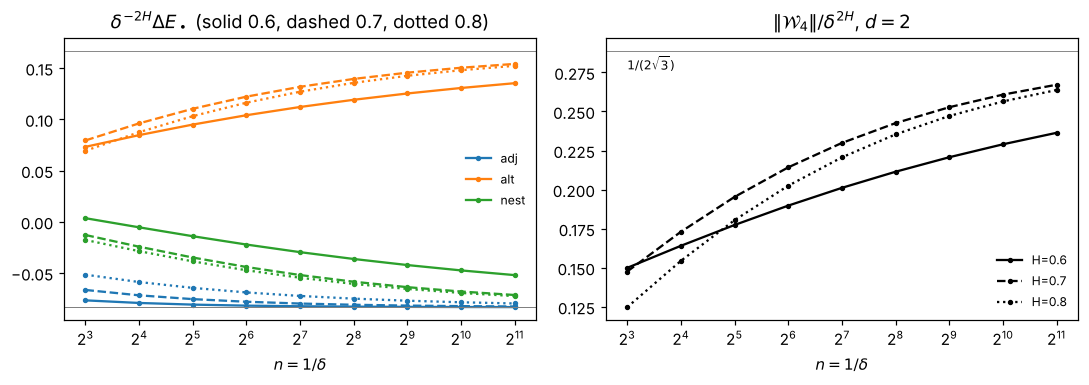

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
cols = {"adj": "C0", "alt": "C1", "nest": "C2"}
for H, ls in zip(A_HS, ("-", "--", ":")):
    for w in A_WORDS:
        axs[0].semilogx(A_NS, a_series(H, w), ls, color=cols[w], marker="o", ms=2.5,
                        label=f"{w}" if H == A_HS[0] else None, base=2)
    W4 = np.sqrt(2 * sum(a_series(H, w) ** 2 for w in A_WORDS))
    axs[1].semilogx(A_NS, W4, ls, color="k", marker="o", ms=2.5, label=f"H={H}", base=2)
for c in A_TARGET:
    axs[0].axhline(c, color="grey", lw=0.6)
axs[1].axhline(A_B, color="grey", lw=0.6)
axs[1].text(A_NS[0], A_B - 0.012, r"$1/(2\sqrt{3})$", fontsize=8)
axs[0].set_title(r"$\delta^{-2H}\Delta E_\bullet$ (solid 0.6, dashed 0.7, dotted 0.8)")
axs[1].set_title(r"$\|\mathcal{W}_4\|/\delta^{2H}$, $d=2$")
for ax in axs:
    ax.set_xlabel(r"$n=1/\delta$")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

The raw sequences are still far from the limits for the alternating and nested words (at $H=0.6$
they have a relative error of order $\delta^{0.2}$). The ladder fit still recovers
$(-\tfrac1{12},\tfrac16,-\tfrac1{12})$ to five digits, and with them $\mathcal B=1/(2\sqrt3)$.

## A3. Remark 5.6: the double-error terms have exact order $\delta^{4H-1}$

**Claim** (Remark 5.6, with Corollary 5.5).
$\sum_\bullet T_3^\bullet=0$ and $T_3^{\rm alt}+T_3^{\rm nest}=-T_3^{\rm adj}=o(\delta^{4H-1})$, and
numerically $T_3^{\rm alt}$ and $T_3^{\rm nest}$ are each of exact order $\delta^{4H-1}$, with opposite
leading coefficients. So the bound eq. (16) is sharp in order.

**Definition used.** $T_3^\bullet=\int_{0<t_1<t_2<t_3<t_4<1}e(t_A)\,e(t_B)$, where $e=\varrho^n-\varrho$ and
$t_A,t_B$ are the two Wick pairs of the word: the $ee$ term of the expansion eq. (13), as written out
in Corollary 5.5.

**Method.** $T_3^\bullet=E^n_\bullet+E_\bullet-M_P-M_{P'}$, exactly (A.0). The code fits
$\delta^{-(4H-1)}T_3^\bullet\approx\kappa_3^\bullet+c_1\delta+c_2\delta^{2H}$ on $n\ge64$ and prints the
fitted coefficients $\kappa_3^\bullet$, also for the fit restricted to $n\le512$.

In [17]:
A_K3 = {}
for H in A_HS:
    yA, yN, yJ = a_series(H, "alt", 3, 4 * H - 1), a_series(H, "nest", 3, 4 * H - 1), a_series(H, "adj", 3, 4 * H - 1)
    kA = a_fit(yA, [0, 1, 2 * H], 64)[0]
    kN = a_fit(yN, [0, 1, 2 * H], 64)[0]
    kA512 = a_fit(yA, [0, 1, 2 * H], 32, 512)[0]
    A_K3[H] = (kA, kN)
    sum3 = max(abs(sum(float(A_DATA[(H, n)][w][3]) for w in A_WORDS)) * n ** (4 * H - 1) for n in A_NS)
    slope = np.log2(abs(float(A_DATA[(H, A_NS[-2])]["alt"][3]) / float(A_DATA[(H, A_NS[-1])]["alt"][3])))
    print(f"H={H}: T3_alt/d^(4H-1) at n={A_NS[-1]}: {yA[-1]:+.6f}, T3_nest: {yN[-1]:+.6f}, "
          f"T3_adj: {yJ[-1]:+.2e} (n={A_NS[-2]}: {yJ[-2]:+.2e})")
    print(f"       local exponent of T3_alt at the last doubling: {slope:.4f} (4H-1 = {4 * H - 1:.1f}); "
          f"max |sum T3|/d^(4H-1) = {sum3:.1e}")
    print(f"       kappa3_alt = {kA:.6f}, kappa3_nest = {kN:.6f} (sum {kA + kN:+.1e}); fit on n<=512: {kA512:.6f}")
    ok = kA > 0 and kN < 0 and abs(kA + kN) < 1e-5 and abs(slope - (4 * H - 1)) < 0.05 and sum3 < 1e-9
    print(f"       paper: T3_alt, T3_nest of exact order d^(4H-1), opposite coefficients, sum T3 = 0 -> {a_status(ok)}")

H=0.6: T3_alt/d^(4H-1) at n=2048: +0.022180, T3_nest: -0.022181, T3_adj: +1.08e-06 (n=1024: +2.16e-06)
       local exponent of T3_alt at the last doubling: 1.3999 (4H-1 = 1.4); max |sum T3|/d^(4H-1) = 1.6e-15
       kappa3_alt = 0.022182, kappa3_nest = -0.022182 (sum +1.2e-08); fit on n<=512: 0.022182
       paper: T3_alt, T3_nest of exact order d^(4H-1), opposite coefficients, sum T3 = 0 -> OK
H=0.7: T3_alt/d^(4H-1) at n=2048: +0.011974, T3_nest: -0.011975, T3_adj: +1.56e-06 (n=1024: +3.11e-06)
       local exponent of T3_alt at the last doubling: 1.7996 (4H-1 = 1.8); max |sum T3|/d^(4H-1) = 2.5e-13
       kappa3_alt = 0.011977, kappa3_nest = -0.011977 (sum +2.0e-08); fit on n<=512: 0.011977
       paper: T3_alt, T3_nest of exact order d^(4H-1), opposite coefficients, sum T3 = 0 -> OK
H=0.8: T3_alt/d^(4H-1) at n=2048: +0.005804, T3_nest: -0.005806, T3_adj: +1.62e-06 (n=1024: +3.19e-06)
       local exponent of T3_alt at the last doubling: 2.1991 (4H-1 = 2.2); max |sum T3|/d^(4H-1) = 

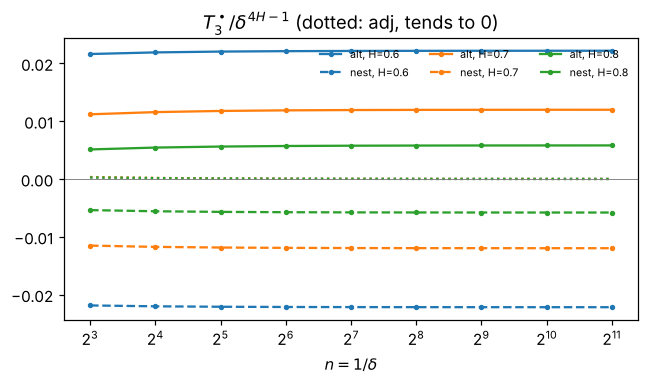

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for H, c in zip(A_HS, ("C0", "C1", "C2")):
    ax.semilogx(A_NS, a_series(H, "alt", 3, 4 * H - 1), "-o", color=c, ms=2.5, base=2, label=f"alt, H={H}")
    ax.semilogx(A_NS, a_series(H, "nest", 3, 4 * H - 1), "--o", color=c, ms=2.5, base=2, label=f"nest, H={H}")
    ax.semilogx(A_NS, a_series(H, "adj", 3, 4 * H - 1), ":", color=c, base=2)
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel(r"$n=1/\delta$")
ax.set_title(r"$T_3^\bullet/\delta^{4H-1}$ (dotted: adj, tends to 0)")
ax.legend(frameon=False, fontsize=7, ncol=3)
fig.tight_layout()
plt.show()

## A4. Remark 5.13: which words carry the relative error $\delta^{2H-1}$

**Claim** (Remark 5.13). Relative to the main term, the error of
Lemma 5.11 has size $O(\delta^{2H-1}+\delta^{2-2H}\log\tfrac1\delta)$. Numerically the first
term appears only for the alternating and nested words. The adjacent word and the level-3 drift words
show only the second: their relative error decays like $\delta^{2-2H}$.

**Method.** For each word, the relative error
$\varepsilon_\bullet(n)=|\delta^{-2H}\Delta E_\bullet/C_\bullet-1|$ uses the exact data of A2 and the exact
constants $C_\bullet$. The code prints the local exponent $\log_2(\varepsilon(n)/\varepsilon(2n))$ at the last
two doublings. For the level-3 drift word $122$ with an fBm driver, the relative error is
$|\mathcal W_{122}/(\theta\delta^{2H})+\tfrac1{12}|\cdot12$, from the exact formula of A5. The predictions:
adjacent and drift words $2-2H$; alternating and nested words $\min(2H-1,2-2H)$. The code also prints the
coefficient $C_1$ of $\delta^{2H-1}$ in the ladder fit of A2: it vanishes for the adjacent word only.

In [19]:
def a_W3_closed(terms, n, dtype=A_LD, theta=1.0):
    """Exact level-3 drift bias (W_122, W_212, W_221) for phi(u) = sum_k a_k u^{p_k}; see A5."""
    nn = dtype(n)
    t = np.arange(n + 1, dtype=dtype) / nn
    f = sum(dtype(a) * t ** dtype(p) for a, p in terms)
    tau = (np.sum(f) - (f[0] + f[-1]) / 2) / nn - sum(dtype(a) / (dtype(p) + 1) for a, p in terms)
    ph = sum(dtype(a) * (1 / nn) ** dtype(p) for a, p in terms)
    return theta * np.array([tau / 2 - ph / 12, ph / 6 - tau, tau / 2 - ph / 12])


a_ok_all = True
print("local exponents of the relative error at the last two doublings (predicted in brackets):")
for H in A_HS:
    a, b = 2 * H - 1, 2 - 2 * H
    line = f"H={H}:"
    for w, C in zip(A_WORDS, A_TARGET):
        eps = np.abs(a_series(H, w) / C - 1)
        loc = np.log2(eps[:-1] / eps[1:])
        pred = b if w == "adj" else min(a, b)
        a_ok_all &= abs(loc[-1] - pred) < 0.06
        line += f"  {w} {loc[-2]:.3f}, {loc[-1]:.3f} [{pred:.1f}]"
    eps3 = np.array([abs(float(a_W3_closed([(1.0, 2 * H)], n)[0]) * n ** (2 * H) * 12 + 1) for n in A_NS])
    loc3 = np.log2(eps3[:-1] / eps3[1:])
    a_ok_all &= abs(loc3[-1] - b) < 0.06
    line += f"  drift-122 {loc3[-2]:.3f}, {loc3[-1]:.3f} [{b:.1f}]"
    print(line)
    c1 = [a_fit(a_series(H, w), [0, a, b, 2 * a, 1], a_nmin)[1] for w in A_WORDS]
    a_ok_all &= abs(c1[0]) < 1e-3 and min(abs(c1[1]), abs(c1[2])) > 1e-2
    print(f"       coefficient of delta^(2H-1) in the ladder fit: adj {c1[0]:+.1e}, alt {c1[1]:+.4f}, nest {c1[2]:+.4f}")
print("paper: delta^(2H-1) only in alt and nest; adj and level-3 drift follow delta^(2-2H) ->", a_status(a_ok_all))

local exponents of the relative error at the last two doublings (predicted in brackets):
H=0.6:  adj 0.763, 0.769 [0.8]  alt 0.200, 0.200 [0.2]  nest 0.196, 0.197 [0.2]  drift-122 0.766, 0.771 [0.8]
       coefficient of delta^(2H-1) in the ladder fit: adj +1.1e-05, alt -0.1441, nest +0.1441
H=0.7:  adj 0.590, 0.592 [0.6]  alt 0.371, 0.375 [0.4]  nest 0.355, 0.362 [0.4]  drift-122 0.591, 0.594 [0.6]
       coefficient of delta^(2H-1) in the ladder fit: adj +1.0e-04, alt -0.2955, nest +0.2954
H=0.8:  adj 0.398, 0.399 [0.4]  alt 0.368, 0.373 [0.4]  nest 0.357, 0.364 [0.4]  drift-122 0.398, 0.399 [0.4]
       coefficient of delta^(2H-1) in the ladder fit: adj -2.7e-04, alt +0.1760, nest -0.1757
paper: delta^(2H-1) only in alt and nest; adj and level-3 drift follow delta^(2-2H) -> OK


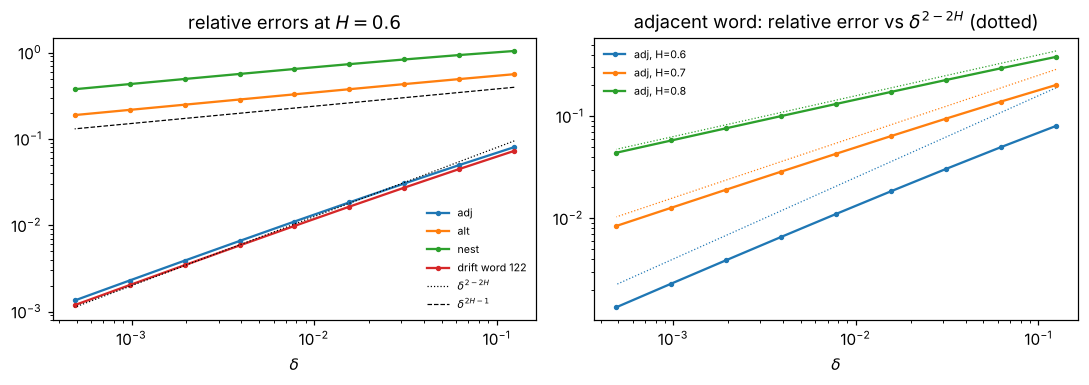

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
H = 0.6
dd = 1.0 / np.array(A_NS)
for w, C in zip(A_WORDS, A_TARGET):
    axs[0].loglog(dd, np.abs(a_series(H, w) / C - 1), "-o", ms=2.5, color=cols[w], label=w)
eps3 = [abs(float(a_W3_closed([(1.0, 1.2)], n)[0]) * n ** 1.2 * 12 + 1) for n in A_NS]
axs[0].loglog(dd, eps3, "-o", ms=2.5, color="C3", label="drift word 122")
axs[0].loglog(dd, 0.5 * dd ** 0.8, "k:", lw=0.8, label=r"$\delta^{2-2H}$")
axs[0].loglog(dd, 0.6 * dd ** 0.2, "k--", lw=0.8, label=r"$\delta^{2H-1}$")
axs[0].set_title(r"relative errors at $H=0.6$")
for H, c in zip((0.6, 0.7, 0.8), ("C0", "C1", "C2")):
    axs[1].loglog(dd, np.abs(a_series(H, "adj") * 12 + 1), "-o", ms=2.5, color=c, label=f"adj, H={H}")
    axs[1].loglog(dd, dd ** (2 - 2 * H), ":", color=c, lw=0.8)
axs[1].set_title(r"adjacent word: relative error vs $\delta^{2-2H}$ (dotted)")
for ax in axs:
    ax.set_xlabel(r"$\delta$")
    ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

## A5. Proposition 5.18: the level-3 drift bias

**Claim** (Proposition 5.18, and the paragraph "A numerical check",
lines 2445-2450). For $X^1=\theta t+G^1$, $X^2=G^2$, with $G$ of stationary increments and increment
variance $\phi$ satisfying Hypothesis (S),
$\mathcal W_3=\theta\phi(\delta)(-\tfrac1{12},\tfrac16,-\tfrac1{12})+O(\delta^2)$ on the words
$122,212,221$, with no remainder in the Brownian case. Exact evaluations of $\int_{0<s<t<1}e\,w_\ast$ for
$H=0.7$, $\phi(u)=u^{1.4}$ and two sums $\phi(u)=\sum_ka_ku^{2H_k}$ approach
$\phi(\delta)(-\tfrac1{12},\tfrac16,-\tfrac1{12})$ at the relative rate $\delta^{2-2H}$, and not the same
multiples of $\delta^{2H}$.

**The two sums.** The paper does not say which sums it used. We take two drivers with $\mathrm{Var}(G_1)=1$
and $2H\le2H_k<2$, as required after Lemma 5.8:
$\phi_A(u)=0.6\,u^{1.4}+0.4\,u^{1.8}$ and $\phi_B(u)=0.5\,u^{1.4}+0.3\,u^{1.6}+0.2\,u^{1.9}$.

**Exact formula used.** Integrating out the drift slot gives
$\langle122,\mathrm{Sig}\rangle=\theta\int_0^1\tfrac12(X^2_1-X^2_t)^2\,\mathrm dt$ for every path, so
$\mathbb E\langle122,\mathrm{Sig}(X)\rangle=\tfrac\theta2\int_0^1\phi(1-t)\,\mathrm dt$. For the interpolant,
on $I_a$, $\mathrm{Var}(G^n_1-G^n_t)=(1-\lambda)\phi(1-t_a)+\lambda\phi(1-t_{a+1})-\lambda(1-\lambda)\phi(\delta)$,
whose integral over the cell gives the trapezoidal rule minus $\delta\phi(\delta)/6$. Hence, exactly,
$$\mathcal W_{122}=\mathcal W_{221}=\theta\bigl(\tfrac12\tau_n-\tfrac1{12}\phi(\delta)\bigr),\qquad
\mathcal W_{212}=\theta\bigl(\tfrac16\phi(\delta)-\tau_n\bigr),$$
where $\tau_n$ is the trapezoidal rule for $\int_0^1\phi$ on the mesh minus the integral. ($\mathcal W_{221}$
follows by time reversal, $\mathcal W_{212}$ from the shuffle identity.) Since $\tau_n=O(\delta^2)$, the
relative error is $O(\delta^{2-2H})$. Three independent checks follow: (i) the literal Chen–Wick sum on
tiny meshes; (ii) the lag sum of the paper's proof,
$\int e\,w_\ast=\sum_{m<n}(1-m\delta)[\hat\phi^{\rm s}(m)\partial_sw_\ast+\hat\phi^{\rm t}(m)\partial_tw_\ast]$,
with the lag moments $\hat\phi^{\rm s}(m)$ of Lemma 5.8 in closed form (themselves checked
against quadrature, together with $\hat\phi^{\rm t}=-\hat\phi^{\rm s}$ of Lemma 5.9); (iii) a
Monte Carlo check of the interpolant's expectation. Reference values at $H=0.6$:
$\mathcal W_{122}/(\theta\delta^{2H})=-0.081064,-0.081967,-0.082516,-0.082848$ for $n=32,64,128,256$.

In [21]:
def a_phis_unit(p, m, dtype=A_LD):
    """Lag moment phi^s(m) of Lemma 5.8 for phi(u) = u^p at unit mesh (closed form, stable)."""
    m = np.asarray(m)
    out = np.empty(m.shape, dtype=dtype)
    p_ = dtype(p)
    out[m == 0] = 1 / dtype(6) - 1 / (2 * (p_ + 1))
    sm = (m >= 1) & (m < 8)
    out[sm] = a_d1(p, m[sm], dtype) / 4 - a_d2(p + 1, m[sm], dtype) / (2 * (p_ + 1))
    big = m >= 8
    mb = m[big].astype(dtype)
    if mb.size:                     # m^p sum_{j>=1} C(p,2j+1) m^{-2j-1} j/(2j+2)
        c = a_binom_coeffs(p, 45)
        x = 1 / mb
        s = np.zeros_like(mb)
        for j in range(20, 0, -1):
            s = s * x * x + dtype(str(c[2 * j + 1] * mp.mpf(j) / (2 * j + 2)))
        out[big] = mb ** p_ * s * x ** 3
    return out


def a_W3_lagsum(terms, n, dtype=A_LD, theta=1.0):
    """(W_122, W_212, W_221) from the exact lag sum in the proof of Proposition 5.18."""
    d = 1 / dtype(n)
    m = np.arange(n)
    ps = sum(dtype(a) * d ** dtype(p) * a_phis_unit(p, m, dtype) for a, p in terms)
    S = np.sum((1 - m.astype(dtype) * d) * ps)
    return theta * np.array([S, -2 * S, S])


def a_W3_brute(terms, n, theta=1.0):
    """Literal Chen-Wick sum: the drift slot carries theta*delta in its cell, the two G^2 slots are paired."""
    d = 1.0 / n
    phi = lambda u: sum(a * np.abs(u) ** p for a, p in terms)
    k = np.abs(np.subtract.outer(np.arange(n), np.arange(n))).astype(float)
    G = 0.5 * (phi((k + 1) * d) - 2 * phi(k * d) + phi(np.abs(k - 1) * d))
    E = np.zeros(3)
    for a in itertools.combinations_with_replacement(range(n), 3):
        c = 1.0
        for b in set(a):
            c /= factorial(a.count(b))
        for w, (p, q) in enumerate(((1, 2), (0, 2), (0, 1))):
            E[w] += c * theta * d * G[a[p], a[q]]
    I = sum(a / (p + 1) for a, p in terms) / 2
    return E - theta * np.array([I, 0.5 * phi(1.0) - 2 * I, I])


A_PHIS = {"u^1.4": [(1.0, 1.4)], "phi_A": [(0.6, 1.4), (0.4, 1.8)], "phi_B": [(0.5, 1.4), (0.3, 1.6), (0.2, 1.9)]}

# checks of the lag moments: closed form vs quadrature, and phi^t = -phi^s
import warnings
from scipy.integrate import IntegrationWarning
warnings.filterwarnings("ignore", category=IntegrationWarning)   # integrable endpoint singularity at lag 0
a_ok = True
for p in (1.2, 1.4, 1.8):
    cH = p / 2 * (p - 1)
    rr = lambda k: 0.5 * ((k + 1) ** p - 2 * k ** p + abs(k - 1) ** p)
    for m in (0, 1, 3, 8, 20):
        lo = (lambda u: u) if m == 0 else m
        hat_e = lambda v, u: rr(m) - cH * (v - u) ** (p - 2)
        qs = dblquad(lambda v, u: hat_e(v, u) * (u - 0.5), 0, 1, lo, m + 1, epsabs=1e-13)[0]
        qt = dblquad(lambda v, u: hat_e(v, u) * (v - m - 0.5), 0, 1, lo, m + 1, epsabs=1e-13)[0]
        cf = float(a_phis_unit(p, np.array([m]))[0])
        a_ok &= abs(cf - qs) < 1e-9 and abs(cf + qt) < 1e-9
print("lag moments phi^s(m): closed form = quadrature, and phi^t = -phi^s (Lemma 5.9):", a_status(a_ok))

a_ok = True
for terms in list(A_PHIS.values()) + [[(1.0, 1.2)], [(1.0, 1.0)]]:
    for n in (1, 2, 3, 5, 8):
        x, y, z = a_W3_closed(terms, n, float), a_W3_lagsum(terms, n, float), a_W3_brute(terms, n)
        a_ok &= np.max(np.abs(x - z)) < 1e-14 and np.max(np.abs(x - y)) < 1e-14
print("(i)  closed form = lag sum = literal Chen-Wick sum (n <= 8, five drivers):", a_status(a_ok))
a_dev = max(float(np.max(np.abs((a_W3_closed(t, n) - a_W3_lagsum(t, n)) / a_W3_closed(t, n))))
            for t in A_PHIS.values() for n in (64, 1024, A_NS[-1]))
print(f"(ii) closed form = lag sum on meshes up to n = {A_NS[-1]}: max relative difference {a_dev:.1e} ->",
      a_status(a_dev < 1e-10))

lag moments phi^s(m): closed form = quadrature, and phi^t = -phi^s (Lemma 5.9): OK
(i)  closed form = lag sum = literal Chen-Wick sum (n <= 8, five drivers): OK
(ii) closed form = lag sum on meshes up to n = 2048: max relative difference 1.4e-14 -> OK


In [22]:
# (iii) Monte Carlo sanity check (the only Monte Carlo in this part): E<122, Sig(X^n)> for drifted fBm
H, n, theta = 0.7, 8, 0.8
N = 100_000 if QUICK else 400_000
rng = np.random.default_rng(2024)
acc = []
for _ in range(N // 50_000):
    inc = fbm_increments(H, n, 50_000, d=2, rng=rng)
    inc[:, :, 0] += theta / n                                    # drift theta*t in coordinate 1
    lev = sig_pl(inc, 3)
    acc.append(np.stack([coord(lev, w) for w in ("122", "212", "221")], 1))
acc = np.concatenate(acc)
mc, se = acc.mean(0), acc.std(0) / np.sqrt(len(acc))
t_ = np.arange(n + 1) / n
trap = np.sum(((1 - t_[:-1]) ** 1.4 + (1 - t_[1:]) ** 1.4) / 2) / n
ex122 = theta / 2 * (trap - (1 / n) ** 1.4 / 6)
exact = np.array([ex122, theta / 2 - 2 * ex122, ex122])
z = np.abs(mc - exact) / se
for w, a_, b_, s_ in zip(("122", "212", "221"), mc, exact, se):
    print(f"   word {w}: Monte Carlo {a_:.5f} +- {s_:.5f}  exact interpolant value {b_:.5f}")
print(f"(iii) Monte Carlo (N = {N}, n = {n}, H = 0.7, theta = 0.8) agrees within 4 standard errors:",
      a_status(np.all(z < 4)))

   word 122: Monte Carlo 0.16416 +- 0.00142  exact interpolant value 0.16368
   word 212: Monte Carlo 0.07237 +- 0.00111  exact interpolant value 0.07265
   word 221: Monte Carlo 0.16140 +- 0.00141  exact interpolant value 0.16368
(iii) Monte Carlo (N = 100000, n = 8, H = 0.7, theta = 0.8) agrees within 4 standard errors: OK


In [23]:
# the paper's check: H = 0.7, phi = u^1.4 and the two sums
A_NS5 = [2 ** k for k in range(3, 15 if QUICK else 21)]
print("W_w/(theta phi(delta)) for w = 122, 212 (221 = 122) and W_122/(theta delta^1.4):")
a_ok_all = True
for name, terms in A_PHIS.items():
    R = np.array([[float(x) for x in a_W3_closed(terms, n)] for n in A_NS5])
    ph = np.array([sum(a * (1.0 / n) ** p for a, p in terms) for n in A_NS5])
    rel = np.abs(R[:, 0] / ph * 12 + 1)
    loc = np.log2(rel[:-1] / rel[1:])
    for i in (A_NS5.index(64), A_NS5.index(1024), len(A_NS5) - 1):
        n = A_NS5[i]
        print(f"  {name:6s} n={n:>7}: ({R[i, 0] / ph[i]:+.6f}, {R[i, 1] / ph[i]:+.6f}),"
              f"  rel. error {rel[i]:.2e}, W_122/delta^1.4 = {R[i, 0] * n ** 1.4:+.6f}")
    ok = abs(loc[-1] - 0.6) < 0.05 and rel[-1] < 1e-2
    a_ok_all &= ok
    print(f"  {name:6s} local exponent of the relative error at the last doublings: "
          f"{np.round(loc[-3:], 3)} (predicted 2-2H = 0.6) -> {a_status(ok)}")
print("  limits of W_122/(theta delta^1.4): u^1.4 -> -1/12 = -0.083333; phi_A -> -0.6/12 = -0.05;"
      " phi_B -> -0.5/12 = -0.041667 (the normalisation by phi(delta) is the right one)")
print("paper: approach phi(delta)(-1/12, 1/6, -1/12) at relative rate delta^(2-2H) ->", a_status(a_ok_all))

# Brownian case: no remainder; and the values at H = 0.6
a_ok = all(np.max(np.abs(a_W3_closed([(1.0, 1.0)], n, float) * n - [-1 / 12, 1 / 6, -1 / 12])) < 1e-13
           for n in (1, 2, 7, 64, 1000))
print("H = 1/2: W_3 = (-1/12, 1/6, -1/12) delta exactly on every mesh:", a_status(a_ok))
vals = {n: float(a_W3_closed([(1.0, 1.2)], n)[0]) * n ** 1.2 for n in (32, 64, 128, 256)}
print("H = 0.6, W_122/(theta delta^2H):", ", ".join(f"n={n}: {v:.6f}" for n, v in vals.items()),
      "(limit -1/12 = -0.083333)")

W_w/(theta phi(delta)) for w = 122, 212 (221 = 122) and W_122/(theta delta^1.4):
  u^1.4  n=     64: (-0.078786, +0.157573),  rel. error 5.46e-02, W_122/delta^1.4 = -0.078786
  u^1.4  n=   1024: (-0.082438, +0.164877),  rel. error 1.07e-02, W_122/delta^1.4 = -0.082438
  u^1.4  n=  16384: (-0.083162, +0.166323),  rel. error 2.06e-03, W_122/delta^1.4 = -0.083162
  u^1.4  local exponent of the relative error at the last doublings: [0.595 0.596 0.597] (predicted 2-2H = 0.6) -> OK
  phi_A  n=     64: (-0.075642, +0.151284),  rel. error 9.23e-02, W_122/delta^1.4 = -0.051118
  phi_A  n=   1024: (-0.081724, +0.163449),  rel. error 1.93e-02, W_122/delta^1.4 = -0.051078
  phi_A  n=  16384: (-0.083018, +0.166036),  rel. error 3.78e-03, W_122/delta^1.4 = -0.050495
  phi_A  local exponent of the relative error at the last doublings: [0.587 0.59  0.592] (predicted 2-2H = 0.6) -> OK
  phi_B  n=     64: (-0.075388, +0.150775),  rel. error 9.53e-02, W_122/delta^1.4 = -0.049423
  phi_B  n=   1024: (-0.0

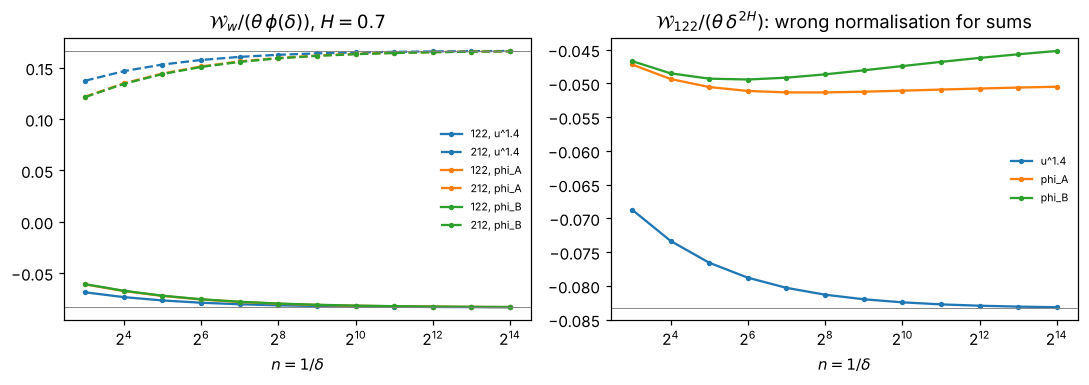

Part A finished in 5.4 s


In [24]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for (name, terms), c in zip(A_PHIS.items(), ("C0", "C1", "C2")):
    R = np.array([[float(x) for x in a_W3_closed(terms, n)] for n in A_NS5])
    ph = np.array([sum(a * (1.0 / n) ** p for a, p in terms) for n in A_NS5])
    axs[0].semilogx(A_NS5, R[:, 0] / ph, "-o", ms=2.5, color=c, base=2, label=f"122, {name}")
    axs[0].semilogx(A_NS5, R[:, 1] / ph, "--o", ms=2.5, color=c, base=2, label=f"212, {name}")
    axs[1].semilogx(A_NS5, R[:, 0] * np.array(A_NS5, float) ** 1.4, "-o", ms=2.5, color=c, base=2, label=name)
for v in (-1 / 12, 1 / 6):
    axs[0].axhline(v, color="grey", lw=0.6)
axs[1].axhline(-1 / 12, color="grey", lw=0.6)
axs[0].set_title(r"$\mathcal{W}_w/(\theta\,\phi(\delta))$, $H=0.7$")
axs[1].set_title(r"$\mathcal{W}_{122}/(\theta\,\delta^{2H})$: wrong normalisation for sums")
for ax in axs:
    ax.set_xlabel(r"$n=1/\delta$")
    ax.legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()
print(f"Part A finished in {time.time() - A_T0:.1f} s")

# Part B. The rough range $H\in(\tfrac14,\tfrac12)$ (Section 6)

This part checks four numerical statements of Section 6:

* **B1** the table of $\kappa_{\rm alt}(H)$ in Remark 6.19, computed in three
  independent ways (Proposition 6.16, the $\zeta$-series of Proposition 6.13,
  the geometric form of Corollary B.5);
* **B2** the sign change of $\delta^{-(4H-1)}\Delta E_{\rm alt}$ at $H=0.48$ near $n\approx1.2\cdot10^3$
  (after Corollary 6.20), from an exact $O(n\log n)$ evaluation of $E^n_{\rm alt}$ built on the
  splitting eq. (40);
* **B3** the level-6 experiment of Remark 6.27 (exact Wick dynamic programme in $d=3$);
* **B4** the sharpness of the canonical-correlation bound, Remark 6.7.

Everything in this part is exact up to floating point (closed forms, finite Wick sums, linear
algebra) or uses `mpmath` at 30 significant digits. Nothing here is Monte Carlo.

In [25]:
QUICK = globals().get("QUICK", True)
import mpmath as mp
from scipy.special import gamma as b_Gamma, binom as b_binom
from scipy.linalg import cholesky as b_cholesky, solve_triangular as b_solve_tri, svdvals as b_svdvals, toeplitz as b_toeplitz
from scipy import integrate as b_integrate

b_T0 = time.time()
print("Part B, QUICK =", QUICK)


def b_verdict(ok):
    return "OK" if ok else "MISMATCH"


def b_r(k, H):
    """fGn autocovariance r(k), numerically stable for large |k| (binomial series of the
    second central difference of |x|^{2H}, used for |k| >= 16 to avoid cancellation)."""
    k = np.abs(np.asarray(k, dtype=float))
    out = np.asarray(fgn_autocov(k, H), dtype=float).copy()
    big = k >= 16
    if np.any(big):
        kb = k[big]
        s = np.zeros_like(kb)
        for j in range(2, 40, 2):
            s += b_binom(2 * H, j) * kb ** (-j)
        out[big] = kb ** (2 * H) * s
    return out


def b_Einf_alt(H):
    """Continuum coordinate E^infty_alt of Proposition 6.10."""
    return H / (4 * (4 * H - 1)) * (1 - b_Gamma(2 * H) ** 2 / b_Gamma(4 * H - 1))

Part B, QUICK = True


## B1. The values of $\kappa_{\rm alt}(H)$ (Remark 6.19)

**Claim.** The formula of Proposition 6.16,
$$\kappa_{\rm alt}(H)=H^2\zeta(2-4H)+\sum_{h\ge1}\bigl[U(h)^2-H^2h^{4H-2}\bigr],\qquad
  U(h)=-\tfrac14\bigl[(h+1)^{2H}-(h-1)^{2H}\bigr],$$
gives $\kappa_{\rm alt}=-0.341259,\,-0.191518,\,-0.146876,\,-0.129644,\,-0.125705$ at
$H=0.30,0.35,0.40,0.45,0.48$, increasing to $-\tfrac18$ as $H\uparrow\tfrac12$. The same number is
the $\zeta$-series $-\tfrac1{16}+\tfrac18\sum_{j\ge1}|\binom{2H}{j}|\zeta(2j-4H)$ of Proposition
Proposition 6.13 and the geometric series $\tfrac1{16}+\tfrac18\sum_{j\ge1}|\binom{2H}{j}|(\zeta(2j-4H)-1)$
of Corollary B.5.

**Method.**

1. *Proposition 6.16.* The terms of the series decay only like $h^{4H-4}$ (like $h^{-2.08}$
   at $H=0.48$), so a plain partial sum is not accurate to six digits, and in double precision the
   difference $(h+1)^{2H}-(h-1)^{2H}$ also loses digits for large $h$. We therefore sum the first
   $K=200$ terms in `mpmath` and the tail exactly: from
   $U(h)=-\tfrac12h^{2H}\sum_{j\ \rm odd}\binom{2H}{j}h^{-j}$,
   $$\sum_{h>K}\bigl[U(h)^2-H^2h^{4H-2}\bigr]=\tfrac14\sum_{s\ge4\ \rm even}e_s\,\zeta(s-4H,K+1),\qquad
     e_s=\sum_{j+k=s,\ j,k\ \rm odd}\tbinom{2H}{j}\tbinom{2H}{k},$$
   with the Hurwitz zeta function. Truncating at $s\le60$ leaves an error of order $K^{-60}$.
2. *Corollary B.5.* The terms decay like $4^{-j}$; 80 terms in `mpmath`.
3. *Proposition 6.13.* The raw $\zeta$-series converges only at rate $J^{-2H}$. We
   show the partial sums $S_J$ for $J$ up to $2^{17}$, check that the error decays like $J^{-2H}$, and
   remove it by a Richardson step with the fitted exponent. This gives the value to about six digits,
   independently of the two other forms.

In [26]:
b_H_TAB = [0.30, 0.35, 0.40, 0.45, 0.48]
b_KAPPA_PAPER = {0.30: -0.341259, 0.35: -0.191518, 0.40: -0.146876, 0.45: -0.129644, 0.48: -0.125705}


def b_kappa_Lexists(H, K=200, smax=60, dps=30):
    """kappa_alt by the absolutely convergent formula of Proposition 6.16.
    First K terms summed directly, tail summed exactly through the Hurwitz zeta function."""
    mp.mp.dps = dps
    H = mp.mpf(H)
    U = lambda h: -((h + 1) ** (2 * H) - (h - 1) ** (2 * H)) / 4
    head = mp.fsum(U(mp.mpf(h)) ** 2 - H ** 2 * mp.mpf(h) ** (4 * H - 2) for h in range(1, K + 1))
    bj = [mp.binomial(2 * H, j) if j % 2 else mp.mpf(0) for j in range(smax + 1)]
    tail = mp.mpf(0)
    for s in range(4, smax + 1, 2):
        e = mp.fsum(bj[j] * bj[s - j] for j in range(1, s, 2))
        tail += e * mp.zeta(s - 4 * H, K + 1) / 4
    return H ** 2 * mp.zeta(2 - 4 * H) + head + tail


def b_kappa_geom(H, J=80, dps=30):
    """kappa_alt by the geometrically convergent form of Corollary B.5."""
    mp.mp.dps = dps
    H = mp.mpf(H)
    s = mp.fsum(abs(mp.binomial(2 * H, j)) * (mp.zeta(2 * j - 4 * H) - 1) for j in range(1, J + 1))
    return mp.mpf(1) / 16 + s / 8


def b_zeta_partial_sums(H, Jmax):
    """Partial sums S_J of the raw zeta-series of Proposition 6.13, J = 1..Jmax.
    zeta(2j-4H) from mpmath for j <= 30; for j > 30 the value 1 + 2^-s + 3^-s is exact in double precision."""
    j = np.arange(1, Jmax + 1, dtype=float)
    c = np.empty(Jmax)
    c[0] = 2 * H
    c[1:] = np.cumprod((j[:-1] - 2 * H) / (j[:-1] + 1)) * 2 * H      # |binom(2H, j)|
    s = 2 * j - 4 * H
    z = 1 + 2.0 ** (-s) + 3.0 ** (-s)
    mp.mp.dps = 30
    for i in range(min(30, Jmax)):
        z[i] = float(mp.zeta(s[i]))
    return -1 / 16 + np.cumsum(c * z) / 8


b_rows = []
for H in b_H_TAB:
    kL = b_kappa_Lexists(H)
    kG = b_kappa_geom(H)
    Jmax = 2 ** 17
    S = b_zeta_partial_sums(H, Jmax)
    S1, S2, S3 = S[2 ** 15 - 1], S[2 ** 16 - 1], S[2 ** 17 - 1]
    p_hat = np.log2((S2 - S1) / (S3 - S2))                # fitted error exponent, should be 2H
    kZ = S3 + (S3 - S2) / (2 ** p_hat - 1)                 # Richardson step
    b_rows.append((H, float(kL), float(kG), S3, kZ, p_hat))

print("B1: kappa_alt(H)")
print(f"{'H':>5} {'paper':>10} {'Prop Lexists':>16} {'Cor geomkappa':>16} {'zeta S_J, J=2^17':>17}"
      f" {'zeta extrap.':>13} {'fit exp':>8}")
b1_ok = True
for H, kL, kG, S3, kZ, p_hat in b_rows:
    paper = b_KAPPA_PAPER[H]
    ok = abs(round(kL, 6) - paper) < 1e-12 and abs(kL - kG) < 1e-12 and abs(kZ - kL) < 5e-6
    b1_ok &= ok
    print(f"{H:5.2f} {paper:10.6f} {kL:16.12f} {kG:16.12f} {S3:17.9f} {kZ:13.7f} {p_hat:8.4f}  (2H={2*H:.2f})  {b_verdict(ok)}")

print("\nlimit H -> 1/2 (Cor geomkappa):")
for H in [0.49, 0.499, 0.4999, 0.49999]:
    print(f"  H={H}: kappa_alt = {float(b_kappa_geom(H)):.9f}")
lim_ok = abs(float(b_kappa_geom(0.49999)) + 0.125) < 1e-6
mono = all(b_rows[i][1] < b_rows[i + 1][1] for i in range(len(b_rows) - 1))
print(f"increasing along the table: {mono};  limit -1/8: {b_verdict(lim_ok)}")
print("B1 overall:", b_verdict(b1_ok and lim_ok and mono))

B1: kappa_alt(H)
    H      paper     Prop Lexists    Cor geomkappa  zeta S_J, J=2^17  zeta extrap.  fit exp
 0.30  -0.341259  -0.341259261847  -0.341259261847      -0.341307170    -0.3412593   0.6000  (2H=0.60)  OK
 0.35  -0.191518  -0.191517665587  -0.191517665587      -0.191528599    -0.1915177   0.7000  (2H=0.70)  OK
 0.40  -0.146876  -0.146875573853  -0.146875573853      -0.146877767    -0.1468756   0.8000  (2H=0.80)  OK
 0.45  -0.129644  -0.129643876282  -0.129643876282      -0.129644202    -0.1296439   0.9000  (2H=0.90)  OK
 0.48  -0.125705  -0.125704905386  -0.125704905386      -0.125704968    -0.1257049   0.9600  (2H=0.96)  OK

limit H -> 1/2 (Cor geomkappa):
  H=0.49: kappa_alt = -0.125174310
  H=0.499: kappa_alt = -0.125001731
  H=0.4999: kappa_alt = -0.125000017
  H=0.49999: kappa_alt = -0.125000000
increasing along the table: True;  limit -1/8: OK
B1 overall: OK


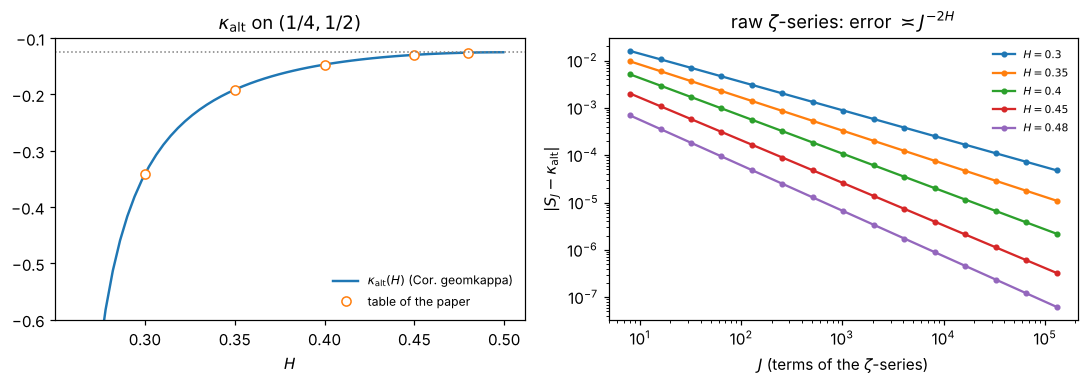

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
Hs = np.linspace(0.262, 0.4995, 60)
ax[0].plot(Hs, [float(b_kappa_geom(h, J=60, dps=20)) for h in Hs], lw=1.6, label=r"$\kappa_{\rm alt}(H)$ (Cor. geomkappa)")
ax[0].plot(b_H_TAB, [b_KAPPA_PAPER[h] for h in b_H_TAB], "o", mfc="white", label="table of the paper")
ax[0].axhline(-1 / 8, color="0.5", ls=":", lw=1)
ax[0].set_ylim(-0.6, -0.1)
ax[0].set_xlabel("$H$")
ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title(r"$\kappa_{\rm alt}$ on $(1/4,1/2)$")
Jg = 2 ** np.arange(3, 18)
for H, kL, *_ in b_rows:
    S = b_zeta_partial_sums(H, Jg[-1])
    ax[1].loglog(Jg, np.abs(S[Jg - 1] - kL), "o-", ms=3, label=f"$H={H}$")
ax[1].set_xlabel("$J$ (terms of the $\\zeta$-series)")
ax[1].set_ylabel(r"$|S_J-\kappa_{\rm alt}|$")
ax[1].set_title(r"raw $\zeta$-series: error $\asymp J^{-2H}$")
ax[1].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

## B2. The sign change at $H=0.48$ (after Corollary 6.20)

**Claim.** The $o(1)$ in $\Delta E_{\rm alt}=\kappa_{\rm alt}\delta^{4H-1}(1+o(1))$ is not uniform in
$H$: at $H=0.48$ the ratio $\delta^{-(4H-1)}\Delta E_{\rm alt}$ changes sign only at
$n\approx1.2\cdot10^3$. (Its limit $\kappa_{\rm alt}(0.48)=-0.1257$ is negative, but for coarse meshes the
ratio is positive.)

**Method.** By Chen's formula eq. (8) and the Wick (Isserlis) theorem,
$E^n_{\rm alt}=\delta^{4H}Q_{\rm alt}(n)$ with
$Q_{\rm alt}(n)=\sum_{c_1\le c_2\le c_3\le c_4}w(\mathbf c)\,r(c_3-c_1)\,r(c_4-c_2)$, a sum over
$O(n^4)$ cell tuples. The proof of Proposition 6.16 splits it exactly,
$$Q_{\rm alt}(n)=A(n)+B_1(n)-B_2(n)+B_3(n)\qquad\text{(eq. (40))},$$
and every piece has the form $\sum_{s<n}(n-s)F(s)$ for an explicit sequence $F$:

* $A$: $F_A(0)=\tfrac1{24}$ and $F_A(s)=\tfrac13r(s)+\tfrac12\sum_{h=1}^{s-1}r(h)r(s-h)$ for $s\ge1$
  (the weights $w_A=\tfrac12,\tfrac16,\tfrac1{24}$ of the $h_2=0$ part);
* $B_2$: $F=r\,\Sigma$ with $\Sigma(b)=\sum_{a\le b}r(a)$; $B_3$: $F=\tfrac14r^2$;
* $B_1(n)=\sum_{N=1}^{n-1}\Phi(N)$ by eq. (41), and Lemma 6.14 gives $\Phi(N)$ in closed
  form up to the convolution $\mathcal D(N)=\sum_{a=1}^{N-1}D(a)D(N-a)$.

The two convolutions are computed once for all $s,N\le n_{\max}$ with `np.convolve` (direct summation),
and then all $Q_{\rm alt}(n)$, $n\le n_{\max}$, follow from cumulative sums: total cost $O(n_{\max}^2)$
with a tiny constant (an FFT would give $O(n_{\max}\log n_{\max})$). The evaluation is exact up to
rounding. We validate it against (i) the brute-force Wick sum over all $c_1\le\dots\le c_4$ for
$n\le10$, (ii) the $O(n^3)$ sum over the gaps $(h_1,h_2,h_3)$ for $n=200$ (which does not use
eq. (40)), and (iii) a 30-digit `mpmath` evaluation at the two meshes around the sign change.

In [28]:
def b_lin(F):
    """out[n] = sum_{s<n} (n-s) F(s), for n = 0..len(F)."""
    s = np.arange(len(F))
    cF = np.concatenate([[0.0], np.cumsum(F)])
    csF = np.concatenate([[0.0], np.cumsum(s * F)])
    n = np.arange(len(F) + 1)
    return n * cF - csF


def b_Qalt_all(nmax, H):
    """Q_alt(n) = delta^{-4H} E^n_alt for all n = 0..nmax, by eq. (40) and Lemma 6.14."""
    rr = fgn_autocov(np.arange(nmax + 1), H)                    # rr[0] = 1
    r1 = rr.copy()
    r1[0] = 0.0
    # A(n)
    FA = np.zeros(nmax + 1)
    FA[0] = 1 / 24
    FA[1:] = rr[1:] / 3 + 0.5 * np.convolve(r1, r1)[1:nmax + 1]
    A = b_lin(FA)[:nmax + 1]
    # B1(n) = sum_{N=1}^{n-1} Phi(N), Phi from Lemma 6.14
    h = np.arange(1, nmax + 1, dtype=float)
    T = -0.5 * (h ** (2 * H) - (h - 1) ** (2 * H))
    cT2 = np.concatenate([[0.0], np.cumsum(T ** 2)])             # sum_{h<=N} T(h)^2
    k = np.arange(nmax + 1, dtype=float)
    D = (k + 1) ** (2 * H) - k ** (2 * H)                        # D(k), D(0) = 1
    Dz = D.copy()
    Dz[0] = 0.0
    calD = np.convolve(Dz, Dz)[:nmax + 1]                        # sum_{a=1}^{N-1} D(a) D(N-a)
    Phi = np.zeros(nmax + 1)
    Phi[1:] = cT2[1:] - (0.5 * D[1:] - 0.25 * D[1:] ** 2 + 0.25 * calD[1:])
    B1 = np.concatenate([[0.0], np.cumsum(Phi)[:-1]])           # B1[n] = sum_{N<=n-1} Phi(N)
    # B2, B3
    Sig = np.cumsum(r1)
    B2 = b_lin(r1 * Sig)[:nmax + 1]
    B3 = b_lin(0.25 * r1 ** 2)[:nmax + 1]
    return A + B1 - B2 + B3, Phi


def b_Qalt_brute(n, H):
    """Brute-force Wick sum over all ordered cell tuples c1<=c2<=c3<=c4 (O(n^4))."""
    rr = fgn_autocov(np.arange(n), H)
    tot = 0.0
    for c in itertools.combinations_with_replacement(range(n), 4):
        w = 1.0
        for v in set(c):
            w /= factorial(c.count(v))
        tot += w * rr[c[2] - c[0]] * rr[c[3] - c[1]]
    return tot


def b_Qalt_gaps(n, H):
    """O(n^3) sum over the gaps (h1,h2,h3) of the ordered tuple (Step 1 of the proof), no splitting."""
    rr = fgn_autocov(np.arange(3 * n + 2), H)
    h = np.arange(n)
    H1, H3 = np.meshgrid(h, h, indexing="ij")
    Q = 0.0
    for h2 in range(n):
        cnt = np.clip(n - (H1 + h2 + H3), 0, None).astype(float)
        if h2 == 0:
            z1, z3 = H1 == 0, H3 == 0
            w = np.where(z1 & z3, 1 / 24, np.where(z1 | z3, 1 / 6, 1 / 2))
        else:
            w = np.where(H1 == 0, 0.5, 1.0) * np.where(H3 == 0, 0.5, 1.0)
        Q += np.sum(cnt * w * rr[H1 + h2] * rr[h2 + H3])
    return Q


def b_Qalt_mp(nlist, H, dps=30):
    """Q_alt(n) for the meshes in nlist, same splitting, in mpmath (30 digits)."""
    mp.mp.dps = dps
    H = mp.mpf(H)
    nmax = max(nlist)
    rr = [mp.mpf(1)] + [((m + 1) ** (2 * H) - 2 * mp.mpf(m) ** (2 * H) + (m - 1) ** (2 * H)) / 2
                        for m in range(1, nmax + 1)]
    D = [(k + 1) ** (2 * H) - mp.mpf(k) ** (2 * H) for k in range(nmax + 1)]
    T2 = [mp.mpf(0)] + [((h ** (2 * H) - (h - 1) ** (2 * H)) / 2) ** 2 for h in range(1, nmax + 1)]
    FA = [mp.mpf(1) / 24] + [rr[s] / 3 + mp.fsum(rr[a] * rr[s - a] for a in range(1, s)) / 2 for s in range(1, nmax)]
    Phi = [mp.mpf(0)]
    cT2 = mp.mpf(0)
    for N in range(1, nmax):
        cT2 += T2[N]
        calD = mp.fsum(D[a] * D[N - a] for a in range(1, N))
        Phi.append(cT2 - (D[N] / 2 - D[N] ** 2 / 4 + calD / 4))
    Sig = [mp.mpf(0)]
    for b in range(1, nmax + 1):
        Sig.append(Sig[-1] + rr[b])
    out = {}
    for n in nlist:
        A = mp.fsum((n - s) * FA[s] for s in range(n))
        B1 = mp.fsum(Phi[1:n])
        B2 = mp.fsum((n - b) * rr[b] * Sig[b] for b in range(1, n))
        B3 = mp.fsum((n - a) * rr[a] ** 2 for a in range(1, n)) / 4
        out[n] = A + B1 - B2 + B3
    return out


# validation (i): brute force, and Phi against its definition, for several H (also H > 1/2)
err_b, err_phi = 0.0, 0.0
for H in [0.3, 0.48, 0.7]:
    q, Phi = b_Qalt_all(10, H)
    err_b = max(err_b, max(abs(q[n] - b_Qalt_brute(n, H)) / abs(q[n]) for n in range(1, 11)))
    rr = fgn_autocov(np.arange(30), H)
    for N in range(1, 9):
        ph = sum(rr[h + p] * rr[h + qq] for h in range(1, N + 1) for p in range(N) for qq in range(N) if h + p + qq <= N)
        err_phi = max(err_phi, abs(Phi[N] - ph))
# validation (ii): gap sum at n = 200
q200 = b_Qalt_all(200, 0.48)[0][200]
g200 = b_Qalt_gaps(200, 0.48)
print(f"B2 validation: max rel. error vs brute-force Wick sum (n<=10, H=0.3,0.48,0.7): {err_b:.1e}")
print(f"               max error of Phi(N) vs its definition (N<=8):                 {err_phi:.1e}")
print(f"               n=200, H=0.48: splitting {q200:.15e}, gap sum {g200:.15e}, rel. diff {abs(q200-g200)/g200:.1e}")
b2_valid = err_b < 1e-12 and err_phi < 1e-12 and abs(q200 - g200) / g200 < 1e-12

B2 validation: max rel. error vs brute-force Wick sum (n<=10, H=0.3,0.48,0.7): 2.9e-15
               max error of Phi(N) vs its definition (N<=8):                 1.6e-15
               n=200, H=0.48: splitting 1.136046640422620e+01, gap sum 1.136046640422559e+01, rel. diff 5.4e-14


In [29]:
H = 0.48
NMAX = 20000 if QUICK else 50000
t0 = time.time()
Q, _ = b_Qalt_all(NMAX, H)
n = np.arange(1, NMAX + 1)
ratio = Q[1:] / n - n ** (4 * H - 1) * b_Einf_alt(H)          # delta^{-(4H-1)} Delta E_alt
sgn = np.sign(ratio)
chg = np.where(sgn[1:] != sgn[:-1])[0]
print(f"computed Q_alt(n) for all n <= {NMAX} in {time.time()-t0:.2f}s")
print("sign changes of delta^{-(4H-1)} Delta E_alt for 1 <= n <=", NMAX, ":",
      [(int(n[i]), int(n[i + 1])) for i in chg])
for m in [1, 10, 100, 1000, 1154, 1155, 2000, 10000, NMAX]:
    print(f"   n={m:6d}: ratio = {ratio[m-1]:+.6e}")
kap48 = float(b_kappa_Lexists(0.48))
print(f"   kappa_alt(0.48) = {kap48:.6f}  (limit; approached only like n^(2H-1) = n^-0.04)")

# validation (iii): 30-digit evaluation at the two meshes around the sign change
if len(chg) == 1:
    nA, nB = int(n[chg[0]]), int(n[chg[0] + 1])
    t0 = time.time()
    Qmp = b_Qalt_mp([nA, nB], 0.48)
    mp.mp.dps = 30
    Hm = mp.mpf("0.48")
    Einf_mp = Hm / (4 * (4 * Hm - 1)) * (1 - mp.gamma(2 * Hm) ** 2 / mp.gamma(4 * Hm - 1))
    rmp = {m: Qmp[m] / m - mp.mpf(m) ** (4 * Hm - 1) * Einf_mp for m in (nA, nB)}
    print(f"   mpmath (30 digits, {time.time()-t0:.1f}s): ratio(n={nA}) = {mp.nstr(rmp[nA], 12)},"
          f" ratio(n={nB}) = {mp.nstr(rmp[nB], 12)}")
    print(f"   double precision:            ratio(n={nA}) = {ratio[nA-1]:.11e}, ratio(n={nB}) = {ratio[nB-1]:.11e}")
    mp_ok = rmp[nA] > 0 > rmp[nB] and abs(float(rmp[nA]) - ratio[nA - 1]) < 1e-9
    b2_ok = b2_valid and mp_ok and 1150 <= nA <= 1249
    print(f"paper: sign change only at n ~ 1.2e3;  computed: single sign change between n={nA} and n={nB}  {b_verdict(b2_ok)}")
else:
    print("paper: a single sign change near 1.2e3; computed: ", len(chg), "sign changes  MISMATCH")

computed Q_alt(n) for all n <= 20000 in 0.15s
sign changes of delta^{-(4H-1)} Delta E_alt for 1 <= n <= 20000 : [(1154, 1155)]
   n=     1: ratio = +4.130246e-02
   n=    10: ratio = +2.628907e-02
   n=   100: ratio = +1.291556e-02
   n=  1000: ratio = +7.232284e-04
   n=  1154: ratio = +1.087137e-06
   n=  1155: ratio = -3.267315e-06
   n=  2000: ratio = -2.733395e-03
   n= 10000: ratio = -1.039998e-02
   n= 20000: ratio = -1.355290e-02
   kappa_alt(0.48) = -0.125705  (limit; approached only like n^(2H-1) = n^-0.04)


   mpmath (30 digits, 2.5s): ratio(n=1154) = 1.08713721834e-6, ratio(n=1155) = -3.26731502807e-6
   double precision:            ratio(n=1154) = 1.08713715852e-06, ratio(n=1155) = -3.26731508776e-06
paper: sign change only at n ~ 1.2e3;  computed: single sign change between n=1154 and n=1155  OK


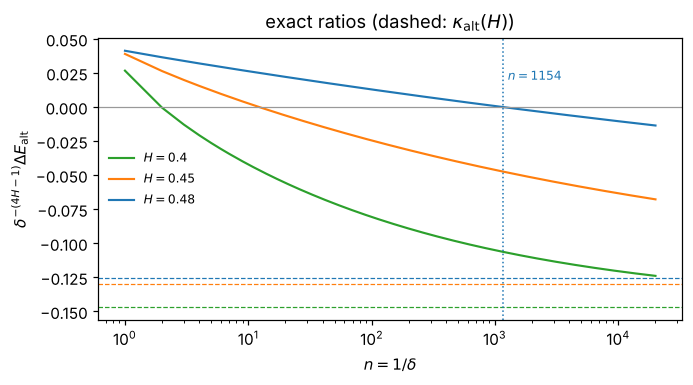

In [30]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for Hh, col in [(0.40, "C2"), (0.45, "C1"), (0.48, "C0")]:
    QQ, _ = b_Qalt_all(NMAX, Hh)
    rat = QQ[1:] / n - n ** (4 * Hh - 1) * b_Einf_alt(Hh)
    sel = np.unique(np.geomspace(1, NMAX, 400).astype(int)) - 1
    ax.semilogx(n[sel], rat[sel], color=col, lw=1.4, label=f"$H={Hh}$")
    ax.axhline(float(b_kappa_Lexists(Hh)), color=col, ls="--", lw=0.8)
ax.axhline(0, color="0.6", lw=0.8)
if len(chg) == 1:
    ax.axvline(nA, color="C0", ls=":", lw=1)
    ax.text(nA * 1.1, 0.02, f"$n={nA}$", color="C0", fontsize=8)
ax.set_xlabel(r"$n=1/\delta$")
ax.set_ylabel(r"$\delta^{-(4H-1)}\Delta E_{\rm alt}$")
ax.set_title(r"exact ratios (dashed: $\kappa_{\rm alt}(H)$)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## B3. Level 6 below the crossover (Remark 6.27, and the Introduction)

**Claim.** For $d=3$ and $H\in\{0.3,0.35,0.4\}$, exact evaluation on dyadic meshes shows that the
ratios of successive differences of the words $121233$ and $122133$ to those of $1212$ settle at
nonzero limits, and that the ratio for $121211$ stays bounded away from zero with only a slight
drift. An order $\delta^{6H-2}$ for these level-6 coordinates would make the ratios grow like
$\delta^{2H-1}$, i.e. by the factor $2^{1-2H}$ each time $n$ doubles. The Introduction summarises this as
"numerically level 6 does [contribute at order $\delta^{4H-1}$] below the crossover".

**Method.** The continuum values of the level-6 coordinates are not known in closed form, so we look at
successive differences $D_n(w)=E^n_w-E^{2n}_w$ along $n=8,16,32,\dots$, which have the same order as
the weak error, and at the ratios $D_n(w)/D_n(1212)$; by Theorem 6.21
$D_n(1212)\asymp\delta^{4H-1}$.

$E^n_w=\mathbb E\langle w,\mathrm{Sig}(X^n)\rangle$ is computed exactly by a dynamic programme over the
cells. By Chen's formula eq. (8), $E^n_w=\sum_{a_1\le\dots\le a_m}c_{\mathbf a}\,
\mathbb E\prod_l\Delta^{w_l}_{a_l}$. Isserlis' theorem splits each letter that occurs $2k$ times into
its $(2k-1)!!$ pairings; each pairing is a "virtual" word in which every letter occurs exactly twice.
For a virtual word, the programme runs through the cells $a=0,\dots,n-1$ and keeps, for each prefix
length $p$, an array indexed by the cells of the letters that are *open* after $p$ letters (first
occurrence placed, second not yet). A letter closes by contracting its axis against the covariance
column $\delta^{2H}r(\cdot-a)$. Several consecutive letters may share the cell $a$, which produces the
factor $1/k!$. The cost is $O(m^2 n^{1+o})$ where $o$ is the largest number of open letters: $o=2$ for
$1212$, $121233$, $122133$, and $o=3$ for $121211$ (one of its three pairings opens three letters at
once). The code below is a port of the original `dpopen.py`; it is validated against a brute-force
Wick sum (all ordered cell tuples, all pairings) on tiny meshes.

The values used by the paper are embedded below as precomputed data: the files `res_H0.3.json`,
`res_H0.35.json`, `res_H0.4.json` and `big_121211_035.txt`. The notebook recomputes them: all of the
$o=2$ words up to $n=1024$ in both modes, $121211$ up to $n=128$ (QUICK) or $n=256$ (FULL). The value of
$121211$ at $n=512$, $H=0.35$ (memory of order $n^3$, about 1 GB per array) is only taken from the
precomputed data.

**How the output is judged.** "Settling" is a statement about a finite sequence, so we make it
concrete. For each word we print the ratios and the factor $x$ by which the ratio changes when $n$
doubles. Under an order $\delta^{6H-2}$ the factor would tend to $2^{1-2H}$ ($1.32$, $1.23$, $1.15$).
We require that the last factor is closer to $1$ than to $2^{1-2H}$. For $121233$ and $122133$ we also
require that $|x-1|$ decreases over the last four doublings and that an Aitken extrapolation of the
last three ratios (a heuristic estimate of the limit, not a proof) is nonzero. For $121211$ we require
that the ratio stays above $0.1$ from $n=16$ on.

In [31]:
# Precomputed exact values E^n_w (files res_H*.json; the n=512 value of 121211 at H=0.35 is big_121211_035.txt)
B_PRECOMP = {
    0.3: {
        "1212": {8: 0.015292079085767036, 16: 0.028678063374801603, 32: 0.043664270039253765, 64: 0.05886209565287401, 128: 0.07351454585914552, 256: 0.08721701526209183, 512: 0.09977658901024604, 1024: 0.11113010538316917},
        "121233": {8: 0.003017035966890814, 16: 0.0063163436854532075, 32: 0.010501786893783475, 64: 0.014978400606347184, 128: 0.019413082128711918, 256: 0.023622921273215684, 512: 0.027514786583860466, 1024: 0.031050144177451482},
        "122133": {8: -0.009113938801033887, 16: -0.016090158299623274, 32: -0.022611673802531644, 64: -0.028593028781024283, 128: -0.03400839195140023, 256: -0.03886194922752889, 512: -0.04317789901280608, 1024: -0.046993094849983125},
        "121211": {8: 0.0027339871360142535, 16: 0.005370086178626532, 32: 0.00856273519789828, 64: 0.011819926747532884, 128: 0.0149214671463092, 256: 0.017773937680613777},
    },
    0.35: {
        "1212": {8: 0.007630544715781741, 16: 0.013071954838206503, 32: 0.019307023995109456, 64: 0.02530873585972227, 128: 0.03064209069093508, 256: 0.03516941652486427, 512: 0.03890094242508346, 1024: 0.04191474721752442},
        "121233": {8: 0.001544038810047669, 16: 0.0025987747627493904, 32: 0.004115077071309798, 64: 0.005702624930030127, 128: 0.007173000697880833, 256: 0.008450330938163657, 512: 0.009517814508458289, 1024: 0.010387503822942238},
        "122133": {8: -0.004722461476814691, 16: -0.008652444947010991, 32: -0.011922765076303124, 64: -0.0145786931512482, 128: -0.016702367548521616, 256: -0.018380532987424297, 512: -0.019694447653975714, 1024: -0.020715792217765542},
        "121211": {8: 0.0014127087604206279, 16: 0.0022656835047251333, 32: 0.00349058835957863, 64: 0.004740226667056681, 128: 0.00587030381141109, 256: 0.006833298395624712, 512: 0.00762603975116281},
    },
    0.4: {
        "1212": {8: 0.004247138435893956, 16: 0.005207513016110006, 32: 0.006994258061777328, 64: 0.008826449422656826, 128: 0.01040958764304583, 256: 0.011669400806554292, 512: 0.012624548350612273, 1024: 0.013326080410687268},
        "121233": {8: 0.0010265251015951367, 16: 0.0010239937359669, 32: 0.001349356622797389, 64: 0.0017601995588267224, 128: 0.0021452518454795943, 256: 0.0024648563513023913, 512: 0.0027132982722791964, 1024: 0.0028987303617303882},
        "122133": {8: -0.00184186948045786, 16: -0.003999006274347259, 32: -0.0055921250797671945, 64: -0.006734605408708513, 128: -0.007540073157895265, 256: -0.00810107155884191, 512: -0.008488125646600458, 1024: -0.008753163499222576},
        "121211": {8: 0.0009595757818114919, 16: 0.000921571603618785, 32: 0.0011969372498808546, 64: 0.0015468026766479277, 128: 0.0018713035460258376, 256: 0.0021379057875706847},
    },
}


def b_pairings(lst):
    if not lst:
        yield []
        return
    a = lst[0]
    for i in range(1, len(lst)):
        for p in b_pairings(lst[1:i] + lst[i + 1:]):
            yield [(a, lst[i])] + p


def b_virtual_words(word):
    """Isserlis: all relabellings of `word` (tuple of letters) in which every new label occurs twice."""
    pos = {}
    for i, c in enumerate(word):
        pos.setdefault(c, []).append(i)
    out = []
    for combo in itertools.product(*[list(b_pairings(v)) for v in pos.values()]):
        lab = [None] * len(word)
        for k, (i, j) in enumerate(pr for prs in combo for pr in prs):
            lab[i] = lab[j] = k
        out.append(tuple(lab))
    return out


def b_dp_virtual(vword, n, H):
    """Exact E<vword, Sig(X^n)> for a virtual word (each label exactly twice; distinct labels independent)."""
    L = len(vword)
    idx = np.arange(n)
    G = (1.0 / n) ** (2 * H) * fgn_autocov(idx[:, None] - idx[None, :], H)
    seen, roles, opens = set(), [], [[]]
    for c in vword:
        cur = list(opens[-1])
        if c not in seen:
            seen.add(c); roles.append(("o", c)); cur.append(c)
        else:
            roles.append(("c", c)); cur.remove(c)
        opens.append(cur)
    S = [np.zeros((n,) * len(opens[p])) for p in range(L + 1)]
    S[0][()] = 1.0
    for a in range(n):
        for p in range(L - 1, -1, -1):          # descending p: S[p] is read before it is updated
            A = S[p]
            if not A.any():
                continue
            dense, pinned, arr = list(opens[p]), [], A
            for q in range(p, L):               # letters p..q all placed in cell a
                kind, x = roles[q]
                if kind == "o":
                    pinned.append(x)
                elif x in pinned:               # opened and closed in the same cell
                    pinned.remove(x); arr = arr * G[a, a]
                else:                           # close an open letter: contract with Cov(., cell a)
                    ax = dense.index(x)
                    arr = np.tensordot(arr, G[:, a], axes=([ax], [0]))
                    dense.pop(ax)
                ix = tuple([slice(None)] * len(dense) + [a] * len(pinned))
                S[q + 1][ix] += arr / factorial(q + 1 - p)
    return float(S[L][()])


def b_expsig(word, n, H):
    """Exact expected signature coordinate E<word, Sig(X^n)> of the piecewise-linear interpolant."""
    t = tuple(int(c) for c in word)
    return sum(b_dp_virtual(v, n, H) for v in b_virtual_words(t))


def b_expsig_brute(word, n, H):
    """Brute force: all ordered cell tuples (Chen) and all Isserlis pairings."""
    t = tuple(int(c) for c in word)
    L = len(t)
    G = (1.0 / n) ** (2 * H) * fgn_autocov(np.arange(n)[:, None] - np.arange(n)[None, :], H)
    prs = [pr for pr in b_pairings(list(range(L))) if all(t[i] == t[j] for i, j in pr)]
    tot = 0.0
    for cells in itertools.combinations_with_replacement(range(n), L):
        w = 1.0
        for c in set(cells):
            w /= factorial(cells.count(c))
        tot += w * sum(np.prod([G[cells[i], cells[j]] for i, j in pr]) for pr in prs)
    return tot


b3_words = ["1212", "121233", "122133", "121211"]
err = 0.0
for w in b3_words:
    for nn in [2, 3, 4, 5]:
        for Hh in [0.3, 0.4]:
            v, bru = b_expsig(w, nn, Hh), b_expsig_brute(w, nn, Hh)
            err = max(err, abs(v - bru) / max(abs(bru), 1e-300))
# cross-check with B2: E^n_alt = delta^{4H} Q_alt(n), an independent method
x_err = max(abs(b_expsig("1212", nn, Hh) - b_Qalt_all(nn, Hh)[0][nn] * nn ** (-4 * Hh)) / b_expsig("1212", nn, Hh)
            for nn in [16, 128, 1024] for Hh in [0.3, 0.4])
print(f"B3 validation: DP vs brute force (4 words, n=2..5, H=0.3,0.4): max rel. error {err:.1e}")
print(f"               DP word 1212 vs exact splitting of B2 (n=16,128,1024): max rel. error {x_err:.1e}")
b3_valid = err < 1e-12 and x_err < 1e-11

B3 validation: DP vs brute force (4 words, n=2..5, H=0.3,0.4): max rel. error 2.4e-15
               DP word 1212 vs exact splitting of B2 (n=16,128,1024): max rel. error 9.7e-15


In [32]:
b3_recomp = {}
t0 = time.time()
nmax_open3 = 128 if QUICK else 256
for Hh in [0.3, 0.35, 0.4]:
    b3_recomp[Hh] = {}
    for w in b3_words:
        nmax = 1024 if w != "121211" else nmax_open3
        b3_recomp[Hh][w] = {nn: b_expsig(w, nn, Hh) for nn in [8, 16, 32, 64, 128, 256, 512, 1024] if nn <= nmax}
maxrel = max(abs(b3_recomp[Hh][w][nn] - B_PRECOMP[Hh][w][nn]) / abs(B_PRECOMP[Hh][w][nn])
             for Hh in b3_recomp for w in b3_recomp[Hh] for nn in b3_recomp[Hh][w])
ncount = sum(len(b3_recomp[Hh][w]) for Hh in b3_recomp for w in b3_recomp[Hh])
print(f"recomputed {ncount} values in {time.time()-t0:.1f}s (121211 up to n={nmax_open3});"
      f" max rel. deviation from precomputed data: {maxrel:.1e}  {b_verdict(maxrel < 1e-11)}")
print("n-ranges in the precomputed data:")
for Hh in B_PRECOMP:
    print(f"   H={Hh}: " + ", ".join(f"{w}: n=8..{max(B_PRECOMP[Hh][w])}" for w in b3_words))

recomputed 87 values in 15.0s (121211 up to n=128); max rel. deviation from precomputed data: 1.9e-12  OK
n-ranges in the precomputed data:
   H=0.3: 1212: n=8..1024, 121233: n=8..1024, 122133: n=8..1024, 121211: n=8..256
   H=0.35: 1212: n=8..1024, 121233: n=8..1024, 122133: n=8..1024, 121211: n=8..512
   H=0.4: 1212: n=8..1024, 121233: n=8..1024, 122133: n=8..1024, 121211: n=8..256


In [33]:
def b_ratio_table(data, ref):
    ns = sorted(data)
    D = [data[ns[i]] - data[ns[i + 1]] for i in range(len(ns) - 1)]
    Dr = [ref[ns[i]] - ref[ns[i + 1]] for i in range(len(ns) - 1)]
    return ns[:-1], np.array(D) / np.array(Dr)


b3_ok = b3_valid and maxrel < 1e-11
print("ratios D_n(w)/D_n(1212), D_n = E^n - E^{2n}; 'x' = factor per doubling of n")
for Hh in [0.3, 0.35, 0.4]:
    grow = 2 ** (1 - 2 * Hh)
    print(f"H={Hh}: an order delta^(6H-2) would give the factor 2^(1-2H) = {grow:.3f} per doubling")
    for w in ["121233", "122133", "121211"]:
        ns, rat = b_ratio_table(B_PRECOMP[Hh][w], B_PRECOMP[Hh]["1212"])
        fac = rat[1:] / rat[:-1]
        r0, r1, r2 = rat[-3:]
        ait = r2 - (r2 - r1) ** 2 / ((r2 - r1) - (r1 - r0))
        print(f"   {w}: n = " + " ".join(f"{m:>7d}" for m in ns))
        print(f"   {'':6s}  ratio " + " ".join(f"{x:+7.4f}" for x in rat))
        print(f"   {'':6s}  x     " + "        " + " ".join(f"{x:7.3f}" for x in fac)
              + f"   | Aitken limit (heuristic) {ait:+.4f}")
        # criteria: the last factor is closer to 1 than to the growth factor 2^(1-2H);
        # 121233, 122133: |x-1| decreases over the last four doublings and the Aitken limit is nonzero, same sign;
        # 121211: the ratio stays above 0.1 from n=16 on (the n=8 value is preasymptotic at H=0.4).
        closer = abs(fac[-1] - 1) < abs(fac[-1] - grow)
        if w in ("121233", "122133"):
            dev = np.abs(fac[-4:] - 1)
            ok = closer and np.all(np.diff(dev) < 0) and abs(ait) > 0.2 and np.sign(ait) == np.sign(rat[-1])
        else:
            ok = closer and rat[1:].min() > 0.1
        print(f"   {'':6s}  last factor {fac[-1]:.3f} (growth would be {grow:.3f}): {b_verdict(ok)}")
        b3_ok &= ok
print("ratios settle (121233, 122133), stay away from 0 with slight drift (121211), no growth like 2^(1-2H):",
      b_verdict(b3_ok))
print("meshes used: n up to 1024 for 1212, 121233, 122133; up to 256 for 121211 (512 at H = 0.35)")

ratios D_n(w)/D_n(1212), D_n = E^n - E^{2n}; 'x' = factor per doubling of n
H=0.3: an order delta^(6H-2) would give the factor 2^(1-2H) = 1.320 per doubling
   121233: n =       8      16      32      64     128     256     512
           ratio +0.2465 +0.2793 +0.2946 +0.3027 +0.3072 +0.3099 +0.3114
           x               1.133   1.055   1.028   1.015   1.009   1.005   | Aitken limit (heuristic) +0.3134
           last factor 1.005 (growth would be 1.320): OK
   122133: n =       8      16      32      64     128     256     512
           ratio -0.5212 -0.4352 -0.3936 -0.3696 -0.3542 -0.3436 -0.3360
           x               0.835   0.904   0.939   0.958   0.970   0.978   | Aitken limit (heuristic) -0.3166
           last factor 0.978 (growth would be 1.320): OK
   121211: n =       8      16      32      64     128
           ratio +0.1969 +0.2130 +0.2143 +0.2117 +0.2082
           x               1.082   1.006   0.988   0.983   | Aitken limit (heuristic) +0.2225
           last

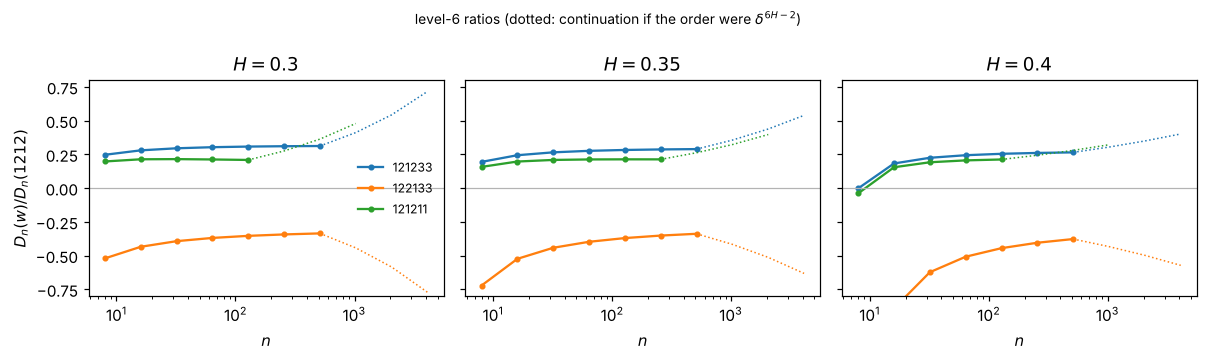

In [34]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
for axi, Hh in zip(axs, [0.3, 0.35, 0.4]):
    grow = 2 ** (1 - 2 * Hh)
    for w, col in [("121233", "C0"), ("122133", "C1"), ("121211", "C2")]:
        ns, rat = b_ratio_table(B_PRECOMP[Hh][w], B_PRECOMP[Hh]["1212"])
        axi.semilogx(ns, rat, "o-", color=col, ms=3, label=w)
        hyp = rat[-1] * grow ** np.arange(0, 4)            # what delta^(6H-2) growth would look like
        axi.semilogx(ns[-1] * 2.0 ** np.arange(0, 4), hyp, ":", color=col, lw=1)
    axi.axhline(0, color="0.7", lw=0.8)
    axi.set_title(f"$H={Hh}$")
    axi.set_xlabel("$n$")
axs[0].set_ylabel(r"$D_n(w)/D_n(1212)$")
axs[0].set_ylim(-0.8, 0.8)
axs[0].legend(frameon=False, fontsize=8)
fig.suptitle(r"level-6 ratios (dotted: continuation if the order were $\delta^{6H-2}$)", fontsize=9)
fig.tight_layout()
plt.show()

## B4. Sharpness of the canonical-correlation bound (Remark 6.7)

**Claim.** Discretizing both cells into $N$ subintervals, the largest singular value of
$G_{aa}^{-1/2}G_{ab}G_{bb}^{-1/2}$ has log-log slopes in $m$ within $10^{-3}$ of $2H-2$ at
$H=0.30,0.35,0.40,0.45,0.60,0.70$, with $\varrho_{\max}/\bar r(m)\to C_\infty(H)\in[1.00,1.06]$ and no drift
in $N$. Here $\bar r(m)=|c_H|\int_{[0,1]\times[m,m+1]}|u-v|^{2H-2}\,du\,dv$ (Proposition 6.6).

**Method.** Take the unit cells $I_a=[0,1]$ and $I_b=[m,m+1]$ (the correlation is scale invariant)
and the increments of fBm over $N$ equal subintervals of each. Their covariance matrices are
$G_{aa}=G_{bb}=N^{-2H}\bigl(r(i-j)\bigr)_{i,j}$ and $G_{ab}=N^{-2H}\bigl(r(mN+j-i)\bigr)_{i,j}$; the factor
$N^{-2H}$ cancels. The largest singular value of $G_{aa}^{-1/2}G_{ab}G_{bb}^{-1/2}$ (computed with Cholesky
factors) is the canonical correlation between the two $N$-dimensional spans. These spans increase along
$N=2^k$, so the computed value increases with $N$ towards $\varrho_{\max}$ from below. For large lags,
$r(k)$ is evaluated by its binomial series to avoid the cancellation in the second difference of
$|x|^{2H}$.

For integer lags $m\ge1$ the integral defining $\bar r(m)$ equals the covariance of the two unit
increments, so $\bar r(m)=|r(m)|$; we check this by quadrature below.

In [35]:
# r-bar(m) = |r(m)|: quadrature of the defining integral (inner integral in closed form)
def b_rbar_quad(m, H):
    cH = H * (2 * H - 1)
    f = lambda u: ((m + 1 - u) ** (2 * H - 1) - (m - u) ** (2 * H - 1)) / (2 * H - 1)   # int_m^{m+1} (v-u)^{2H-2} dv
    return abs(cH) * b_integrate.quad(f, 0, 1, epsabs=1e-13, epsrel=1e-13, limit=200)[0]


qerr = max(abs(b_rbar_quad(m, Hh) - abs(b_r(m, Hh))) for m in [1, 2, 5, 40] for Hh in [0.3, 0.45, 0.7])
print(f"rbar(m) by quadrature vs |r(m)| (m=1,2,5,40; H=0.3,0.45,0.7): max abs. difference {qerr:.1e}")


def b_rho_max(H, m, N):
    j = np.arange(N)
    Gaa = b_toeplitz(b_r(j, H))
    Gab = b_r(m * N + j[None, :] - j[:, None], H)
    La = b_cholesky(Gaa, lower=True)
    M = b_solve_tri(La, Gab, lower=True)
    M = b_solve_tri(La, M.T, lower=True).T                 # G_bb = G_aa (stationarity)
    return b_svdvals(M)[0]


b4_H = [0.30, 0.35, 0.40, 0.45, 0.60, 0.70]
b4_m = 2 ** np.arange(0, 11)                                # m = 1..1024
b4_N = [16, 32, 64] if QUICK else [16, 32, 64, 128, 256]
b4_Next = [64, 128, 256, 512] if QUICK else [64, 128, 256, 512, 1024, 2048]
t0 = time.time()
b4_res = {}
b4_sum = {}
b4_ok = qerr < 1e-10
print(f"N in {b4_N};  m = 1, 2, 4, ..., 1024;  slopes are local, between m and 2m")
for Hh in b4_H:
    rb = np.abs(b_r(b4_m, Hh))
    tab = np.array([[b_rho_max(Hh, m, N) for m in b4_m] for N in b4_N])
    b4_res[Hh] = tab
    slopes = np.diff(np.log(tab[-1])) / np.diff(np.log(b4_m))
    dev = np.abs(slopes - (2 * Hh - 2))
    # first m from which all later local slopes are within 1e-3
    good = [i for i in range(len(dev)) if np.all(dev[i:] < 1e-3)]
    m_from = int(b4_m[good[0]]) if good else None
    # N -> infinity at m = 256: values increase like C - c/N; one Aitken step
    v = np.array([b_rho_max(Hh, 256, N) for N in b4_Next]) / abs(b_r(256, Hh))
    d = np.diff(v)
    q = d[-1] / d[-2]
    Cinf = v[-1] + d[-1] * q / (1 - q)
    ratioN = tab[:, -1] / rb[-1]
    ok = (m_from is not None and m_from <= 64) and 1.0 <= Cinf <= 1.06
    b4_ok &= ok
    b4_sum[Hh] = (m_from, Cinf, (Cinf - v[0]) / v[0])
    print(f"H={Hh:.2f}: |slope-(2H-2)| for m=1..512: " + " ".join(f"{x:.1e}" for x in dev))
    print(f"         within 1e-3 for all m >= {m_from};  rho/rbar at m=1024 for N={b4_N}: "
          + " ".join(f"{x:.5f}" for x in ratioN))
    print(f"         m=256, N={b4_Next}: " + " ".join(f"{x:.6f}" for x in v)
          + f"  -> C_inf ~ {Cinf:.4f}  {b_verdict(ok)}")
print(f"({time.time()-t0:.1f}s)")
print("paper: slopes within 1e-3 of 2H-2, C_inf in [1.00, 1.06], no drift in N;")
print("computed: slopes within 1e-3 of 2H-2 for m >= " + ", ".join(f"{b4_sum[h][0]} (H={h})" for h in b4_H)
      + "; not for small m (deviation ~1 at m=1, ~0.1 at m=2)")
print(f"          C_inf between {min(x[1] for x in b4_sum.values()):.4f} and {max(x[1] for x in b4_sum.values()):.4f};"
      f" the N-drift is monotone (nested subspaces) and of order 1/N; from N=64 to N=inf it is at most"
      f" {100*max(x[2] for x in b4_sum.values()):.2f}% (at H=0.3).")
print("B4 overall:", b_verdict(b4_ok))

rbar(m) by quadrature vs |r(m)| (m=1,2,5,40; H=0.3,0.45,0.7): max abs. difference 3.3e-15
N in [16, 32, 64];  m = 1, 2, 4, ..., 1024;  slopes are local, between m and 2m
H=0.30: |slope-(2H-2)| for m=1..512: 1.6e+00 1.1e-01 2.4e-02 5.9e-03 1.5e-03 3.7e-04 9.2e-05 2.3e-05 5.8e-06 1.4e-06
         within 1e-3 for all m >= 32;  rho/rbar at m=1024 for N=[16, 32, 64]: 1.04484 1.05106 1.05446
         m=256, N=[64, 128, 256, 512]: 1.054466 1.056265 1.057197 1.057674  -> C_inf ~ 1.0582  OK


H=0.35: |slope-(2H-2)| for m=1..512: 1.5e+00 1.0e-01 2.3e-02 5.5e-03 1.4e-03 3.4e-04 8.6e-05 2.1e-05 5.4e-06 1.3e-06
         within 1e-3 for all m >= 32;  rho/rbar at m=1024 for N=[16, 32, 64]: 1.02123 1.02394 1.02539
         m=256, N=[64, 128, 256, 512]: 1.025392 1.026152 1.026542 1.026740  -> C_inf ~ 1.0269  OK
H=0.40: |slope-(2H-2)| for m=1..512: 1.3e+00 9.3e-02 2.1e-02 5.1e-03 1.3e-03 3.2e-04 7.9e-05 2.0e-05 5.0e-06 1.2e-06
         within 1e-3 for all m >= 32;  rho/rbar at m=1024 for N=[16, 32, 64]: 1.00801 1.00896 1.00947
         m=256, N=[64, 128, 256, 512]: 1.009468 1.009729 1.009863 1.009930  -> C_inf ~ 1.0100  OK


H=0.45: |slope-(2H-2)| for m=1..512: 1.2e+00 8.5e-02 1.9e-02 4.7e-03 1.2e-03 2.9e-04 7.3e-05 1.8e-05 4.5e-06 1.1e-06
         within 1e-3 for all m >= 32;  rho/rbar at m=1024 for N=[16, 32, 64]: 1.00171 1.00190 1.00200
         m=256, N=[64, 128, 256, 512]: 1.002000 1.002052 1.002078 1.002091  -> C_inf ~ 1.0021  OK
H=0.60: |slope-(2H-2)| for m=1..512: 8.4e-01 6.2e-02 1.4e-02 3.4e-03 8.5e-04 2.1e-04 5.3e-05 1.3e-05 3.3e-06 8.2e-07
         within 1e-3 for all m >= 16;  rho/rbar at m=1024 for N=[16, 32, 64]: 1.00420 1.00460 1.00481
         m=256, N=[64, 128, 256, 512]: 1.004812 1.004918 1.004971 1.004998  -> C_inf ~ 1.0050  OK


H=0.70: |slope-(2H-2)| for m=1..512: 6.2e-01 4.7e-02 1.0e-02 2.6e-03 6.3e-04 1.6e-04 4.0e-05 9.9e-06 2.5e-06 6.2e-07
         within 1e-3 for all m >= 16;  rho/rbar at m=1024 for N=[16, 32, 64]: 1.01156 1.01259 1.01311
         m=256, N=[64, 128, 256, 512]: 1.013113 1.013379 1.013513 1.013580  -> C_inf ~ 1.0136  OK
(0.9s)
paper: slopes within 1e-3 of 2H-2, C_inf in [1.00, 1.06], no drift in N;
computed: slopes within 1e-3 of 2H-2 for m >= 32 (H=0.3), 32 (H=0.35), 32 (H=0.4), 32 (H=0.45), 16 (H=0.6), 16 (H=0.7); not for small m (deviation ~1 at m=1, ~0.1 at m=2)
          C_inf between 1.0021 and 1.0582; the N-drift is monotone (nested subspaces) and of order 1/N; from N=64 to N=inf it is at most 0.35% (at H=0.3).
B4 overall: OK


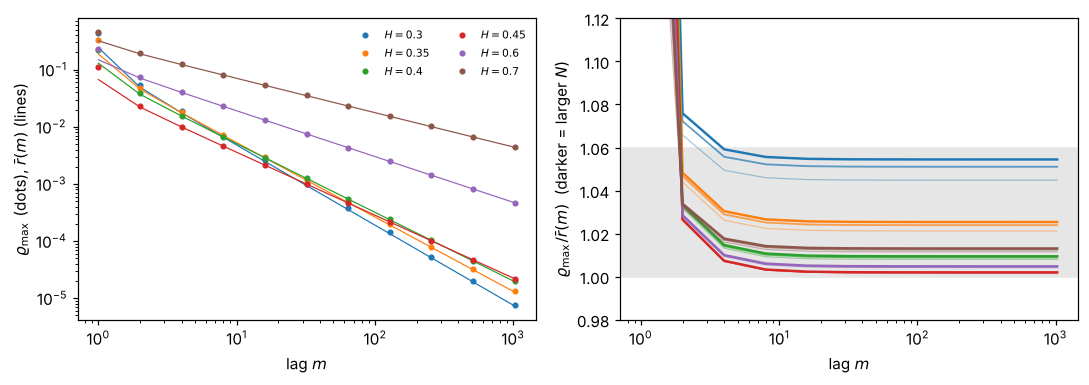

Part B finished in 26.6s


In [36]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for k, Hh in enumerate(b4_H):
    rb = np.abs(b_r(b4_m, Hh))
    ax[0].loglog(b4_m, b4_res[Hh][-1], "o", ms=3, color=f"C{k}", label=f"$H={Hh}$")
    ax[0].loglog(b4_m, rb, "-", lw=0.8, color=f"C{k}")
    for i, N in enumerate(b4_N):
        ax[1].semilogx(b4_m, b4_res[Hh][i] / rb, "-", lw=0.8 + 0.4 * i, color=f"C{k}", alpha=0.4 + 0.6 * i / max(1, len(b4_N) - 1))
ax[0].set_xlabel("lag $m$")
ax[0].set_ylabel(r"$\varrho_{\max}$ (dots), $\bar r(m)$ (lines)")
ax[0].legend(frameon=False, fontsize=7, ncol=2)
ax[1].axhspan(1.0, 1.06, color="0.9")
ax[1].set_ylim(0.98, 1.12)
ax[1].set_xlabel("lag $m$")
ax[1].set_ylabel(r"$\varrho_{\max}/\bar r(m)$  (darker = larger $N$)")
fig.tight_layout()
plt.show()

print(f"Part B finished in {time.time()-b_T0:.1f}s")

# Part C: the strong error and the separation (Sections 7 and 8)

This part reproduces the numerical values quoted in Section 7 (the strong error) and Section 8
(the weak error cannot be removed using the mesh data), and checks the other explicit constants
of Sections 7–9 and of the two appendices.

* **C1.** Remark 7.3: the sign of the cross-cell area correlations $\rho_A(m)$, the table
  of $\rho_A(0)$, $2\sum_{m\ge1}\rho_A(m)$ and $\sigma^2_\infty$, and the ratio of the lower bound of
  Lemma 7.2 to $\sigma^2_\infty$.
* **C2.** Remark 8.10: the table of $W(H)$ and $\Theta(H)$, the value $\Theta(\tfrac12)=-\tfrac1{12}$
  from the series of Lemma 8.9, the separation constant $\kappa_{\rm sep}$ of Proposition
  Proposition 8.3, and the Brownian separation of Proposition 8.4.
* **C3.** Proposition 7.4: a Monte Carlo illustration of the strong rate $\delta^{4H-1}$
  (in mean square). The paper quotes no number here.
* **C4.** The remaining explicit constants of Sections 7–9 and of Appendices A and B.

All evaluations in C1, C2 and C4 are deterministic: closed forms, exact Isserlis sums, or
quadrature whose error is checked by refinement. Only C3 is Monte Carlo.
Everything in C1, C2 and C4 is fast, so QUICK and FULL mode compute the same values; the modes
differ only in the size of the Monte Carlo experiment of C3.

In [37]:
QUICK = globals().get("QUICK", True)
import warnings
import mpmath as mp
from scipy import integrate
from numpy.polynomial.legendre import leggauss

c_T0 = time.time()
print("Part C runs in", "QUICK" if QUICK else "FULL", "mode")


def c_verdict(ok):
    return "OK" if ok else "MISMATCH"


def c_tanhsinh(h=1 / 32, tmax=3.3):
    """Tanh-sinh (double exponential) nodes on (0,1): returns x, 1-x (computed without
    cancellation) and the weights. Integrable algebraic singularities at 0 and 1 are handled
    with exponential convergence in 1/h."""
    t = np.arange(-tmax, tmax + h / 2, h)
    a = 0.5 * np.pi * np.sinh(t)
    x = 1 / (1 + np.exp(-2 * a))
    xc = 1 / (1 + np.exp(2 * a))
    w = h * np.pi * np.cosh(t) * x * xc
    return x, xc, w


c_GL = leggauss(24)
c_GLX, c_GLW = (c_GL[0] + 1) / 2, c_GL[1] / 2           # Gauss-Legendre on [0,1]


def c_Einf(H):
    """Continuum level-4 coordinates (adj, alt, nest) of fBm(H), Proposition 6.10."""
    g = mp.gamma
    H = mp.mpf(H)
    adj = H * g(2 * H) ** 2 / (4 * (4 * H - 1) * g(4 * H - 1))
    alt = H / (4 * (4 * H - 1)) * (1 - g(2 * H) ** 2 / g(4 * H - 1))
    nest = (2 * H - 1) / (8 * (4 * H - 1))
    return float(adj), float(alt), float(nest)

Part C runs in QUICK mode


## C1. The area correlations $\rho_A(m)$ and the long-run variance $\sigma^2_\infty$

**Claim (Remark 7.3).** Let $\tilde A_a$ be the Lévy area over
$[a,a+1]$ of two independent fBm$(H)$ and $\rho_A(m)=\mathrm{Cov}(\tilde A_0,\tilde A_m)$.
(i) $\rho_A(m)<0$ for $1\le m\le 60$ at $H=0.51,0.52,\dots,0.99$. (ii) At $H=0.6,0.7,0.8$:

| $H$ | 0.6 | 0.7 | 0.8 |
|---|---|---|---|
| $\rho_A(0)=2(E^\infty_{\rm adj}-E^\infty_{\rm nest})$ | 0.1678893 | 0.1087955 | 0.0635642 |
| $2\sum_{m\ge1}\rho_A(m)$ | −0.0013655 | −0.0042364 | −0.0067924 |
| $\sigma^2_\infty$ | 0.166524 | 0.104559 | 0.056772 |

(iii) The explicit lower bound $2\pi q(0)$ of Lemma 7.2 equals $0.61$, $0.56$, $0.49$ times
$\sigma^2_\infty$.

**Method.** Step 1 of Lemma 7.1 writes $\rho_A(m)$ as the four-fold integral
$\tfrac14\iint_{I_0}\iint_{I_m}\mathrm{sgn}(t-s)\,\mathrm{sgn}(t'-s')\,\varrho(s,s')\,\varrho(t,t')$
with $\varrho(u,v)=c_H|u-v|^{2H-2}$. We integrate out the two variables $s,s'$ in closed form.
On a cell the Lévy area is $\tilde A_0=\int_0^1Y_t\,\mathrm dB^2_t$ with
$Y_t=B^1_t-\tfrac12(B^1_0+B^1_1)=\tfrac12\int_0^1\mathrm{sgn}(t-s)\,\mathrm dB^1_s$, so

$$\rho_A(m)=\int_0^1\!\!\int_0^1 K_m(u,v)\,c_H\,(m+v-u)^{2H-2}\,\mathrm du\,\mathrm dv,\qquad
  K_m(u,v)=\mathrm{Cov}(Y_u,Y'_v)=\tfrac14\iint\mathrm{sgn}(u-s)\,\mathrm{sgn}(v-s')\,\varrho(s,m+s'),$$

where $Y'$ is the same object on $[m,m+1]$. $K_m$ is a combination of four increment covariances
$\tfrac12(|d-a|^{2H}+|c-b|^{2H}-|c-a|^{2H}-|d-b|^{2H})$, which we evaluate relative to the distance
$m$ (with `expm1`/`log1p`) to avoid cancellation at large lags.

* For $m\ge2$ the integrand is analytic on the closed unit square, and a $24\times24$ Gauss–Legendre
  rule is accurate to about $10^{-8}$ relative (checked against a 40-digit `mpmath` quadrature).
* For $m=1$ the kernel has an integrable corner singularity at $(u,v)=(1,0)$. With $x=1-u$, $y=v$,
  $x=\rho c$, $y=\rho(1-c)$ the singularity becomes $\rho^{2H-1}$, and a tanh-sinh rule in
  $(c,\rho)$ converges to machine precision.
* $\rho_A(0)=2(E^\infty_{\rm adj}-E^\infty_{\rm nest})$ is the closed form of the remark.

The tail $\sum_{m>200}\rho_A(m)$ uses the asymptote of Lemma 7.1,
$\rho_A(m)\approx\frac{c_H^2(2H-2)}{72}m^{4H-6}$, summed exactly with the Hurwitz zeta function. Its
size is at most $10^{-7}$, and the neglected $O(m^{-1})$ correction affects only the ninth decimal.

**Brute-force check.** For the piecewise-linear interpolants of $(B^1,B^2)$ on the fine mesh $1/k$
the cell area is the finite double sum $\tfrac12\sum_{j,j'}\mathrm{sgn}(j'-j)\,\Delta^1_j\Delta^2_{j'}$,
and Isserlis' theorem gives its covariance exactly:
$\rho^{(k)}_A(m)=\tfrac14\sum_{j,j',l,l'}\mathrm{sgn}(j'-j)\,\mathrm{sgn}(l'-l)\,R_{jl}R_{j'l'}$, with $R$ the
fGn covariance of the fine increments. This discretises the four-fold integral of Step 1 directly.
As $k\to\infty$ it converges to $\rho_A(m)$ (at rate $k^{-2}$ for $m\ge1$, $k^{-(4H-1)}$ for $m=0$), and a
Richardson extrapolation removes the leading terms.

In [38]:
def c_K(u, v, m, H):
    """K_m(u,v) = Cov(Y_u, Y'_v) for the cells [0,1] and [m,m+1], m >= 1."""
    if m == 1:
        p = lambda z: np.abs(z) ** (2 * H)
        ci = lambda a, b, c, d: 0.5 * (p(1 + d - a) + p(1 + c - b) - p(1 + c - a) - p(1 + d - b))
    else:  # distances m+e, written as m^{2H} (1+e/m)^{2H}; the constant parts cancel
        g = lambda e: np.expm1(2 * H * np.log1p(e / m))
        ci = lambda a, b, c, d: 0.5 * m ** (2 * H) * (g(d - a) + g(c - b) - g(c - a) - g(d - b))
    # Cov(B_{a,b}, B_{m+c,m+d}) = ci(a,b,c,d); Y_u = (B_{0,u} - B_{u,1})/2
    return 0.25 * (ci(0, u, 0, v) - ci(0, u, v, 1) - ci(u, 1, 0, v) + ci(u, 1, v, 1))


def c_rhoA0(H):
    adj, alt, nest = c_Einf(H)
    return 2 * (adj - nest)


def c_rhoA_far(m, H, X=c_GLX, Wt=c_GLW):
    """rho_A(m), m >= 2, by tensor Gauss-Legendre (analytic integrand)."""
    cH = H * (2 * H - 1)
    U, V = np.meshgrid(X, X, indexing="ij")
    ker = cH * m ** (2 * H - 2) * np.exp((2 * H - 2) * np.log1p((V - U) / m))
    return np.sum(np.outer(Wt, Wt) * c_K(U, V, m, H) * ker)


def c_rhoA1(H, h=1 / 32):
    """rho_A(1): polar coordinates around the singular corner, tanh-sinh in both variables."""
    cH = H * (2 * H - 1)
    x, xc, w = c_tanhsinh(h)
    tot = 0.0
    for lo, hi in [(0, 0.5), (0.5, 1)]:          # rho_max(c) = 1/max(c,1-c) has a kink at c=1/2
        c = lo + (hi - lo) * x
        rmax = 1 / np.maximum(c, 1 - c)
        C, Z = np.meshgrid(c, x, indexing="ij")
        RM = rmax[:, None]
        rho = RM * Z
        F = c_K(1 - rho * C, rho * (1 - C), 1, H) * cH * rho ** (2 * H - 1) * RM
        tot += np.sum(np.outer((hi - lo) * w, w) * F)
    return tot


def c_rhoA(m, H):
    m = abs(int(m))
    if m == 0:
        return c_rhoA0(H)
    return c_rhoA1(H) if m == 1 else c_rhoA_far(m, H)


def c_rhoA_asym(m, H):
    cH = H * (2 * H - 1)
    return cH ** 2 * (2 * H - 2) / 72 * np.asarray(m, float) ** (4 * H - 6)


def c_rhoA_discrete(m, H, k):
    """Exact (Isserlis) covariance of the areas of the fine piecewise-linear interpolants
    (mesh 1/k) over the unit cells [0,1] and [m,m+1]."""
    j = np.arange(k)
    S = np.sign(j[None, :] - j[:, None]).astype(float)      # S[j,j'] = sgn(j'-j)
    R = (1.0 / k) ** (2 * H) * fgn_autocov(m * k + j[None, :] - j[:, None], H)  # R[j,l]
    return 0.25 * np.sum((S @ R) * (R @ S))


def c_rhoA_discrete_loops(m, H, k):
    """Same quantity with four explicit loops (used once, on a tiny mesh)."""
    tot = 0.0
    R = lambda j, l: (1.0 / k) ** (2 * H) * float(fgn_autocov(m * k + l - j, H))
    for j in range(k):
        for jp in range(k):
            for l in range(k):
                for lp in range(k):
                    tot += np.sign(jp - j) * np.sign(lp - l) * R(j, l) * R(jp, lp)
    return 0.25 * tot


# --- brute-force checks --------------------------------------------------------
print("Check 1: matrix form of the Isserlis sum against four explicit loops (k = 4)")
for (H, m) in [(0.7, 0), (0.6, 1), (0.8, 3)]:
    a, b = c_rhoA_discrete(m, H, 4), c_rhoA_discrete_loops(m, H, 4)
    print(f"  H={H}, m={m}: {a:.15e}  {b:.15e}  ", c_verdict(abs(a - b) < 1e-15))

print("\nCheck 2: Richardson limit of the fine-mesh Isserlis sums against the exact evaluator")
c_ks = [64, 128, 256, 512]
for (H, m) in [(0.6, 0), (0.8, 0), (0.7, 1), (0.6, 2), (0.8, 5)]:
    vals = np.array([c_rhoA_discrete(m, H, k) for k in c_ks])
    exps = [4 * H - 1, 2.0, 3.0] if m == 0 else [2.0, 3.0, 4.0]
    V = np.column_stack([np.ones(len(c_ks))] + [np.array(c_ks, float) ** (-e) for e in exps])
    lim = np.linalg.solve(V, vals)[0]
    ex = c_rhoA(m, H)
    rel = abs(lim - ex) / abs(ex)
    print(f"  H={H}, m={m}:  k=512 sum {vals[-1]:.10e}   extrapolated {lim:.10e}   exact {ex:.10e}"
          f"   rel.diff {rel:.1e}  ", c_verdict(rel < 1e-5))

print("\nCheck 3: the 24-point Gauss-Legendre rule against a 40-point rule, and rho_A(1) at h and h/2")
X40, W40 = leggauss(40)
X40, W40 = (X40 + 1) / 2, W40 / 2
dmax = max(abs(c_rhoA_far(m, H) / c_rhoA_far(m, H, X40, W40) - 1)
           for H in [0.51, 0.75, 0.99] for m in [2, 10, 60, 200])
d1 = max(abs(c_rhoA1(H) / c_rhoA1(H, 1 / 64) - 1) for H in [0.51, 0.75, 0.99])
print(f"  max relative change (m>=2): {dmax:.1e};  rho_A(1): {d1:.1e}  ", c_verdict(dmax < 1e-6 and d1 < 1e-10))

Check 1: matrix form of the Isserlis sum against four explicit loops (k = 4)
  H=0.7, m=0: 9.217982525968747e-02  9.217982525968747e-02   OK
  H=0.6, m=1: -4.740448039989150e-04  -4.740448039989077e-04   OK
  H=0.8, m=3: -5.466238693797507e-05  -5.466238693799117e-05   OK

Check 2: Richardson limit of the fine-mesh Isserlis sums against the exact evaluator
  H=0.6, m=0:  k=512 sum 1.6784354240e-01   extrapolated 1.6788930505e-01   exact 1.6788931550e-01   rel.diff 6.2e-08   OK
  H=0.8, m=0:  k=512 sum 6.3563166954e-02   extrapolated 6.3564229324e-02   exact 6.3564229527e-02   rel.diff 3.2e-09   OK
  H=0.7, m=1:  k=512 sum -1.9952966833e-03   extrapolated -1.9953608168e-03   exact -1.9953616845e-03   rel.diff 4.3e-07   OK
  H=0.6, m=2:  k=512 sum -1.5916184379e-05   extrapolated -1.5916318676e-05   exact -1.5916318676e-05   rel.diff 5.2e-13   OK
  H=0.8, m=5:  k=512 sum -1.4403344641e-05   extrapolated -1.4403455456e-05   exact -1.4403455456e-05   rel.diff 1.0e-11   OK

Check 3: the 24-

  max relative change (m>=2): 5.5e-07;  rho_A(1): 2.8e-14   OK


### (i) The sign of $\rho_A(m)$ for $1\le m\le60$ on the grid $H=0.51,\dots,0.99$

The values are tiny near $H=\tfrac12$ (where $c_H\to0$, so $\rho_A(m)=O(c_H^2)$) and at large lags
(where $\rho_A(m)\asymp m^{4H-6}$). The smallest value in absolute terms, at $H=0.51$, $m=60$, is about
$10^{-13}$; the evaluator is accurate to about $10^{-8}$ relative there (40-digit check below), so the
sign is resolved with a wide margin.

In [39]:
c_Hgrid = np.round(np.arange(0.51, 0.9951, 0.01), 2)
c_mgrid = np.arange(1, 61)
c_G = np.array([[c_rhoA(m, H) for m in c_mgrid] for H in c_Hgrid])
iH, im = np.unravel_index(np.argmax(c_G), c_G.shape)
print(f"grid: {len(c_Hgrid)} values of H x {len(c_mgrid)} lags")
print(f"largest rho_A(m) on the grid: {c_G.max():.3e} at H={c_Hgrid[iH]}, m={c_mgrid[im]}")
print("all negative:", bool((c_G < 0).all()), " ", c_verdict(bool((c_G < 0).all())))

# 40-digit spot check of the smallest value
mp.mp.dps = 40


def c_rhoA_mp(m, H):
    H = mp.mpf(H)
    cH = H * (2 * H - 1)
    p = lambda z: abs(z) ** (2 * H)
    ci = lambda a, b, c, d: (p(d - a) + p(c - b) - p(c - a) - p(d - b)) / 2
    K = lambda u, v: (ci(0, u, m, m + v) - ci(0, u, m + v, m + 1) - ci(u, 1, m, m + v) + ci(u, 1, m + v, m + 1)) / 4
    return mp.quad(lambda u, v: K(u, v) * cH * (m + v - u) ** (2 * H - 2), [0, 1], [0, 1])


c_ref = c_rhoA_mp(60, 0.51)
mp.mp.dps = 15
print(f"H=0.51, m=60: double precision {c_rhoA(60, 0.51):.10e}, 40 digits {float(c_ref):.10e}  ",
      c_verdict(abs(c_rhoA(60, 0.51) / float(c_ref) - 1) < 1e-6))

grid: 49 values of H x 60 lags
largest rho_A(m) on the grid: -1.287e-13 at H=0.51, m=60
all negative: True   OK


H=0.51, m=60: double precision -1.2873897651e-13, 40 digits -1.2873897514e-13   OK


The plot shows $-\rho_A(m)$ against the asymptote $\frac{c_H^2(2-2H)}{72}m^{4H-6}$ of Lemma
Lemma 7.1 (left), and the ratio of the two, which tends to $1$ at rate $O(m^{-1})$ (right).

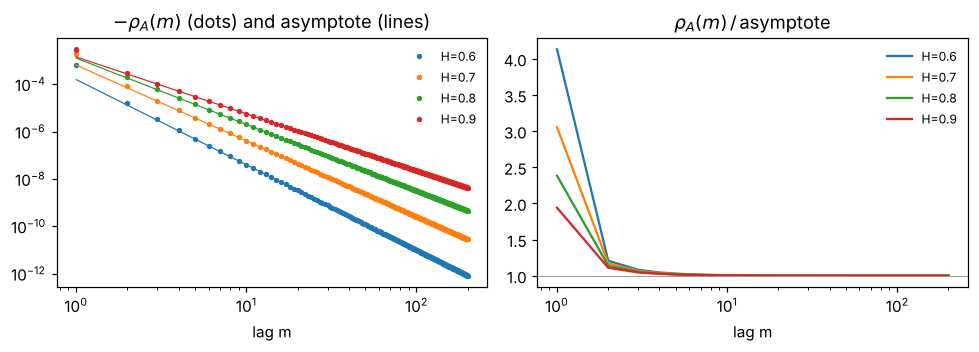

In [40]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.3))
ms = np.arange(1, 201)
for H in [0.6, 0.7, 0.8, 0.9]:
    rr = np.array([c_rhoA(m, H) for m in ms])
    l, = axs[0].loglog(ms, -rr, "o", ms=2.5, label=f"H={H}")
    axs[0].loglog(ms, -c_rhoA_asym(ms, H), "-", lw=0.8, color=l.get_color())
    axs[1].semilogx(ms, rr / c_rhoA_asym(ms, H), "-", color=l.get_color(), label=f"H={H}")
axs[0].set_xlabel("lag m"); axs[0].set_title(r"$-\rho_A(m)$ (dots) and asymptote (lines)")
axs[1].axhline(1, color="0.6", lw=0.6)
axs[1].set_xlabel("lag m"); axs[1].set_title(r"$\rho_A(m)\,/\,$asymptote")
axs[0].legend(frameon=False, fontsize=8); axs[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

### (ii) The table of Remark 7.3, and (iii) the lower bound of Lemma 7.2

$\sigma^2_\infty=\rho_A(0)+2\sum_{m=1}^{200}\rho_A(m)+2\sum_{m>200}\rho_A(m)$, the last sum from the
asymptote. The lower bound is
$2\pi q(0)=2\pi C_H^2\int_{\mathbb R}\frac{(\lambda-\sin\lambda)^2}{\lambda^4}|\lambda|^{2-4H}\,\mathrm d\lambda$ with
$C_H=\Gamma(2H+1)\sin(\pi H)/(2\pi)$, evaluated with `mpmath` quadrature (for $\lambda<10^{-3}$ we use
the Taylor series of $\lambda-\sin\lambda$, which avoids cancellation). We also check that $C_H$
agrees with the constant obtained from $\int e^{\mathrm iu\lambda}|\lambda|^{-\alpha}\mathrm d\lambda
=2\Gamma(1-\alpha)\sin(\tfrac{\pi\alpha}2)|u|^{\alpha-1}$, $\alpha=2H-1$, as stated in the lemma.

In [41]:
c_MEX = 200


def c_sigma2_parts(H):
    r0 = c_rhoA0(H)
    cross = sum(c_rhoA(m, H) for m in range(1, c_MEX + 1))
    cH = H * (2 * H - 1)
    tail = cH ** 2 * (2 * H - 2) / 72 * float(mp.zeta(6 - 4 * H, c_MEX + 1))
    return r0, 2 * (cross + tail), r0 + 2 * (cross + tail), 2 * tail


def c_lrv_lower(H):
    H = mp.mpf(H)
    CH = mp.gamma(2 * H + 1) * mp.sin(mp.pi * H) / (2 * mp.pi)

    def f(lam):
        if lam < mp.mpf("1e-3"):
            d = lam ** 3 / 6 - lam ** 5 / 120 + lam ** 7 / 5040
        else:
            d = lam - mp.sin(lam)
        return d ** 2 / lam ** 4 * lam ** (2 - 4 * H)

    I = 2 * mp.quad(f, [0, 1, 10, 100, mp.inf])
    return float(2 * mp.pi * CH ** 2 * I)


c_paper_C1 = {0.6: (0.1678893, -0.0013655, 0.166524, 0.61),
              0.7: (0.1087955, -0.0042364, 0.104559, 0.56),
              0.8: (0.0635642, -0.0067924, 0.056772, 0.49)}
print(f"{'H':>4} | {'rho_A(0)':>22} | {'2 sum_{m>=1} rho_A(m)':>24} | {'sigma^2_inf':>20} | {'LB/sigma^2':>12} | "
      f"2 rho_A(1)/(2 sum) | tail")
c_C1_ok = True
c_sig2 = {}
for H, (p0, ps, psig, pr) in c_paper_C1.items():
    r0, cs, s2, tail = c_sigma2_parts(H)
    c_sig2[H] = s2
    lb = c_lrv_lower(H)
    ok = (round(r0, 7) == p0) and (round(cs, 7) == ps) and (round(s2, 6) == psig) and (round(lb / s2, 2) == pr)
    c_C1_ok &= ok
    print(f"{H:>4} | {r0:.9f} (paper {p0}) | {cs:.9f} (paper {ps}) | {s2:.8f} (paper {psig}) | "
          f"{lb / s2:.4f} ({pr}) | {2 * c_rhoA(1, H) / cs:.3f} | {tail:.1e}   {c_verdict(ok)}")
print("C1 table:", c_verdict(c_C1_ok))

print("\nThe spectral constant C_H of Lemma 7.2:")
for H in [0.6, 0.7, 0.8]:
    CH = float(mp.gamma(2 * H + 1) * mp.sin(mp.pi * H) / (2 * mp.pi))
    al = 2 * H - 1
    CH2 = H * (2 * H - 1) / float(2 * mp.gamma(1 - al) * mp.sin(mp.pi * al / 2))
    print(f"  H={H}: Gamma(2H+1) sin(pi H)/(2 pi) = {CH:.12f},  c_H / (2 Gamma(1-a) sin(pi a/2)) = {CH2:.12f}  ",
          c_verdict(abs(CH - CH2) < 1e-12))

   H |               rho_A(0) |    2 sum_{m>=1} rho_A(m) |          sigma^2_inf |   LB/sigma^2 | 2 rho_A(1)/(2 sum) | tail
 0.6 | 0.167889315 (paper 0.1678893) | -0.001365460 (paper -0.0013655) | 0.16652386 (paper 0.166524) | 0.6119 (0.61) | 0.968 | -1.3e-10   OK


 0.7 | 0.108795469 (paper 0.1087955) | -0.004236421 (paper -0.0042364) | 0.10455905 (paper 0.104559) | 0.5569 (0.56) | 0.942 | -5.1e-09   OK
 0.8 | 0.063564230 (paper 0.0635642) | -0.006792364 (paper -0.0067924) | 0.05677187 (paper 0.056772) | 0.4878 (0.49) | 0.898 | -1.0e-07   OK
C1 table: OK

The spectral constant C_H of Lemma 7.2:
  H=0.6: Gamma(2H+1) sin(pi H)/(2 pi) = 0.166774714956,  c_H / (2 Gamma(1-a) sin(pi a/2)) = 0.166774714956   OK
  H=0.7: Gamma(2H+1) sin(pi H)/(2 pi) = 0.159940549334,  c_H / (2 Gamma(1-a) sin(pi a/2)) = 0.159940549334   OK
  H=0.8: Gamma(2H+1) sin(pi H)/(2 pi) = 0.133739845465,  c_H / (2 Gamma(1-a) sin(pi a/2)) = 0.133739845465   OK


The plot shows, over the Young range, the single-cell variance $\rho_A(0)$, the long-run variance
$\sigma^2_\infty$ and the lower bound $2\pi q(0)$ of Lemma 7.2. The cross-cell reduction grows with
$H$ but stays small, and the lower bound captures roughly half of $\sigma^2_\infty$.

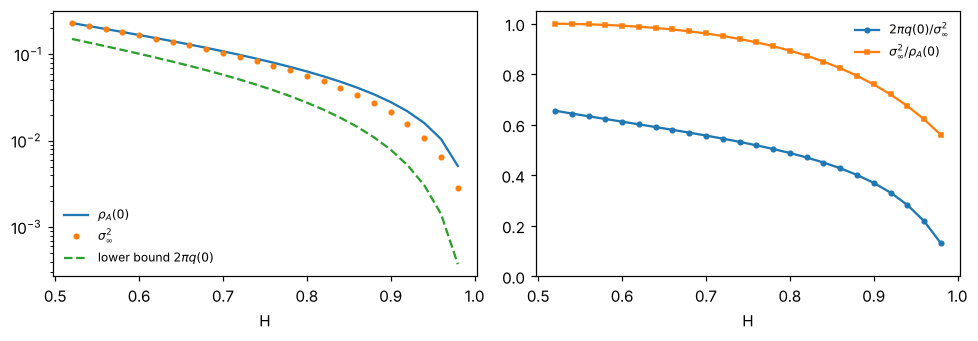

[C1 done, 11.0 s]


In [42]:
Hs = np.round(np.arange(0.52, 0.981, 0.02), 2)
P = np.array([c_sigma2_parts(H) for H in Hs])
LB = np.array([c_lrv_lower(H) for H in Hs])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(Hs, P[:, 0], label=r"$\rho_A(0)$")
ax[0].plot(Hs, P[:, 2], "o", ms=3, label=r"$\sigma^2_\infty$")
ax[0].plot(Hs, LB, "--", label=r"lower bound $2\pi q(0)$")
ax[0].set_xlabel("H"); ax[0].legend(frameon=False, fontsize=8); ax[0].set_yscale("log")
ax[1].plot(Hs, LB / P[:, 2], "o-", ms=3, label=r"$2\pi q(0)/\sigma^2_\infty$")
ax[1].plot(Hs, P[:, 2] / P[:, 0], "s-", ms=3, label=r"$\sigma^2_\infty/\rho_A(0)$")
ax[1].set_xlabel("H"); ax[1].legend(frameon=False, fontsize=8); ax[1].set_ylim(0, 1.05)
fig.tight_layout(); plt.show()
print(f"[C1 done, {time.time() - c_T0:.1f} s]")

## C2. The constants $W$, $\Theta$ and $\kappa_{\rm sep}$ of the separation

**Claim (Remark 8.10).** With $B_H$ the covariance of the tied-down
fBm $Z_u-uZ_1$ and
$\Theta(H)=\int_{[0,1]^2}\partial_uB_H\,\partial_vB_H$, $W(H)=\int_{[0,1]^2}\partial_uB_H(u,v)\,\mathrm{sgn}(v-u)|v-u|^{2H-1}$
(Lemma 8.9):

| $H$ | 0.28 | 0.30 | 0.35 | 0.40 | 0.45 | 1/2 |
|---|---|---|---|---|---|---|
| $W(H)$ | 4.2459 | 2.5315 | 1.1947 | 0.7231 | 0.4800 | 1/3 |
| $\Theta(H)$ | −1.0866 | −0.6566 | −0.3165 | −0.1918 | −0.1249 | −1/12 |

and $\Theta(\tfrac12)=-\tfrac{16}{\pi^4}\sum_{k+l\ \rm odd}(l^2-k^2)^{-2}=-\tfrac1{12}$.

**Method.** The derivative is explicit,
$\partial_uB_H(u,v)=H(1-v)u^{2H-1}-vH(1-u)^{2H-1}-C(v,1)+v+H\,\mathrm{sgn}(v-u)|v-u|^{2H-1}$, and
$\partial_vB_H(u,v)=\partial_uB_H(v,u)$. Both integrals reduce to the triangle $u<v$:
$\Theta=2\int_{u<v}\partial_uB_H(u,v)\,\partial_uB_H(v,u)$ and
$W=\int_{u<v}[\partial_uB_H(u,v)-\partial_uB_H(v,u)]\,(v-u)^{2H-1}$. We parametrise the triangle by
$v=u+s(1-u)$, $s\in(0,1)$. The integrands have algebraic singularities on the edges, the strongest
being $|v-u|^{4H-2}$ on the diagonal $s=0$ (exponent close to $-1$ near $H=\tfrac14$). The substitution
$s=z^{1/(4H-1)}$ removes it, and a tanh-sinh rule in $(u,z)$ then converges rapidly; the code compares
the step $h=1/32$ with $h=1/64$. At $H=\tfrac12$, $B_{1/2}(u,v)=\min(u,v)-uv$ (the Brownian bridge) and
the exact values are $W=\tfrac13$, $\Theta=-\tfrac1{12}$.

In [43]:
def c_dB(u, uc, v, vc, r, sg, H):
    """d/du B_H(u,v), with uc=1-u, vc=1-v, r=|v-u| and sg = sgn(v-u) passed separately."""
    a = 2 * H - 1
    return H * vc * u ** a - v * H * uc ** a - 0.5 * (v ** (2 * H) + 1 - vc ** (2 * H)) + v + H * sg * r ** a


def c_WTheta(H, h=1 / 32):
    x, xc, w = c_tanhsinh(h)
    p = 1 / (4 * H - 1)
    s = np.maximum(x ** p, 1e-300)
    sc = -np.expm1(p * np.log1p(-np.minimum(xc, 1 - 1e-16)))   # 1 - s without cancellation
    ws = w * p * x ** (p - 1)
    U, S = np.meshgrid(x, s, indexing="ij")
    UC, SC = np.meshgrid(xc, sc, indexing="ij")
    Wt = np.outer(w, ws) * UC                                   # Jacobian 1-u
    R = S * UC
    V, VC = U + R, UC * SC
    d1 = c_dB(U, UC, V, VC, R, 1, H)          # d_u B_H(u,v), u<v
    d2 = c_dB(V, VC, U, UC, R, -1, H)         # d_u B_H(v,u) = d_v B_H(u,v)
    Th = 2 * np.sum(Wt * d1 * d2)
    Wv = np.sum(Wt * (d1 - d2) * R ** (2 * H - 1))
    return Wv, Th


c_paper_WT = {0.28: (4.2459, -1.0866), 0.30: (2.5315, -0.6566), 0.35: (1.1947, -0.3165),
              0.40: (0.7231, -0.1918), 0.45: (0.4800, -0.1249)}
c_C2_ok = True
print(f"{'H':>5} | {'W(H)':>14} {'paper':>7} | {'Theta(H)':>15} {'paper':>8} | change h -> h/2")
for H, (pW, pT) in c_paper_WT.items():
    Wv, Th = c_WTheta(H)
    W2, T2 = c_WTheta(H, 1 / 64)
    ok = round(Wv, 4) == pW and round(Th, 4) == pT
    c_C2_ok &= ok
    print(f"{H:>5} | {Wv:14.9f} {pW:7.4f} | {Th:15.9f} {pT:8.4f} | {max(abs(W2 - Wv), abs(T2 - Th)):.1e}   {c_verdict(ok)}")
Wv, Th = c_WTheta(0.5)
ok = abs(Wv - 1 / 3) < 1e-12 and abs(Th + 1 / 12) < 1e-12
c_C2_ok &= ok
print(f"{0.5:>5} | {Wv:14.12f} {'1/3':>7} | {Th:15.12f} {'-1/12':>8} |   {c_verdict(ok)}")
print("C2 table:", c_verdict(c_C2_ok))

# independent check of one value with adaptive QUADPACK (same substitution)
H = 0.28
pp, aa = 1 / (4 * H - 1), 2 * H - 1


def c_Wq(z, u):
    s = z ** pp; ds = pp * z ** (pp - 1); uc = 1 - u; r = s * uc; v = u + r; vc = uc * (1 - s)
    d1 = H * vc * u ** aa - v * H * uc ** aa - 0.5 * (v ** (2 * H) + 1 - vc ** (2 * H)) + v + H * r ** aa
    d2 = H * uc * v ** aa - u * H * vc ** aa - 0.5 * (u ** (2 * H) + 1 - uc ** (2 * H)) + u - H * r ** aa
    return (d1 - d2) * r ** aa * uc * ds


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    Wq = integrate.dblquad(c_Wq, 0, 1, 0, 1, epsabs=1e-11, epsrel=1e-11)[0]
print(f"W(0.28) by adaptive quadrature: {Wq:.10f} (tanh-sinh {c_WTheta(0.28)[0]:.10f})  ",
      c_verdict(abs(Wq - c_WTheta(0.28)[0]) < 1e-8))

    H |           W(H)   paper |        Theta(H)    paper | change h -> h/2
 0.28 |    4.245894095  4.2459 |    -1.086581826  -1.0866 | 9.5e-12   OK
  0.3 |    2.531450164  2.5315 |    -0.656568467  -0.6566 | 1.5e-12   OK
 0.35 |    1.194704959  1.1947 |    -0.316461833  -0.3165 | 1.6e-14   OK
  0.4 |    0.723099796  0.7231 |    -0.191753657  -0.1918 | 2.2e-16   OK
 0.45 |    0.479969136  0.4800 |    -0.124850287  -0.1249 | 5.6e-17   OK
  0.5 | 0.333333333333     1/3 | -0.083333333333    -1/12 |   OK
C2 table: OK


W(0.28) by adaptive quadrature: 4.2458940951 (tanh-sinh 4.2458940950)   OK


**The series for $\Theta(\tfrac12)$.** At $H=\tfrac12$ the eigensystem of $B_{1/2}$ is
$\lambda_k=(k\pi)^{-2}$, $e_k=\sqrt2\sin(k\pi u)$, and $A_{kl}=\int_0^1e_k'e_l=4kl/(l^2-k^2)$ for $k+l$ odd
($0$ otherwise), so Lemma 8.9 gives $\Theta(\tfrac12)=-\tfrac{16}{\pi^4}\sum_{k+l\ \rm odd}(l^2-k^2)^{-2}$,
the sum over ordered pairs $k,l\ge1$. We sum it numerically. In closed form, with $p=k+l$ and
$q=l-k$ (both odd, $|q|<p$), the sum equals
$2\sum_{p\ \rm odd}p^{-2}\sum_{q\ \rm odd,\,q<p}q^{-2}=(\sum_{\rm odd}p^{-2})^2-\sum_{\rm odd}p^{-4}
=\tfrac{\pi^4}{64}-\tfrac{\pi^4}{96}=\tfrac{\pi^4}{192}$, so $\Theta(\tfrac12)=-\tfrac{16}{192}=-\tfrac1{12}$.

In [44]:
def c_theta_half_series(N):
    k = np.arange(1, N + 1, dtype=float)
    K, L = np.meshgrid(k, k, indexing="ij")
    mask = ((K + L) % 2 == 1)
    return -16 / np.pi ** 4 * np.sum(np.where(mask, 1 / np.where(mask, (L ** 2 - K ** 2) ** 2, 1), 0))


Ns = [250, 500, 1000, 2000]
vals = [c_theta_half_series(N) for N in Ns]
for N, v in zip(Ns, vals):
    print(f"  N={N:5d}: partial sum {v:.10f}")
ext = 2 * vals[-1] - vals[-2]            # the truncation error is O(1/N)
print(f"  Richardson (1/N): {ext:.10f}; exact -1/12 = {-1 / 12:.10f}; closed form -16/pi^4 * pi^4/192 = {-16 / 192:.10f}  ",
      c_verdict(abs(ext + 1 / 12) < 1e-6))

  N=  250: partial sum -0.0829264101
  N=  500: partial sum -0.0831302233
  N= 1000: partial sum -0.0832318808
  N= 2000: partial sum -0.0832826363
  Richardson (1/N): -0.0833333918; exact -1/12 = -0.0833333333; closed form -16/pi^4 * pi^4/192 = -0.0833333333   OK


The plot shows $W$ and $\Theta$ on $(\tfrac14,\tfrac12]$ together with their singular parts
$\tfrac1{2(4H-1)}$ and $-\tfrac H{2(4H-1)}$ (Remark 8.10). The differences $W_{\rm reg}$, $\Theta_{\rm reg}$
stay bounded as $H\downarrow\tfrac14$, as claimed, and the bracket $-HW+\tfrac12\Theta$ of Proposition
Proposition 8.11 (at $x=1$) is negative.

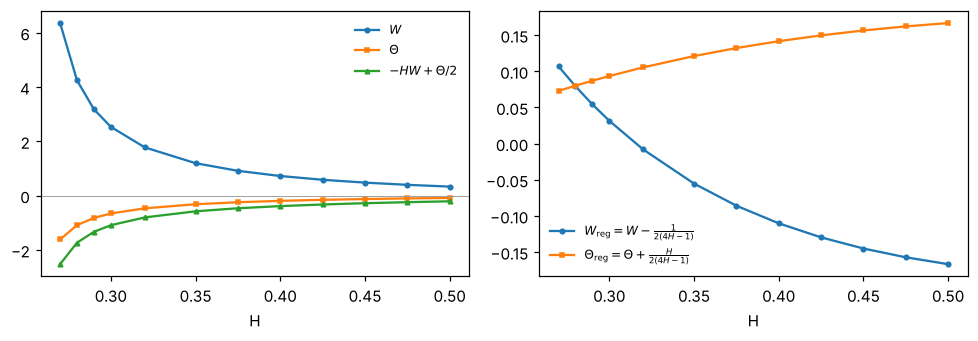

signs: W > 0 and Theta < 0 on the plotted grid: OK


In [45]:
Hs = np.array([0.27, 0.28, 0.29, 0.30, 0.32, 0.35, 0.375, 0.40, 0.425, 0.45, 0.475, 0.5])
WT = np.array([c_WTheta(H) for H in Hs])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(Hs, WT[:, 0], "o-", ms=3, label=r"$W$")
ax[0].plot(Hs, WT[:, 1], "s-", ms=3, label=r"$\Theta$")
ax[0].plot(Hs, -Hs * WT[:, 0] + 0.5 * WT[:, 1], "^-", ms=3, label=r"$-HW+\Theta/2$")
ax[0].axhline(0, color="0.6", lw=0.6); ax[0].set_xlabel("H"); ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(Hs, WT[:, 0] - 1 / (2 * (4 * Hs - 1)), "o-", ms=3, label=r"$W_{\rm reg}=W-\frac{1}{2(4H-1)}$")
ax[1].plot(Hs, WT[:, 1] + Hs / (2 * (4 * Hs - 1)), "s-", ms=3, label=r"$\Theta_{\rm reg}=\Theta+\frac{H}{2(4H-1)}$")
ax[1].set_xlabel("H"); ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
print("signs: W > 0 and Theta < 0 on the plotted grid:", c_verdict(bool((WT[:, 0] > 0).all() and (WT[:, 1] < 0).all())))

### The separation constant $\kappa_{\rm sep}$ (Proposition 8.3)

The paper quotes no decimal values of $\kappa_{\rm sep}$, only the closed form
$\kappa_{\rm sep}(H)=\tfrac16-\tfrac2{(2H+1)(2H+2)}$, its definition
$\kappa_{\rm sep}=\int_{u<v}b_H(u,v)(v-u)\,\mathrm du\,\mathrm dv$ with
$b_H=c_H|u-v|^{2H-2}-f(u)-f(v)+1$, $f(u)=H(u^{2H-1}+(1-u)^{2H-1})$, the zero cell mean
$\int_{u<v}b_H=0$ (Step 3), $\kappa_{\rm sep}(\tfrac12)=-\tfrac16$, and $\kappa_{\rm sep}<0$ on $[\tfrac12,1)$ with
its only zero at $H=1$. Remark 8.12 adds $\int_0^1B_H(u,u)\,\mathrm du=-\kappa_{\rm sep}(H)$.
We check all of these by quadrature (same triangle parametrisation as above) and list a few values.

In [46]:
def c_kappa_sep(H):
    return 1 / 6 - 2 / ((2 * H + 1) * (2 * H + 2))


def c_tri_int(fun, H, h=1 / 32):
    """Integral over u<v of fun(u,uc,v,vc,r), with the diagonal substitution s = z^{1/(2H-1)}
    (H > 1/2) so that r^{2H-2} becomes regular."""
    x, xc, w = c_tanhsinh(h)
    p = 1 / (2 * H - 1)
    s = np.maximum(x ** p, 1e-300)
    sc = -np.expm1(p * np.log1p(-np.minimum(xc, 1 - 1e-16)))
    ws = w * p * x ** (p - 1)
    U, S = np.meshgrid(x, s, indexing="ij"); UC, SC = np.meshgrid(xc, sc, indexing="ij")
    R = S * UC
    return np.sum(np.outer(w, ws) * UC * fun(U, UC, U + R, UC * SC, R))


def c_bH(u, uc, v, vc, r, H):
    f = lambda y, yc: H * (y ** (2 * H - 1) + yc ** (2 * H - 1))
    return H * (2 * H - 1) * r ** (2 * H - 2) - f(u, uc) - f(v, vc) + 1


def c_BHdiag(u, H):
    C1 = 0.5 * (u ** (2 * H) + 1 - (1 - u) ** (2 * H))
    return u ** (2 * H) - 2 * u * C1 + u ** 2


c_ksep_ok = True
print(f"{'H':>5} | {'kappa_sep closed':>17} | {'int b_H (v-u)':>14} | {'int b_H':>9} | {'-int B_H(u,u)':>14}")
for H in [0.55, 0.6, 0.7, 0.8, 0.9, 0.95]:
    k1 = c_kappa_sep(H)
    k2 = c_tri_int(lambda u, uc, v, vc, r: c_bH(u, uc, v, vc, r, H) * r, H)
    z0 = c_tri_int(lambda u, uc, v, vc, r: c_bH(u, uc, v, vc, r, H), H)
    k3 = -integrate.quad(lambda u: c_BHdiag(u, H), 0, 1, epsabs=1e-14)[0]
    ok = abs(k1 - k2) < 1e-9 and abs(z0) < 1e-9 and abs(k1 - k3) < 1e-12
    c_ksep_ok &= ok
    print(f"{H:>5} | {k1:17.12f} | {k2:14.10f} | {z0:9.1e} | {k3:14.12f}   {c_verdict(ok)}")
for H in [0.3, 0.4, 0.5]:   # the diagonal identity also holds below the crossover
    k3 = -integrate.quad(lambda u: c_BHdiag(u, H), 0, 1, epsabs=1e-14)[0]
    ok = abs(c_kappa_sep(H) - k3) < 1e-12
    c_ksep_ok &= ok
    print(f"{H:>5} | {c_kappa_sep(H):17.12f} | {'':>14} | {'':>9} | {k3:14.12f}   {c_verdict(ok)}")
Hf = np.linspace(0.5, 0.999999, 20001)
ok = abs(c_kappa_sep(0.5) + 1 / 6) < 1e-15 and (c_kappa_sep(Hf) < 0).all() and abs(c_kappa_sep(1.0)) < 1e-15
c_ksep_ok &= ok
print(f"kappa_sep(1/2) = {c_kappa_sep(0.5):.15f} (paper -1/6); negative on [1/2,1); zero at H=1:  {c_verdict(ok)}")
lim = c_kappa_sep(0.5) * np.array([-0.5, 1, -0.5])
ok = np.allclose(lim, [1 / 12, -1 / 6, 1 / 12])
c_ksep_ok &= ok
print(f"lim_(H->1/2) kappa_sep (-1/2, 1, -1/2) = {lim}  (Remark 8.5: (1/12, -1/6, 1/12))  {c_verdict(ok)}")
print("kappa_sep checks:", c_verdict(c_ksep_ok))

    H |  kappa_sep closed |  int b_H (v-u) |   int b_H |  -int B_H(u,u)
 0.55 |   -0.140552995392 |  -0.1405529954 |   4.2e-17 | -0.140552995392   OK
  0.6 |   -0.117424242424 |  -0.1174242424 |   1.4e-17 | -0.117424242424   OK
  0.7 |   -0.078431372549 |  -0.0784313725 |  -1.4e-17 | -0.078431372549   OK
  0.8 |   -0.047008547009 |  -0.0470085470 |  -2.1e-17 | -0.047008547008   OK
  0.9 |   -0.021303258145 |  -0.0213032581 |  -1.0e-17 | -0.021303258145   OK
 0.95 |   -0.010167992927 |  -0.0101679929 |  -2.6e-17 | -0.010167992927   OK
  0.3 |   -0.314102564103 |                |           | -0.314102564103   OK
  0.4 |   -0.230158730159 |                |           | -0.230158730159   OK
  0.5 |   -0.166666666667 |                |           | -0.166666666667   OK
kappa_sep(1/2) = -0.166666666666667 (paper -1/6); negative on [1/2,1); zero at H=1:  OK
lim_(H->1/2) kappa_sep (-1/2, 1, -1/2) = [ 0.08333333 -0.16666667  0.08333333]  (Remark 8.5: (1/12, -1/6, 1/12))  OK
kappa_sep checks: OK


### The Brownian separation (Proposition 8.4)

**Claim.** At $H=\tfrac12$ and for every $n$, $\mu(P_1)-\mu(P_0)=\delta\,D_{\rm sep}(\epsilon)$ with
$D_{\rm sep}=(\tfrac x{12},\tfrac{x^2}{24},-\tfrac x{12}-\tfrac{x^2}{24})$ for (adj, alt, nest), $x=\epsilon^2$, and
$\delta(2\sum_\bullet D_{{\rm sep},\bullet}^2)^{1/2}=\tfrac{\epsilon^2}6\delta(1+O(\epsilon^2))$.

**Method (independent of the proof).** Under $P_1$ the covariance on $[0,1]$ is
$\min(s,t)+x\,\delta\,(\min(u,v)-uv)$ for $s,t$ in the same block (block coordinates $u,v$) and $\min(s,t)$
otherwise. For the piecewise-linear interpolant of a centred Gaussian path with i.i.d. components on
a fine mesh of $N$ cells, Chen's identity and Isserlis' theorem give the level-4 coordinates exactly:
$E_{\rm adj}=\sum_{c_1\le c_2\le c_3\le c_4}w(c)\,\Sigma_{c_1c_2}\Sigma_{c_3c_4}$, and likewise with the pairs
$(c_1c_3)(c_2c_4)$ and $(c_1c_4)(c_2c_3)$, where $\Sigma$ is the covariance matrix of the fine increments
and $w(c)=\prod1/(\text{multiplicity})!$ comes from the tensor exponential of each linear piece. The
covariances are piecewise polynomial, so the fine-mesh values are polynomials in $1/k$ ($k$ fine cells
per block). A polynomial fit through four values of $k$ gives the limit $k\to\infty$ up to rounding;
a fifth value checks the fit.

In [47]:
def c_quads(N):
    c = np.array(list(itertools.combinations_with_replacement(range(N), 4)))
    w = np.ones(len(c)); run = np.ones(len(c), dtype=int)
    for j in range(1, 4):
        same = c[:, j] == c[:, j - 1]
        run = np.where(same, run + 1, 1)
        w = np.where(same, w / run, w)
    return c, w


def c_E22(Sig, c, w):
    return np.array([np.sum(w * Sig[c[:, 0], c[:, 1]] * Sig[c[:, 2], c[:, 3]]),
                     np.sum(w * Sig[c[:, 0], c[:, 2]] * Sig[c[:, 1], c[:, 3]]),
                     np.sum(w * Sig[c[:, 0], c[:, 3]] * Sig[c[:, 1], c[:, 2]])])


def c_inc_cov(Cf, t):
    return np.diff(np.diff(Cf(t[:, None], t[None, :]), axis=0), axis=1)


def c_cov_P1_half(s, t, n, x):
    a = np.floor(s * n - 1e-12).clip(0, n - 1); b = np.floor(t * n - 1e-12).clip(0, n - 1)
    u, v = s * n - a, t * n - b
    return np.minimum(s, t) + x * np.where(a == b, (np.minimum(u, v) - u * v) / n, 0.0)


# sanity check of the Wick sum: Brownian motion on N cells gives E<1122> = 1/8 - 1/(12N) exactly
c, w = c_quads(6)
e = c_E22(c_inc_cov(np.minimum, np.arange(7) / 6), c, w)
print(f"BM, N=6: E_adj = {e[0]:.15f}, formula 1/8 - 1/(12N) = {1 / 8 - 1 / 72:.15f}  ",
      c_verdict(abs(e[0] - (1 / 8 - 1 / 72)) < 1e-15))

c_sepb_ok = True
for n in [1, 2, 3]:
    for x in [0.3, 1.0]:
        ks = [4, 8, 12, 16, 20] if n == 1 else [2, 4, 6, 8, 10]
        diffs = []
        for k in ks:
            N = n * k
            t = np.arange(N + 1) / N
            c, w = c_quads(N)
            d1 = c_E22(c_inc_cov(lambda s, tt: c_cov_P1_half(s, tt, n, x), t), c, w)
            d0 = c_E22(c_inc_cov(np.minimum, t), c, w)
            diffs.append(d1 - d0)
        diffs = np.array(diffs); hh = 1 / np.array(ks, float)
        lim4 = np.linalg.solve(np.vander(hh[:4], 4, increasing=True), diffs[:4])[0]
        lim5 = np.linalg.solve(np.vander(hh, 5, increasing=True), diffs)[0]
        target = np.array([x / 12, x ** 2 / 24, -x / 12 - x ** 2 / 24]) / n
        ok = np.allclose(lim4, target, atol=1e-12) and np.allclose(lim5, target, atol=1e-11)
        c_sepb_ok &= ok
        print(f"n={n}, x={x}: limit (adj, alt, nest) = {np.array2string(lim4, precision=12)},"
              f"  delta*D_sep = {np.array2string(target, precision=12)}  {c_verdict(ok)}")
for x in [1e-2, 1e-3]:
    D = np.array([x / 12, x ** 2 / 24, -x / 12 - x ** 2 / 24])
    print(f"x={x}: (2 sum D^2)^(1/2) / (x/6) = {np.sqrt(2 * np.sum(D ** 2)) / (x / 6):.6f}  (-> 1 as x -> 0)")
# Remark 8.12 at H=1/2: the x-term of the nested coordinate is x/12 - x/6 = -x/12
# (W(1/2)=1/3, so -x H W = -x/6; the delta^{2H} term (x/4) * 2 * int v_R = x delta/12), and the x^2-term
# Theta/2 = -1/24
print("Remark 8.12 at H=1/2: x/12 - x*(1/2)*W(1/2) =", 1 / 12 - 0.5 * c_WTheta(0.5)[0],
      "(should be -1/12);  Theta(1/2)/2 =", 0.5 * c_WTheta(0.5)[1], "(should be -1/24)")
print("Brownian separation:", c_verdict(c_sepb_ok))
print(f"[C2 done, {time.time() - c_T0:.1f} s]")

BM, N=6: E_adj = 0.111111111111111, formula 1/8 - 1/(12N) = 0.111111111111111   OK
n=1, x=0.3: limit (adj, alt, nest) = [ 0.025    0.00375 -0.02875],  delta*D_sep = [ 0.025    0.00375 -0.02875]  OK
n=1, x=1.0: limit (adj, alt, nest) = [ 0.083333333333  0.041666666667 -0.125         ],  delta*D_sep = [ 0.083333333333  0.041666666667 -0.125         ]  OK
n=2, x=0.3: limit (adj, alt, nest) = [ 0.0125    0.001875 -0.014375],  delta*D_sep = [ 0.0125    0.001875 -0.014375]  OK
n=2, x=1.0: limit (adj, alt, nest) = [ 0.041666666667  0.020833333333 -0.0625        ],  delta*D_sep = [ 0.041666666667  0.020833333333 -0.0625        ]  OK


n=3, x=0.3: limit (adj, alt, nest) = [ 0.008333333333  0.00125        -0.009583333333],  delta*D_sep = [ 0.008333333333  0.00125        -0.009583333333]  OK
n=3, x=1.0: limit (adj, alt, nest) = [ 0.027777777778  0.013888888889 -0.041666666667],  delta*D_sep = [ 0.027777777778  0.013888888889 -0.041666666667]  OK
x=0.01: (2 sum D^2)^(1/2) / (x/6) = 1.002509  (-> 1 as x -> 0)
x=0.001: (2 sum D^2)^(1/2) / (x/6) = 1.000250  (-> 1 as x -> 0)
Remark 8.12 at H=1/2: x/12 - x*(1/2)*W(1/2) = -0.08333333333333336 (should be -1/12);  Theta(1/2)/2 = -0.04166666666666667 (should be -1/24)
Brownian separation: OK
[C2 done, 12.3 s]


## C3. Monte Carlo illustration of the strong rate (Proposition 7.4)

**Claim.** For fBm drivers with $H\in(\tfrac12,1)$ and $M\ge2$, the mean-square strong error satisfies
$\eta_\delta^2=\mathbb E\|\mathrm{Sig}^{\le M}(X^n)-\mathrm{Sig}^{\le M}(X)\|^2_{\rm HS}\asymp\delta^{4H-1}$. The paper quotes no
numbers for it; this section is a **Monte Carlo illustration**, not a reproduction of a quoted value.

**Method.** We sample $d=2$ independent fBm paths exactly on a fine mesh $1/N_f$ (circulant embedding),
use the signature of the fine piecewise-linear path as the reference for $\mathrm{Sig}(X)$, and compare it
with the signature of the coarse interpolant $X^n$ ($n$ cells, $N_f/n\ge16$ fine cells per coarse cell).
We report the mean-square error of the truncations $M=2$ and $M=3$, and fit the slope of
$\log\eta^2_\delta$ against $\log\delta$.

**Exact control at level 2.** The level-2 defect is $\pm\sum_aA_a$ in the coordinates $12$, $21$ (and $0$
elsewhere), where $A_a$ is the Lévy area of the fine path over the coarse cell $I_a$ (formula eq. (53)).
So, exactly, $\mathbb E\|\text{level-2 defect}\|^2=2\,\delta^{4H}\sum_{|m|<n}(n-|m|)\,\rho^{(k)}_A(m)$, with
$k=N_f/n$ and $\rho^{(k)}_A$ the fine-mesh Isserlis sum of C1. The Monte Carlo values for $M=2$ are checked
against this, and with $\rho^{(k)}_A$ replaced by $\rho_A$ it tends to $2\sigma^2_\infty\delta^{4H-1}$.

Monte Carlo: 2000 paths, fine mesh 1/512, coarse meshes n = [4, 8, 16, 32]


H=0.6: fitted mean-square slopes  M=2: 1.361   M=3: 1.407   exact level 2: 1.415   (4H-1 = 1.4);  MC vs exact level 2: max |z| = 2.8  [0.5 s]
     n=   4: M=2 MC 4.6955e-02  exact 4.7834e-02   M=3 MC 1.3824e-01   ratio M=3/M=2 2.94
     n=   8: M=2 MC 1.8079e-02  exact 1.8053e-02   M=3 MC 5.1489e-02   ratio M=3/M=2 2.85
     n=  16: M=2 MC 7.0969e-03  exact 6.7848e-03   M=3 MC 1.9550e-02   ratio M=3/M=2 2.75
     n=  32: M=2 MC 2.7637e-03  exact 2.5205e-03   M=3 MC 7.4031e-03   ratio M=3/M=2 2.68


H=0.7: fitted mean-square slopes  M=2: 1.769   M=3: 1.821   exact level 2: 1.813   (4H-1 = 1.8);  MC vs exact level 2: max |z| = 1.9  [0.4 s]
     n=   4: M=2 MC 1.6868e-02  exact 1.7425e-02   M=3 MC 4.6781e-02   ratio M=3/M=2 2.77
     n=   8: M=2 MC 4.6793e-03  exact 4.9709e-03   M=3 MC 1.2739e-02   ratio M=3/M=2 2.72
     n=  16: M=2 MC 1.4046e-03  exact 1.4179e-03   M=3 MC 3.5373e-03   ratio M=3/M=2 2.52
     n=  32: M=2 MC 4.2319e-04  exact 4.0172e-04   M=3 MC 1.0670e-03   ratio M=3/M=2 2.52


H=0.8: fitted mean-square slopes  M=2: 2.252   M=3: 2.286   exact level 2: 2.219   (4H-1 = 2.2);  MC vs exact level 2: max |z| = 1.0  [0.5 s]
     n=   4: M=2 MC 5.7179e-03  exact 5.5641e-03   M=3 MC 1.5108e-02   ratio M=3/M=2 2.64
     n=   8: M=2 MC 1.2355e-03  exact 1.1905e-03   M=3 MC 3.1591e-03   ratio M=3/M=2 2.56
     n=  16: M=2 MC 2.4996e-04  exact 2.5628e-04   M=3 MC 6.4208e-04   ratio M=3/M=2 2.57
     n=  32: M=2 MC 5.3581e-05  exact 5.5102e-05   M=3 MC 1.3062e-04   ratio M=3/M=2 2.44


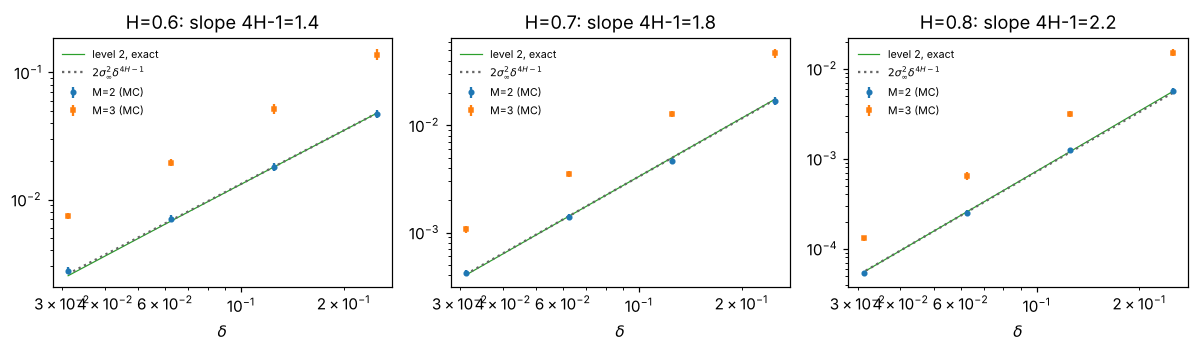

(Monte Carlo illustration: no value is quoted in the paper, so there is no OK/MISMATCH verdict for the slopes; the level-2 Monte Carlo agrees with the exact formula within the stated |z|.)
[C3 done, 14.4 s]


In [48]:
if QUICK:
    c_P, c_Nf, c_ns, c_batch = 2000, 512, [4, 8, 16, 32], 1000
else:
    c_P, c_Nf, c_ns, c_batch = 20000, 2048, [4, 8, 16, 32, 64, 128], 1000
print(f"Monte Carlo: {c_P} paths, fine mesh 1/{c_Nf}, coarse meshes n = {c_ns}")


def c_mc_strong(H, rng):
    e2 = {n: [] for n in c_ns}; e3 = {n: [] for n in c_ns}
    for b in range(c_P // c_batch):
        inc = fbm_increments(H, c_Nf, c_batch, 2, rng)
        Sf = sig_pl(inc, 3)
        for n in c_ns:
            Sc = sig_pl(inc.reshape(c_batch, n, c_Nf // n, 2).sum(2), 3)
            l2 = np.sum((Sc[1] - Sf[1]) ** 2, axis=(1, 2))
            l3 = np.sum((Sc[2] - Sf[2]) ** 2, axis=(1, 2, 3))
            e2[n].append(l2); e3[n].append(l2 + l3)
    out = {}
    for n in c_ns:
        a2, a3 = np.concatenate(e2[n]), np.concatenate(e3[n])
        out[n] = (a2.mean(), a2.std() / np.sqrt(len(a2)), a3.mean(), a3.std() / np.sqrt(len(a3)))
    return out


def c_exact_level2(H, n, k):
    rho = np.array([c_rhoA_discrete(m, H, k) for m in range(n)])
    lags = np.arange(n)
    return 2 * (1 / n) ** (4 * H) * (n * rho[0] + 2 * np.sum((n - lags[1:]) * rho[1:]))


c_rng = np.random.default_rng(20261102)
c_mc = {}
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3), sharey=False)
for ax, H in zip(axs, [0.6, 0.7, 0.8]):
    t0 = time.time()
    res = c_mc_strong(H, c_rng)
    c_mc[H] = res
    d = 1 / np.array(c_ns, float)
    m2 = np.array([res[n][0] for n in c_ns]); s2 = np.array([res[n][1] for n in c_ns])
    m3 = np.array([res[n][2] for n in c_ns]); s3 = np.array([res[n][3] for n in c_ns])
    ex2 = np.array([c_exact_level2(H, n, c_Nf // n) for n in c_ns])
    sl2 = np.polyfit(np.log(d), np.log(m2), 1)[0]
    sl3 = np.polyfit(np.log(d), np.log(m3), 1)[0]
    slx = np.polyfit(np.log(d), np.log(ex2), 1)[0]
    zmax = np.max(np.abs(m2 - ex2) / s2)
    print(f"H={H}: fitted mean-square slopes  M=2: {sl2:.3f}   M=3: {sl3:.3f}   exact level 2: {slx:.3f}"
          f"   (4H-1 = {4 * H - 1:.1f});  MC vs exact level 2: max |z| = {zmax:.1f}  [{time.time() - t0:.1f} s]")
    for n, a, b, c_ in zip(c_ns, m2, ex2, m3):
        print(f"     n={n:4d}: M=2 MC {a:.4e}  exact {b:.4e}   M=3 MC {c_:.4e}   ratio M=3/M=2 {c_ / a:.2f}")
    ax.errorbar(d, m2, yerr=2 * s2, fmt="o", ms=3, label="M=2 (MC)")
    ax.errorbar(d, m3, yerr=2 * s3, fmt="s", ms=3, label="M=3 (MC)")
    ax.plot(d, ex2, "-", lw=0.8, label="level 2, exact")
    ax.plot(d, 2 * c_sig2.get(H, c_sigma2_parts(H)[2]) * d ** (4 * H - 1), ":", color="0.4",
            label=r"$2\sigma^2_\infty\delta^{4H-1}$")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"$\delta$")
    ax.set_title(f"H={H}: slope 4H-1={4 * H - 1:.1f}")
    ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); plt.show()
print("(Monte Carlo illustration: no value is quoted in the paper, so there is no OK/MISMATCH verdict"
      " for the slopes; the level-2 Monte Carlo agrees with the exact formula within the stated |z|.)")
print(f"[C3 done, {time.time() - c_T0:.1f} s]")

## C4. Other explicit constants in Sections 7–9 and the appendices

The paper quotes no further decimal values in Sections 7–9 or in Appendices A and B. The remaining
explicit constants are elementary identities used in the proofs. We check each by quadrature or
by evaluation on a fine grid:

* Lemma 7.1, Step 3: the moments $\int\sigma=0$, $\int\sigma u_1=-\tfrac16$, $\int\sigma u_2=\tfrac16$ of
  $\sigma(u)=\mathrm{sgn}(u_2-u_1)$ on $[0,1]^2$, and the two integrals $\tfrac2{36}$ and $-\tfrac4{36}$.
* Lemma 7.7: $v=\int_0^1\mathbb E(\tfrac12B_1-B_s)^2\,\mathrm ds=\tfrac1{2H+1}-\tfrac14$, and
  $\mathrm{Var}(\tilde A_0)=\tfrac14$ at $H=\tfrac12$.
* Proposition 8.3, Step 7: the five elementary beta integrals.
* Remark 8.8 and Remark 8.7: $\int_{[0,1]^2}\partial_1D\,\partial_2D=-\tfrac{2H}{4H-1}$,
  $E^\infty_{\rm adj}=\tfrac H2\mathrm B(2H+1,2H)$, and $\Xi(\tau)=4H(1-\tau)\tau^{4H-1}$ for $D=|t-s|^{2H}$.
* Appendix A (Remarks A.1, Remark A.2): $\int_0^1f=1$; $|g|=|1-f(u)-f(v)|\le1+4H$ for $H>\tfrac12$;
  $B_H(u,u)\le\min(u,1-u)^{2H}$; $D_B=(v-u)^{2H}-(v-u)\Lambda+(v-u)^2$ with $\Lambda\in[0,2]$ and $D_B\le2(v-u)^{2H}$.
* Appendix B: the three forms of $\kappa_{\rm alt}$ (Proposition 6.16, Proposition 6.13,
  Corollary B.5) agree; the closed forms of $T(h)$, $U(h)$; the bound
  $0<\zeta(s)-1\le2^{-s}(1+\tfrac2{s-1})$; the tails $O(4^{-J})$ and $O(J^{-2H})$.

In [49]:
c_C4 = []


def c_check(name, ok, detail=""):
    c_C4.append(bool(ok))
    print(f"  {name:<72s} {detail}  {c_verdict(ok)}")


print("Lemma 7.1, Step 3")
x, xc, w = c_tanhsinh(1 / 64)
# integrate monomials against sigma(u) = sgn(u2-u1) exactly: on u1<u2 (+), u1>u2 (-)
U1, S = np.meshgrid(x, x, indexing="ij")
UC1 = np.meshgrid(xc, xc, indexing="ij")[0]
Wt = np.outer(w, w) * UC1                    # u2 = u1 + s(1-u1) on the upper triangle
U2 = U1 + S * UC1
mom = lambda g: np.sum(Wt * (g(U1, U2) - g(U2, U1)))    # int sigma(u) g(u1,u2) du
c_check("int sigma = 0", abs(mom(lambda a, b: 1 + 0 * a)) < 1e-14)
c_check("int sigma u1 = -1/6", abs(mom(lambda a, b: a) + 1 / 6) < 1e-14)
c_check("int sigma u2 = 1/6", abs(mom(lambda a, b: b) - 1 / 6) < 1e-14)
m1, m2_ = mom(lambda a, b: a), mom(lambda a, b: b)
# xy = v1 v2 - v1 u2 - u1 v2 + u1 u2: product moments factorise
xy = -(m1 * m2_) - (m1 * m2_)
x2y2 = -2 * m1 * m1 - 2 * m2_ * m2_
c_check("iint sigma sigma xy = 2/36", abs(xy - 2 / 36) < 1e-14)
c_check("iint sigma sigma (x^2+y^2) = -4/36", abs(x2y2 + 4 / 36) < 1e-14)

print("Lemma 7.7")
for H in [0.3, 0.4, 0.5]:
    v = integrate.quad(lambda s: -0.25 + 0.5 * s ** (2 * H) + 0.5 * (1 - s) ** (2 * H), 0, 1)[0]
    c_check(f"v = 1/(2H+1) - 1/4 > 0 at H={H}", abs(v - (1 / (2 * H + 1) - 0.25)) < 1e-12 and v > 0, f"{v:.10f}")
c_check("Var(A_0) = 2(E_adj - E_nest) = 1/4 at H=1/2", abs(c_rhoA0(0.5) - 0.25) < 1e-15)

print("Proposition 8.3, Step 7 (H = 0.7)")
H = 0.7
tri = lambda g: integrate.dblquad(lambda v, u: g(u, v), 0, 1, lambda u: u, 1, epsabs=1e-13, epsrel=1e-13)[0]
c_check("int_{u<v} (v-u)^{2H-1} = 1/(2H(2H+1))", abs(tri(lambda u, v: (v - u) ** (2 * H - 1)) - 1 / (2 * H * (2 * H + 1))) < 1e-10)
c_check("int_{u<v} (v-u) u^{2H-1} = 1/(2H(2H+1)(2H+2))",
        abs(tri(lambda u, v: (v - u) * u ** (2 * H - 1)) - 1 / (2 * H * (2 * H + 1) * (2 * H + 2))) < 1e-10)
c_check("int_{u<v} (v-u)(1-v)^{2H-1} = same",
        abs(tri(lambda u, v: (v - u) * (1 - v) ** (2 * H - 1)) - 1 / (2 * H * (2 * H + 1) * (2 * H + 2))) < 1e-10)
c_check("int_{u<v} (v-u) v^{2H-1} = 1/(2(2H+2))", abs(tri(lambda u, v: (v - u) * v ** (2 * H - 1)) - 1 / (2 * (2 * H + 2))) < 1e-10)
c_check("int_{u<v} (v-u)(1-u)^{2H-1} = same", abs(tri(lambda u, v: (v - u) * (1 - u) ** (2 * H - 1)) - 1 / (2 * (2 * H + 2))) < 1e-10)
c_check("int_{u<v} (v-u) = 1/6", abs(tri(lambda u, v: v - u) - 1 / 6) < 1e-12)
kk = (2 * H - 1) / (2 * (2 * H + 1)) - (2 * H ** 2 + H + 1) / ((2 * H + 1) * (2 * H + 2)) + 1 / 6
c_check("middle expression of Step 7 = 1/6 - 2/((2H+1)(2H+2))", abs(kk - c_kappa_sep(H)) < 1e-15)

print("Remarks 8.8 and Remark 8.7")
for H in [0.3, 0.7]:
    I = 2 * integrate.quad(lambda r: (1 - r) * r ** (4 * H - 2), 0, 1, epsabs=1e-13)[0]   # int |t-s|^{4H-2}
    c_check(f"int d1D d2D = -4H^2 int|t-s|^(4H-2) = -2H/(4H-1) at H={H}", abs(-4 * H ** 2 * I + 2 * H / (4 * H - 1)) < 1e-9)
    Ea = H / 2 * float(mp.beta(2 * H + 1, 2 * H))
    Ea2 = 0.5 * integrate.quad(lambda t: t ** (2 * H) * H * (t ** (2 * H - 1) + (1 - t) ** (2 * H - 1) - t ** (2 * H - 1)), 0, 1)[0]
    c_check(f"E_adj = (1/2) int v [C(1,t)' - v'/2] = (H/2) B(2H+1,2H) = closed form at H={H}",
            abs(Ea - c_Einf(H)[0]) < 1e-14 and abs(Ea2 - Ea) < 1e-9)
    c_check(f"E_nest = 1/8 - 2H/(8(4H-1)) at H={H}", abs(1 / 8 - 2 * H / (8 * (4 * H - 1)) - c_Einf(H)[2]) < 1e-15)
    tau = 0.01
    Xi = integrate.quad(lambda s: tau ** (2 * H) * 2 * (2 * H * tau ** (2 * H - 1)), 0, 1 - tau)[0]
    c_check(f"Xi(tau) = 4H(1-tau) tau^(4H-1) for D=|t-s|^(2H), tau=0.01, H={H}",
            abs(Xi - 4 * H * (1 - tau) * tau ** (4 * H - 1)) < 1e-14)

print("Appendix A (grid of 400 x 400 points, H in {0.3, 0.4, 0.5, 0.6, 0.8})")
g1 = (np.arange(400) + 0.5) / 400
Ug, Vg = np.meshgrid(g1, g1, indexing="ij")
up = Ug < Vg
for H in [0.3, 0.4, 0.5, 0.6, 0.8]:
    fH = lambda y: H * (y ** (2 * H - 1) + (1 - y) ** (2 * H - 1))
    intf = integrate.quad(fH, 0, 1)[0]
    Cf = lambda s, t: 0.5 * (np.abs(s) ** (2 * H) + np.abs(t) ** (2 * H) - np.abs(t - s) ** (2 * H))
    BH = lambda s, t: Cf(s, t) - s * Cf(t, 1) - t * Cf(s, 1) + s * t
    DB = BH(Ug, Ug) + BH(Vg, Vg) - 2 * BH(Ug, Vg)
    r = np.abs(Vg - Ug)
    Lam = Vg ** (2 * H) - Ug ** (2 * H) + (1 - Ug) ** (2 * H) - (1 - Vg) ** (2 * H)
    DBf = r ** (2 * H) - r * Lam + r ** 2
    diag = BH(g1, g1)
    ok = (abs(intf - 1) < 1e-10
          and np.max(np.abs(DB - DBf)[up]) < 1e-12
          and Lam[up].min() >= 0 and Lam[up].max() <= 2
          and np.all(DB[up] <= 2 * r[up] ** (2 * H) + 1e-15)
          and np.all(diag <= np.minimum(g1, 1 - g1) ** (2 * H) + 1e-15)
          and np.all(diag - g1 ** (2 * H) <= 1e-15)
          and np.allclose(diag, diag[::-1]))
    if H > 0.5:
        G = 1 - fH(Ug) - fH(Vg)
        ok = ok and np.abs(G).max() <= 1 + 4 * H
    c_check(f"H={H}: int f=1, D_B formula, Lambda in [0,2], D_B<=2r^(2H), B_H(u,u)<=min(u,1-u)^(2H), |g|<=1+4H", ok)

print("Appendix B (H = 0.3 and 0.4)")
mp.mp.dps = 30
for H in [0.3, 0.4]:
    Hm = mp.mpf(H)
    Uh = lambda h: -mp.mpf(1) / 4 * ((h + 1) ** (2 * Hm) - (h - 1) ** (2 * Hm))
    # sum_{h>=1} [U(h)^2 - H^2 h^{4H-2}]: direct for h < 40, and for h >= 40 the expansion
    # U(h) = sum_j alpha_j h^{2H-1-2j}, alpha_j = -binom(2H,2j+1)/2, summed with Hurwitz zeta
    al = [-mp.binomial(2 * Hm, 2 * j + 1) / 2 for j in range(30)]
    gam = [sum(al[j] * al[k - j] for j in range(k + 1)) for k in range(30)]
    head = sum(Uh(mp.mpf(h)) ** 2 - Hm ** 2 * mp.mpf(h) ** (4 * Hm - 2) for h in range(1, 40))
    tail = sum(gam[k] * mp.zeta(2 + 2 * k - 4 * Hm, 40) for k in range(1, 30))
    k_abs = Hm ** 2 * mp.zeta(2 - 4 * Hm) + head + tail
    bj = lambda j: abs(mp.binomial(2 * Hm, j))
    k_geo = mp.mpf(1) / 16 + mp.nsum(lambda j: bj(j) * (mp.zeta(2 * j - 4 * Hm) - 1), [1, mp.inf]) / 8
    J = 400
    k_raw = -mp.mpf(1) / 16 + sum(bj(j) * mp.zeta(2 * j - 4 * Hm) for j in range(1, J + 1)) / 8
    c_check(f"H={H}: Prop. 6.16 form = Cor. B.5 form", abs(k_abs - k_geo) < 1e-20,
            f"kappa_alt = {mp.nstr(k_abs, 15)}")
    c_check(f"H={H}: raw zeta series after J={J} terms, error ~ J^(-2H)",
            abs(k_raw - k_geo) < 2 * J ** (-2 * H), f"error {float(abs(k_raw - k_geo)):.1e}")
    errs = []
    for Jg in [5, 10, 15]:
        part = mp.mpf(1) / 16 + sum(bj(j) * (mp.zeta(2 * j - 4 * Hm) - 1) for j in range(1, Jg + 1)) / 8
        errs.append(float(abs(part - k_geo)))
    c_check(f"H={H}: geometric form, error after J=5,10,15 terms ~ 4^-J", errs[2] < 4.0 ** -15 * 10 and errs[1] < 4.0 ** -10 * 10,
            f"{errs[0]:.1e}, {errs[1]:.1e}, {errs[2]:.1e}")
    h, Nt = 7, 10 ** 6
    # direct sum up to Nt, plus the tail sum_{m>Nt} r(m) from r(m) = c_H m^{2H-2}(1 + O(m^-2))
    T = np.sum(fgn_autocov(np.arange(h, Nt + 1), H)) + H * (2 * H - 1) * float(mp.zeta(2 - 2 * H, Nt + 1))
    Tform = -0.5 * (h ** (2 * H) - (h - 1) ** (2 * H))
    c_check(f"H={H}: T(7) = sum_(m>=7) r(m) = -(7^(2H) - 6^(2H))/2 (telescoping)",
            abs(T - Tform) < 1e-10, f"{T:.12f} vs {Tform:.12f}")
    c_check(f"H={H}: U(7) = T(7) - r(7)/2 = -((8)^(2H) - 6^(2H))/4",
            abs(Tform - 0.5 * fgn_autocov(7, H) - float(Uh(7))) < 1e-14)
mp.mp.dps = 15
s = np.linspace(2.01, 40, 2000)
zs = np.array([float(mp.zeta(si)) for si in s])
c_check("0 < zeta(s) - 1 <= 2^(-s)(1 + 2/(s-1)) for s in (2, 40]",
        np.all(zs - 1 > 0) and np.all(zs - 1 <= 2.0 ** (-s) * (1 + 2 / (s - 1))))
print("C4:", c_verdict(all(c_C4)), f"({sum(c_C4)}/{len(c_C4)} checks)")

Lemma 7.1, Step 3
  int sigma = 0                                                              OK
  int sigma u1 = -1/6                                                        OK
  int sigma u2 = 1/6                                                         OK
  iint sigma sigma xy = 2/36                                                 OK
  iint sigma sigma (x^2+y^2) = -4/36                                         OK
Lemma 7.7
  v = 1/(2H+1) - 1/4 > 0 at H=0.3                                          0.3750000000  OK
  v = 1/(2H+1) - 1/4 > 0 at H=0.4                                          0.3055555556  OK
  v = 1/(2H+1) - 1/4 > 0 at H=0.5                                          0.2500000000  OK
  Var(A_0) = 2(E_adj - E_nest) = 1/4 at H=1/2                                OK
Proposition 8.3, Step 7 (H = 0.7)
  int_{u<v} (v-u)^{2H-1} = 1/(2H(2H+1))                                      OK
  int_{u<v} (v-u) u^{2H-1} = 1/(2H(2H+1)(2H+2))                              OK
  int_{u<v} (v-u)(1-v)

  H=0.8: int f=1, D_B formula, Lambda in [0,2], D_B<=2r^(2H), B_H(u,u)<=min(u,1-u)^(2H), |g|<=1+4H   OK
Appendix B (H = 0.3 and 0.4)


  H=0.3: Prop. 6.16 form = Cor. B.5 form                                   kappa_alt = -0.341259261846546  OK
  H=0.3: raw zeta series after J=400 terms, error ~ J^(-2H)                error 1.5e-03  OK
  H=0.3: geometric form, error after J=5,10,15 terms ~ 4^-J                1.5e-06, 5.3e-10, 2.9e-13  OK
  H=0.3: T(7) = sum_(m>=7) r(m) = -(7^(2H) - 6^(2H))/2 (telescoping)       -0.141969899066 vs -0.141969899066  OK
  H=0.3: U(7) = T(7) - r(7)/2 = -((8)^(2H) - 6^(2H))/4                       OK


  H=0.4: Prop. 6.16 form = Cor. B.5 form                                   kappa_alt = -0.146875573852774  OK
  H=0.4: raw zeta series after J=400 terms, error ~ J^(-2H)                error 2.3e-04  OK
  H=0.4: geometric form, error after J=5,10,15 terms ~ 4^-J                9.1e-07, 2.9e-10, 1.4e-13  OK
  H=0.4: T(7) = sum_(m>=7) r(m) = -(7^(2H) - 6^(2H))/2 (telescoping)       -0.275156840587 vs -0.275156840587  OK
  H=0.4: U(7) = T(7) - r(7)/2 = -((8)^(2H) - 6^(2H))/4                       OK


  0 < zeta(s) - 1 <= 2^(-s)(1 + 2/(s-1)) for s in (2, 40]                    OK
C4: OK (40/40 checks)


## Summary of Part C

In [50]:
print("C1  Remark 7.3: sign of rho_A(m) on the grid ........", c_verdict(bool((c_G < 0).all())))
print("C1  Remark 7.3: table and lower-bound ratios .........", c_verdict(c_C1_ok))
print("C2  Remark 8.10: W and Theta table, Theta(1/2) = -1/12 .", c_verdict(c_C2_ok))
print("C2  Prop. 8.3: kappa_sep identities .....................", c_verdict(c_ksep_ok))
print("C2  Prop. 8.4: D_sep by brute-force Wick sums ....", c_verdict(c_sepb_ok))
print("C3  Prop. 7.4: Monte Carlo illustration (no quoted value)")
print("C4  other explicit constants of Sections 7-9 and Appendices ...", c_verdict(all(c_C4)))
print(f"Part C total time: {time.time() - c_T0:.1f} s ({'QUICK' if QUICK else 'FULL'} mode)")

C1  Remark 7.3: sign of rho_A(m) on the grid ........ OK
C1  Remark 7.3: table and lower-bound ratios ......... OK
C2  Remark 8.10: W and Theta table, Theta(1/2) = -1/12 . OK
C2  Prop. 8.3: kappa_sep identities ..................... OK
C2  Prop. 8.4: D_sep by brute-force Wick sums .... OK
C3  Prop. 7.4: Monte Carlo illustration (no quoted value)
C4  other explicit constants of Sections 7-9 and Appendices ... OK
Part C total time: 15.3 s (QUICK mode)


## Summary

| Part | Statement in the paper | What is reproduced |
|---|---|---|
| 0 | Introduction: signatures, Chen's identity, shuffle, expected signature of Brownian motion | exact checks and Monte Carlo illustrations |
| A1 | Theorem 5.3(i) | $\Delta E_\bullet=(-\tfrac1{12},\tfrac1{24},\tfrac1{24})\delta$ and $\lVert\mathcal W_4\rVert=\delta/(4\sqrt3)$, exactly on every mesh |
| A2 | Proposition 5.14, Remark 5.13 | leading constants $(-\tfrac1{12},\tfrac16,-\tfrac1{12})$, $\mathcal B=1/(2\sqrt3)$, by extrapolation |
| A3 | Remark 5.6 | the double-error terms have exact order $\delta^{4H-1}$, with opposite coefficients |
| A4 | Remark 5.13 | the relative error $\delta^{2H-1}$ appears only for the alternating and nested words |
| A5 | Proposition 5.18 and the numerical check after it | level-3 drift constants $\phi(\delta)(-\tfrac1{12},\tfrac16,-\tfrac1{12})$, also for sums of fBms |
| B1 | Remark 6.19 | the values of $\kappa_{\rm alt}(H)$, by three independent formulas |
| B2 | after Corollary 6.20 | the sign change of $\delta^{-(4H-1)}\Delta E_{\rm alt}$ at $H=0.48$ near $n=1.2\cdot10^3$ |
| B3 | Remark 6.27 | level 6 attains the order $\delta^{4H-1}$ below the crossover |
| B4 | Remark 6.7 | sharpness of the canonical-correlation bound |
| C1 | Remark 7.3 | $\rho_A(m)<0$, the table of $\rho_A(0)$, $2\sum_{m\ge1}\rho_A(m)$, $\sigma^2_\infty$, and the ratios $0.61, 0.56, 0.49$ |
| C2 | Remark 8.10 | the table of $W(H)$ and $\Theta(H)$, and the separation constants |
| C3 | Proposition 7.4 | Monte Carlo illustration of the strong rate $\delta^{4H-1}$ |
| C4 | Sections 7–9, Appendices | other explicit constants |